In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
import pandas as pd
from torch.utils.data import Dataset
import torch.nn.init as init
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import numpy as np
import os
import random
from PIL import Image
from torchvision import models, transforms, utils
from torchvision.transforms import v2
import re



import copy

# Verificar si CUDA está disponible
cuda_available = torch.cuda.is_available()

# Imprimir la versión de PyTorch y la disponibilidad de CUDA
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {cuda_available}")

# Imprimir el nombre de la GPU si CUDA está disponible
if cuda_available:
    print(f"GPU name: {torch.cuda.get_device_name(0)}")
    # Obtener la versión de CUDA
    cuda_version = torch.version.cuda
    print(f"CUDA version: {cuda_version}")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

PyTorch version: 2.2.0
CUDA available: True
GPU name: NVIDIA GeForce RTX 3050 Laptop GPU
CUDA version: 12.1
Using device: cuda


In [2]:
####CREACION DATASET

import os
import pandas as pd

# Directorio que contiene los archivos
directorio = './IMGS_MOSAIC'

# Obtener la lista de archivos en el directorio
archivos = os.listdir(directorio)

# Crear una lista para almacenar las rutas de los archivos y las etiquetas
data = []

# Iterar sobre los archivos
for archivo in archivos:
    # Obtener la ruta completa del archivo
    ruta_completa = os.path.join(directorio, archivo)
    # Obtener los elementos después de hacer split("_")
    elementos = archivo.split("_")
    # Obtener la etiqueta (cuarto elemento)
    etiqueta = elementos[3] if len(elementos) >= 4 else None
    # Agregar la ruta y la etiqueta a la lista de datos
    data.append((ruta_completa, int(etiqueta)))

# Crear el DataFrame de Pandas
df_mosaic = pd.DataFrame(data, columns=['Ruta', 'Etiqueta'])

# Mostrar el DataFrame
print(df_mosaic)

                             Ruta  Etiqueta
0   ./IMGS_MOSAIC\_P02_HVN_1_.jpg         1
1   ./IMGS_MOSAIC\_P08_HVN_1_.jpg         1
2   ./IMGS_MOSAIC\_P10_HVN_1_.jpg         1
3   ./IMGS_MOSAIC\_P12_HVN_0_.jpg         0
4   ./IMGS_MOSAIC\_P15_HVN_0_.jpg         0
5   ./IMGS_MOSAIC\_P17_HVN_0_.jpg         0
6   ./IMGS_MOSAIC\_P19_HVN_0_.jpg         0
7   ./IMGS_MOSAIC\_P20_HVN_0_.jpg         0
8   ./IMGS_MOSAIC\_P21_HVN_1_.jpg         1
9   ./IMGS_MOSAIC\_P22_HVN_1_.jpg         1
10  ./IMGS_MOSAIC\_P24_HVN_1_.jpg         1
11  ./IMGS_MOSAIC\_P25_HVN_0_.jpg         0
12  ./IMGS_MOSAIC\_P26_HVN_0_.jpg         0
13  ./IMGS_MOSAIC\_P27_HVN_1_.jpg         1
14  ./IMGS_MOSAIC\_P34_HVN_0_.jpg         0
15  ./IMGS_MOSAIC\_P47_HVN_0_.jpg         0
16  ./IMGS_MOSAIC\_P48_HVN_0_.jpg         0
17  ./IMGS_MOSAIC\_P50_H9O_1_.jpg         1
18  ./IMGS_MOSAIC\_P51_H9O_0_.jpg         0
19  ./IMGS_MOSAIC\_P52_H9O_1_.jpg         1
20  ./IMGS_MOSAIC\_P53_H9O_0_.jpg         0
21  ./IMGS_MOSAIC\_P54_H9O_1_.jp

## FUNCIÓN SIN TL SIN OC

In [3]:

def accuracy(outputs, labels):
    preds = outputs > 0.5  # Si la salida es mayor que 0.5, consideramos que es positiva
    correct = (preds == labels.byte())  # Compara las predicciones con las etiquetas reales
    acc = correct.float().sum() / labels.size(0)  # Calcula la precisión
    return acc.item()

def recall(outputs, labels):
    preds = outputs > 0.5

    preds = preds.cpu()
    labels = labels.cpu()
    TP = sum((preds == 1) & (labels == 1))
    FN = sum((preds == 0) & (labels == 1))

    recall_score = TP / (TP + FN) if (TP + FN) > 0 else 0
    return recall_score

def precision(outputs, labels):
    preds = outputs > 0.5

    preds = preds.cpu()
    labels = labels.cpu()

    TP = sum((preds == 1) & (labels == 1))
    FP = sum((preds == 1) & (labels == 0))

    precision_score = TP / (TP + FP) if (TP + FP) > 0 else 0
    return precision_score



def prueba_k_fold_resnet_no_pre(dataset, num_folds_outer, num_epochs, op, batch_size, lr, data_aug, ini, random_seed, seeds_tr_split):
    # Transformaciones para preprocesar las imágenes
    if data_aug:
        transform_t = v2.Compose([
            v2.Resize((224, 224)),
            # v2.RandomResizedCrop(224),
            v2.RandomHorizontalFlip(),
            v2.RandomVerticalFlip(),
            # v2.ElasticTransform(alpha=250.0),
            # v2.RandomRotation(45),
            # transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.2),
            v2.ToImage(),
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

        transform_v = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(),
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])
    else:
        transform_t = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(),
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

        transform_v = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(),
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

    # Modelo personalizado basado en ResNet
    class CustomResNet(nn.Module):
        def __init__(self, num_classes_binary=1):
            super(CustomResNet, self).__init__()
            resnet = models.resnet18(weights='IMAGENET1K_V1')
            # Extraer las capas de la red ResNet, excluyendo la capa de clasificación
            self.features = nn.Sequential(*list(resnet.children())[:-1])


            # Personalizar la capa de salida para tus necesidades
            self.fc_binary = nn.Linear(512, num_classes_binary)

            if (ini== "G"):
                # Inicialización de Glorot para las capas fully connected
                self.apply(self.init_weights_glorot)
            elif(ini == "H"):
                self.apply(self.init_weights_he)
            elif (ini== "N"):
                self.apply(self.init_weights_normal)
            elif(ini == "U"):
                self.apply(self.init_weights_uniform)
            elif (ini== "O"):
                self.apply(self.init_weights_orthogonal)
            elif(ini == "Z"):
                self.apply(self.init_weights_zeros)
            elif(ini == "ON"):
                self.apply(self.init_weights_ones)

        def init_weights_glorot(self, m):
            if isinstance(m, nn.Linear):
                init.xavier_uniform_(m.weight)
                if m.bias is not None:
                    init.constant_(m.bias, 0)

        def init_weights_he(self, m):
            if isinstance(m, nn.Linear):
                init.kaiming_uniform_(m.weight, mode='fan_in', nonlinearity='relu')
                if m.bias is not None:
                    init.constant_(m.bias, 0)
        def init_weights_normal(self, m):
            if isinstance(m, nn.Linear):
                init.normal_(m.weight, mean=0, std=0.01)  # Puedes ajustar la media y la desviación estándar según tus necesidades
                if m.bias is not None:
                    init.constant_(m.bias, 0)

        def init_weights_uniform(self, m):
            if isinstance(m, nn.Linear):
                init.uniform_(m.weight, a=-0.1, b=0.1)  # Puedes ajustar los límites inferior y superior según tus necesidades
                if m.bias is not None:
                    init.constant_(m.bias, 0)

        def init_weights_orthogonal(self, m):
            if isinstance(m, nn.Linear):
                init.orthogonal_(m.weight)  # Puedes ajustar el parámetro 'gain' según tus necesidades
                if m.bias is not None:
                    init.constant_(m.bias, 0)

        def init_weights_zeros(self, m):
            if isinstance(m, nn.Linear):
                init.zeros_(m.weight)
                if m.bias is not None:
                    init.zeros_(m.bias)

        def init_weights_ones(self, m):
            if isinstance(m, nn.Linear):
                init.ones_(m.weight)
                if m.bias is not None:
                    init.ones_(m.bias)

        def forward(self, x):
            x = self.features(x)
            x = x.view(x.size(0), -1)


            # Salida para la variable binaria
            out_binary = self.fc_binary(x)

            return out_binary

    # Definir una clase para el conjunto de datos personalizado
    ##adaptar esto para meter unas rutsa y obtener dataos y etiquetas
    class CustomDataset(Dataset):
        def __init__(self, dataframe, transform=None):
            self.data = dataframe
            self.transform = transform

        def __len__(self):
            return len(self.data)

        def __getitem__(self, idx):
            img_path = self.data.iloc[idx, 0]  # Ruta de la imagen en la primera columna
            image = Image.open(img_path).convert('RGB')
            # Etiquetas: una variable binaria
            label_binary = torch.tensor(self.data.iloc[idx, 1], dtype=torch.float32)

            if self.transform:
                image = self.transform(image)

            return image, label_binary

    #####5 fold CV
    from sklearn.model_selection import StratifiedKFold

    # Definir el número de folds
    criterion_binary = nn.BCEWithLogitsLoss()
    kf_outer = StratifiedKFold(n_splits=num_folds_outer, shuffle=True, random_state=random_seed)
    ##No será necesario el inner porque la partición será fija en 80%/20%
    # kf_inner = StratifiedKFold(n_splits=num_folds_inner, shuffle=True, random_state=14)
    # Listas para almacenar las pérdidas de entrenamiento y validación de cada fold
    accs = []
    recs = []
    precs = []
    

    
    # Aqui se itera sobre los folds outer, es decir, uno de los folds se usará para test, ya que el modelo no lo verá durante el entrenamiento.

    ##Por otro lado, la parte de train, se verá otra vez sometida a un kfold, 

    for fold, (train_index, test_index) in enumerate(kf_outer.split(np.zeros(len(dataset)),dataset['Etiqueta'])):
        print(f"Fold {fold + 1}")

        # Dividir el conjunto de datos en entrenamiento y validación para este fold
        train_data_fold = dataset.iloc[train_index]
        test_data_fold = dataset.iloc[test_index]

        ##Aqui ya tengo train y test por lo que, antes del bucle para las épocas, se hará la partición con sklearn train test split para validación y train
        ##como se hace dentro del bucle para el outer CV, se hará una vez por fold, que es justo lo que queremos para promediar su rendimiento en un conjunto de test
        ##el cual no se ha usado en ningún momento para entrenar
        train_data_inner, val_data_inner = train_test_split(train_data_fold, test_size=0.2, random_state=seeds_tr_split[fold-1], stratify = train_data_fold['Etiqueta'])
        # Crear instancias del conjunto de datos personalizado para este fold
        train_dataset_fold = CustomDataset(dataframe=train_data_inner, transform=transform_t)
        val_dataset_fold = CustomDataset(dataframe=val_data_inner, transform=transform_v)

        test_dataset = CustomDataset(dataframe=test_data_fold, transform=transform_v)

        # Crear DataLoader para cargar los datos en lotes
        train_loader_fold_in = DataLoader(dataset=train_dataset_fold, batch_size=batch_size, shuffle=True)
        val_loader_fold_in = DataLoader(dataset=val_dataset_fold, batch_size=len(val_data_inner), shuffle=False)

        ##Aqui el batch size será de la longitud del test_dataset
        ##como se usa con model eval daría un poco igual el batch size, como en validacion
        test_dataloader = DataLoader(dataset=test_dataset, batch_size=len(test_data_fold), shuffle=False)
       
        # Re-inicializar el modelo para cada fold
        model = CustomResNet(num_classes_binary=1).to(device)
        optimizer = op(model.parameters(), lr = lr)
        
        # Entrenamiento y validación para este fold
        
        val_loss_best = -1
        best_epoc = -1
        best_model = None
        for epoch in range(num_epochs):
            # Entrenamiento del modelo
            # Fase de entrenamiento
            model.train()
            loss_total_acumulada = 0.0
            
            for images, bin_label in train_loader_fold_in:
                # for i in images:
                #     print(i.shape)
                # images_grid = utils.make_grid(images, nrow=8)  # Hacer una cuadrícula de imágenes
                # plt.figure(figsize=(10, 10))
                # plt.imshow(np.transpose(images_grid, (1, 2, 0)))  # Transponer las dimensiones para mostrar correctamente
                # plt.axis('off')
                # plt.show()
                # break  # Salir después de mostrar el primer lote
                # Reiniciar gradientes
                # Reiniciar gradientes
                images, bin_label = images.to(device), bin_label.to(device)
                optimizer.zero_grad()
                # Forward pass
                bin_out = model(images)
                # Calcular pérdida para las variables continuas
                # Calcular pérdida para la variable binaria
                lossT_bin = criterion_binary(bin_out.squeeze(1), bin_label)
                # Pérdida total
                loss_total = lossT_bin
                loss_total_acumulada += loss_total
                # Backward pass y optimización
                loss_total.backward()
                optimizer.step()
                
            # Validación del modelo
            model.eval()
            val_loss = 0.0
            
            with torch.no_grad():
                for images, bin_label in val_loader_fold_in:
                    # Reiniciar gradientes
                    images,  bin_label = images.to(device),  bin_label.to(device)
                    ##print(len(images)) aqui se hace con 32 imagenes
                    # Forward pass en el conjunto de validación
                    bin_out = model(images)
                    # Calcular pérdida para la variable binaria
                    lossV_bin = criterion_binary(bin_out.squeeze(1), bin_label)
                    # Sumar las pérdidas del conjunto de validación
                    val_loss += lossV_bin.item()
                    

            avg_loss_total_acumulada = loss_total_acumulada / len(train_loader_fold_in)
            
            avg_val_loss = val_loss / len(val_loader_fold_in)
            if(val_loss_best == -1):
                val_loss_best = avg_val_loss
                best_model = copy.deepcopy(model)
                best_epoc = epoch
            else:
                if (avg_val_loss < val_loss_best):
                    val_loss_best = avg_val_loss
                    best_model = copy.deepcopy(model)
                    best_epoc = epoch

            
        ####Aqui es justo antes del cambio de fold, ya tenemos nuestro mejor modelo en base al loss y además tenemos su valor, lo sacamos por pantalla
        print(f"Best epoc: {best_epoc}. Best val loss: {val_loss_best}")

        ##Ahora llegaría el turno de hacer la predicción en test, tanto precision, como recall como accuracy
        acc = 0
        rec = 0
        prec = 0
        best_model.eval()

        with torch.no_grad():
            for images, bin_label in test_dataloader:
                   
                    images, bin_label = images.to(device), bin_label.to(device)
                    
                    bin_out = best_model(images)
                    bin_pred = torch.sigmoid(bin_out.squeeze())
    
                    acc += accuracy(bin_pred, bin_label)
                    rec += recall(bin_pred, bin_label)
                    prec += precision(bin_pred, bin_label)
                    
                    ##Se calculan las diferentes métricas
            avg_acc = acc / len(test_dataloader)
            avg_rec = rec / len(test_dataloader)
            avg_prec = prec / len(test_dataloader)

        print(f"Accuracy: {avg_acc}. Recall: {avg_rec}. Precision: {avg_prec}")
        accs.append(avg_acc)
        recs.append(avg_rec)
        precs.append(avg_prec)

    return np.mean(accs), np.mean(recs), np.mean(precs), np.std(accs), np.std(recs), np.std(precs)

## SIN TL CON OC

In [4]:

def accuracy(outputs, labels):
    preds = outputs > 0.5  # Si la salida es mayor que 0.5, consideramos que es positiva
    correct = (preds == labels.byte())  # Compara las predicciones con las etiquetas reales
    acc = correct.float().sum() / labels.size(0)  # Calcula la precisión
    return acc.item()

def recall(outputs, labels):
    preds = outputs > 0.5

    preds = preds.cpu()
    labels = labels.cpu()
    TP = sum((preds == 1) & (labels == 1))
    FN = sum((preds == 0) & (labels == 1))

    recall_score = TP / (TP + FN) if (TP + FN) > 0 else 0
    return recall_score

def precision(outputs, labels):
    preds = outputs > 0.5

    preds = preds.cpu()
    labels = labels.cpu()

    TP = sum((preds == 1) & (labels == 1))
    FP = sum((preds == 1) & (labels == 0))

    precision_score = TP / (TP + FP) if (TP + FP) > 0 else 0
    return precision_score



def prueba_k_fold_resnet_no_pre_oc(dataset, num_folds_outer, num_epochs, op, batch_size, lr, data_aug, ini, random_seed, seeds_tr_split):
    # Transformaciones para preprocesar las imágenes
    if data_aug:
        transform_t = v2.Compose([
            v2.Resize((224, 224)),
            # v2.RandomResizedCrop(224),
            v2.RandomHorizontalFlip(),
            v2.RandomVerticalFlip(),
            # v2.ElasticTransform(alpha=250.0),
            # v2.RandomRotation(45),
            # transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.2),
            v2.ToImage(),
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

        transform_v = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(),
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])
    else:
        transform_t = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(),
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

        transform_v = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(),
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

    # Modelo personalizado basado en ResNet
    class CustomResNet(nn.Module):
        def __init__(self, num_classes_binary=1):
            super(CustomResNet, self).__init__()
            resnet = models.resnet18(weights='IMAGENET1K_V1')
            # Extraer las capas de la red ResNet, excluyendo la capa de clasificación
            self.features = nn.Sequential(*list(resnet.children())[:-1])


            # Personalizar la capa de salida para tus necesidades
            self.fc_binary = nn.Linear(512, num_classes_binary)

            if (ini== "G"):
                # Inicialización de Glorot para las capas fully connected
                self.apply(self.init_weights_glorot)
            elif(ini == "H"):
                self.apply(self.init_weights_he)
            elif (ini== "N"):
                self.apply(self.init_weights_normal)
            elif(ini == "U"):
                self.apply(self.init_weights_uniform)
            elif (ini== "O"):
                self.apply(self.init_weights_orthogonal)
            elif(ini == "Z"):
                self.apply(self.init_weights_zeros)
            elif(ini == "ON"):
                self.apply(self.init_weights_ones)

        def init_weights_glorot(self, m):
            if isinstance(m, nn.Linear):
                init.xavier_uniform_(m.weight)
                if m.bias is not None:
                    init.constant_(m.bias, 0)

        def init_weights_he(self, m):
            if isinstance(m, nn.Linear):
                init.kaiming_uniform_(m.weight, mode='fan_in', nonlinearity='relu')
                if m.bias is not None:
                    init.constant_(m.bias, 0)
        def init_weights_normal(self, m):
            if isinstance(m, nn.Linear):
                init.normal_(m.weight, mean=0, std=0.01)  # Puedes ajustar la media y la desviación estándar según tus necesidades
                if m.bias is not None:
                    init.constant_(m.bias, 0)

        def init_weights_uniform(self, m):
            if isinstance(m, nn.Linear):
                init.uniform_(m.weight, a=-0.1, b=0.1)  # Puedes ajustar los límites inferior y superior según tus necesidades
                if m.bias is not None:
                    init.constant_(m.bias, 0)

        def init_weights_orthogonal(self, m):
            if isinstance(m, nn.Linear):
                init.orthogonal_(m.weight)  # Puedes ajustar el parámetro 'gain' según tus necesidades
                if m.bias is not None:
                    init.constant_(m.bias, 0)

        def init_weights_zeros(self, m):
            if isinstance(m, nn.Linear):
                init.zeros_(m.weight)
                if m.bias is not None:
                    init.zeros_(m.bias)

        def init_weights_ones(self, m):
            if isinstance(m, nn.Linear):
                init.ones_(m.weight)
                if m.bias is not None:
                    init.ones_(m.bias)

        def forward(self, x):
            x = self.features(x)
            x = x.view(x.size(0), -1)


            # Salida para la variable binaria
            out_binary = self.fc_binary(x)

            return out_binary

    # Definir una clase para el conjunto de datos personalizado
    ##adaptar esto para meter unas rutsa y obtener dataos y etiquetas
    class CustomDataset(Dataset):
        def __init__(self, dataframe, transform=None):
            self.data = dataframe
            self.transform = transform

        def __len__(self):
            return len(self.data)

        def __getitem__(self, idx):
            img_path = self.data.iloc[idx, 0]  # Ruta de la imagen en la primera columna
            image = Image.open(img_path).convert('RGB')
            # Etiquetas: una variable binaria
            label_binary = torch.tensor(self.data.iloc[idx, 1], dtype=torch.float32)

            if self.transform:
                image = self.transform(image)

            return image, label_binary

    #####5 fold CV
    from sklearn.model_selection import StratifiedKFold

    # Definir el número de folds
    criterion_binary = nn.BCEWithLogitsLoss()
    kf_outer = StratifiedKFold(n_splits=num_folds_outer, shuffle=True, random_state=random_seed)
    ##No será necesario el inner porque la partición será fija en 80%/20%
    # kf_inner = StratifiedKFold(n_splits=num_folds_inner, shuffle=True, random_state=14)
    # Listas para almacenar las pérdidas de entrenamiento y validación de cada fold
    accs = []
    recs = []
    precs = []
    

    
    # Aqui se itera sobre los folds outer, es decir, uno de los folds se usará para test, ya que el modelo no lo verá durante el entrenamiento.

    ##Por otro lado, la parte de train, se verá otra vez sometida a un kfold, 

    for fold, (train_index, test_index) in enumerate(kf_outer.split(np.zeros(len(dataset)),dataset['Etiqueta'])):
        print(f"Fold {fold + 1}")

        # Dividir el conjunto de datos en entrenamiento y validación para este fold
        train_data_fold = dataset.iloc[train_index]
        test_data_fold = dataset.iloc[test_index]

        ##Aqui ya tengo train y test por lo que, antes del bucle para las épocas, se hará la partición con sklearn train test split para validación y train
        ##como se hace dentro del bucle para el outer CV, se hará una vez por fold, que es justo lo que queremos para promediar su rendimiento en un conjunto de test
        ##el cual no se ha usado en ningún momento para entrenar
        train_data_inner, val_data_inner = train_test_split(train_data_fold, test_size=0.2, random_state=seeds_tr_split[fold-1], stratify = train_data_fold['Etiqueta'])
        # Crear instancias del conjunto de datos personalizado para este fold
        train_dataset_fold = CustomDataset(dataframe=train_data_inner, transform=transform_t)
        val_dataset_fold = CustomDataset(dataframe=val_data_inner, transform=transform_v)

        test_dataset = CustomDataset(dataframe=test_data_fold, transform=transform_v)
        # Crear DataLoader para cargar los datos en lotes
        train_loader_fold_in = DataLoader(dataset=train_dataset_fold, batch_size=batch_size, shuffle=True)
        val_loader_fold_in = DataLoader(dataset=val_dataset_fold, batch_size=len(val_data_inner), shuffle=False)

        ##Aqui el batch size será de la longitud del test_dataset
        ##como se usa con model eval daría un poco igual el batch size, como en validacion
        test_dataloader = DataLoader(dataset=test_dataset, batch_size=len(test_data_fold), shuffle=False)
       
        # Re-inicializar el modelo para cada fold
        model = CustomResNet(num_classes_binary=1).to(device)
        optimizer = op(model.parameters(), lr = lr)
        scheduler = optim.lr_scheduler.OneCycleLR(optimizer, max_lr=lr, steps_per_epoch=len(train_loader_fold_in), epochs = num_epochs)
        
        # Entrenamiento y validación para este fold
        
        val_loss_best = -1
        best_epoc = -1
        best_model = None
        for epoch in range(num_epochs):
            # Entrenamiento del modelo
            # Fase de entrenamiento
            model.train()
            loss_total_acumulada = 0.0
            
            for images, bin_label in train_loader_fold_in:
                # for i in images:
                #     print(i.shape)
                # images_grid = utils.make_grid(images, nrow=8)  # Hacer una cuadrícula de imágenes
                # plt.figure(figsize=(10, 10))
                # plt.imshow(np.transpose(images_grid, (1, 2, 0)))  # Transponer las dimensiones para mostrar correctamente
                # plt.axis('off')
                # plt.show()
                # break  # Salir después de mostrar el primer lote
                # Reiniciar gradientes
                # Reiniciar gradientes
                images, bin_label = images.to(device), bin_label.to(device)
                optimizer.zero_grad()
                # Forward pass
                bin_out = model(images)
                # Calcular pérdida para las variables continuas
                # Calcular pérdida para la variable binaria
                lossT_bin = criterion_binary(bin_out.squeeze(1), bin_label)
                # Pérdida total
                loss_total = lossT_bin
                loss_total_acumulada += loss_total
                # Backward pass y optimización
                loss_total.backward()
                optimizer.step()
                scheduler.step()
                
            # Validación del modelo
            model.eval()
            val_loss = 0.0
            
            with torch.no_grad():
                for images, bin_label in val_loader_fold_in:
                    # Reiniciar gradientes
                    images,  bin_label = images.to(device),  bin_label.to(device)
                    ##print(len(images)) aqui se hace con 32 imagenes
                    # Forward pass en el conjunto de validación
                    bin_out = model(images)
                    # Calcular pérdida para la variable binaria
                    lossV_bin = criterion_binary(bin_out.squeeze(1), bin_label)
                    # Sumar las pérdidas del conjunto de validación
                    val_loss += lossV_bin.item()
                    

            avg_loss_total_acumulada = loss_total_acumulada / len(train_loader_fold_in)
            
            avg_val_loss = val_loss / len(val_loader_fold_in)
            if(val_loss_best == -1):
                val_loss_best = avg_val_loss
                best_model = copy.deepcopy(model)
                best_epoc = epoch
            else:
                if (avg_val_loss < val_loss_best):
                    val_loss_best = avg_val_loss
                    best_model = copy.deepcopy(model)
                    best_epoc = epoch

            
        ####Aqui es justo antes del cambio de fold, ya tenemos nuestro mejor modelo en base al loss y además tenemos su valor, lo sacamos por pantalla
        print(f"Best epoc: {best_epoc}. Best val loss: {val_loss_best}")

        ##Ahora llegaría el turno de hacer la predicción en test, tanto precision, como recall como accuracy
        acc = 0
        rec = 0
        prec = 0
        best_model.eval()

        with torch.no_grad():
            for images, bin_label in test_dataloader:
                   
                    images, bin_label = images.to(device), bin_label.to(device)
                    
                    bin_out = best_model(images)
                    bin_pred = torch.sigmoid(bin_out.squeeze())
    
                    acc += accuracy(bin_pred, bin_label)
                    rec += recall(bin_pred, bin_label)
                    prec += precision(bin_pred, bin_label)
                    
                    ##Se calculan las diferentes métricas
            avg_acc = acc / len(test_dataloader)
            avg_rec = rec / len(test_dataloader)
            avg_prec = prec / len(test_dataloader)

        print(f"Accuracy: {avg_acc}. Recall: {avg_rec}. Precision: {avg_prec}")
        accs.append(avg_acc)
        recs.append(avg_rec)
        precs.append(avg_prec)

    return np.mean(accs), np.mean(recs), np.mean(precs), np.std(accs), np.std(recs), np.std(precs)

## FUNCION CON TL SIN OC

In [5]:

def accuracy(outputs, labels):
    preds = outputs > 0.5  # Si la salida es mayor que 0.5, consideramos que es positiva
    correct = (preds == labels.byte())  # Compara las predicciones con las etiquetas reales
    acc = correct.float().sum() / labels.size(0)  # Calcula la precisión
    return acc.item()

def recall(outputs, labels):
    preds = outputs > 0.5

    preds = preds.cpu()
    labels = labels.cpu()
    TP = sum((preds == 1) & (labels == 1))
    FN = sum((preds == 0) & (labels == 1))

    recall_score = TP / (TP + FN) if (TP + FN) > 0 else 0
    return recall_score

def precision(outputs, labels):
    preds = outputs > 0.5

    preds = preds.cpu()
    labels = labels.cpu()

    TP = sum((preds == 1) & (labels == 1))
    FP = sum((preds == 1) & (labels == 0))

    precision_score = TP / (TP + FP) if (TP + FP) > 0 else 0
    return precision_score



def prueba_k_fold_resnet_pre(dataset, num_folds_outer, num_epochs_freeze, num_epochs_all, op, batch_size, lr, data_aug, ini, random_seed, seeds_tr_split):
    # Transformaciones para preprocesar las imágenes
    if data_aug:
        transform_t = v2.Compose([
            v2.Resize((224, 224)),
            # v2.RandomResizedCrop(224),
            v2.RandomHorizontalFlip(),
            v2.RandomVerticalFlip(),
            # v2.ElasticTransform(alpha=250.0),
            # v2.RandomRotation(45),
            # transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.2),
            v2.ToImage(),
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

        transform_v = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(),
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])
    else:
        transform_t = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(),
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

        transform_v = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(),
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

    # Modelo personalizado basado en ResNet
    class CustomResNet(nn.Module):
        def __init__(self, num_classes_binary=1):
            super(CustomResNet, self).__init__()
            resnet = models.resnet18(weights='IMAGENET1K_V1')
            # Extraer las capas de la red ResNet, excluyendo la capa de clasificación
            self.features = nn.Sequential(*list(resnet.children())[:-1])

            # Congelar capas preentrenadas
            for param in self.features.parameters():
                param.requires_grad = False

            # Personalizar la capa de salida para tus necesidades
            self.fc_binary = nn.Linear(512, num_classes_binary)

            if (ini== "G"):
                # Inicialización de Glorot para las capas fully connected
                self.apply(self.init_weights_glorot)
            elif(ini == "H"):
                self.apply(self.init_weights_he)
            elif (ini== "N"):
                self.apply(self.init_weights_normal)
            elif(ini == "U"):
                self.apply(self.init_weights_uniform)
            elif (ini== "O"):
                self.apply(self.init_weights_orthogonal)
            elif(ini == "Z"):
                self.apply(self.init_weights_zeros)
            elif(ini == "ON"):
                self.apply(self.init_weights_ones)

        def init_weights_glorot(self, m):
            if isinstance(m, nn.Linear):
                init.xavier_uniform_(m.weight)
                if m.bias is not None:
                    init.constant_(m.bias, 0)

        def init_weights_he(self, m):
            if isinstance(m, nn.Linear):
                init.kaiming_uniform_(m.weight, mode='fan_in', nonlinearity='relu')
                if m.bias is not None:
                    init.constant_(m.bias, 0)
        def init_weights_normal(self, m):
            if isinstance(m, nn.Linear):
                init.normal_(m.weight, mean=0, std=0.01)  # Puedes ajustar la media y la desviación estándar según tus necesidades
                if m.bias is not None:
                    init.constant_(m.bias, 0)

        def init_weights_uniform(self, m):
            if isinstance(m, nn.Linear):
                init.uniform_(m.weight, a=-0.1, b=0.1)  # Puedes ajustar los límites inferior y superior según tus necesidades
                if m.bias is not None:
                    init.constant_(m.bias, 0)

        def init_weights_orthogonal(self, m):
            if isinstance(m, nn.Linear):
                init.orthogonal_(m.weight)  # Puedes ajustar el parámetro 'gain' según tus necesidades
                if m.bias is not None:
                    init.constant_(m.bias, 0)

        def init_weights_zeros(self, m):
            if isinstance(m, nn.Linear):
                init.zeros_(m.weight)
                if m.bias is not None:
                    init.zeros_(m.bias)

        def init_weights_ones(self, m):
            if isinstance(m, nn.Linear):
                init.ones_(m.weight)
                if m.bias is not None:
                    init.ones_(m.bias)

        def forward(self, x):
            x = self.features(x)
            x = x.view(x.size(0), -1)


            # Salida para la variable binaria
            out_binary = self.fc_binary(x)

            return out_binary

    # Definir una clase para el conjunto de datos personalizado
    ##adaptar esto para meter unas rutsa y obtener dataos y etiquetas
    class CustomDataset(Dataset):
        def __init__(self, dataframe, transform=None):
            self.data = dataframe
            self.transform = transform

        def __len__(self):
            return len(self.data)

        def __getitem__(self, idx):
            img_path = self.data.iloc[idx, 0]  # Ruta de la imagen en la primera columna
            image = Image.open(img_path).convert('RGB')
            # Etiquetas: una variable binaria
            label_binary = torch.tensor(self.data.iloc[idx, 1], dtype=torch.float32)

            if self.transform:
                image = self.transform(image)

            return image, label_binary

    #####5 fold CV
    from sklearn.model_selection import StratifiedKFold

    # Definir el número de folds
    criterion_binary = nn.BCEWithLogitsLoss()
    kf_outer = StratifiedKFold(n_splits=num_folds_outer, shuffle=True, random_state=random_seed)
    ##No será necesario el inner porque la partición será fija en 80%/20%
    # kf_inner = StratifiedKFold(n_splits=num_folds_inner, shuffle=True, random_state=14)
    # Listas para almacenar las pérdidas de entrenamiento y validación de cada fold
    accs = []
    recs = []
    precs = []
    

    
    # Aqui se itera sobre los folds outer, es decir, uno de los folds se usará para test, ya que el modelo no lo verá durante el entrenamiento.

    ##Por otro lado, la parte de train, se verá otra vez sometida a un kfold, 
    
    for fold, (train_index, test_index) in enumerate(kf_outer.split(np.zeros(len(dataset)),dataset['Etiqueta'])):
        print(f"Fold {fold + 1}")

        # Dividir el conjunto de datos en entrenamiento y validación para este fold
        train_data_fold = dataset.iloc[train_index]
        test_data_fold = dataset.iloc[test_index]

        ##Aqui ya tengo train y test por lo que, antes del bucle para las épocas, se hará la partición con sklearn train test split para validación y train
        ##como se hace dentro del bucle para el outer CV, se hará una vez por fold, que es justo lo que queremos para promediar su rendimiento en un conjunto de test
        ##el cual no se ha usado en ningún momento para entrenar
        
        train_data_inner, val_data_inner = train_test_split(train_data_fold, test_size=0.2, random_state=seeds_tr_split[fold-1], stratify=train_data_fold['Etiqueta'])
        
        # Crear instancias del conjunto de datos personalizado para este fold
        train_dataset_fold = CustomDataset(dataframe=train_data_inner, transform=transform_t)
        val_dataset_fold = CustomDataset(dataframe=val_data_inner, transform=transform_v)

        test_dataset = CustomDataset(dataframe=test_data_fold, transform=transform_v)
        # Crear DataLoader para cargar los datos en lotes
        train_loader_fold_in = DataLoader(dataset=train_dataset_fold, batch_size=batch_size, shuffle=True)
        val_loader_fold_in = DataLoader(dataset=val_dataset_fold, batch_size=len(val_data_inner), shuffle=False)

        ##Aqui el batch size será de la longitud del test_dataset
        ##como se usa con model eval daría un poco igual el batch size, como en validacion
        test_dataloader = DataLoader(dataset=test_dataset, batch_size=len(test_data_fold), shuffle=False)
       
        # Re-inicializar el modelo para cada fold
        model = CustomResNet(num_classes_binary=1).to(device)
        optimizer = op(model.parameters(), lr = lr)
        optimizer2 = op(model.fc_binary.parameters(), lr = lr)
        # Entrenamiento y validación para este fold
        
        val_loss_best = -1
        best_epoc = -1
        best_model = None
        for epoch in range(num_epochs_freeze):
            # Entrenamiento del modelo
            # Fase de entrenamiento
            model.train()
            loss_total_acumulada = 0.0
            
            for images, bin_label in train_loader_fold_in:
                # for i in images:
                #     print(i.shape)
                # images_grid = utils.make_grid(images, nrow=8)  # Hacer una cuadrícula de imágenes
                # plt.figure(figsize=(10, 10))
                # plt.imshow(np.transpose(images_grid, (1, 2, 0)))  # Transponer las dimensiones para mostrar correctamente
                # plt.axis('off')
                # plt.show()
                # break  # Salir después de mostrar el primer lote
                # Reiniciar gradientes
                # Reiniciar gradientes
                images, bin_label = images.to(device), bin_label.to(device)
                optimizer2.zero_grad()
                # Forward pass
                bin_out = model(images)
                # Calcular pérdida para las variables continuas
                # Calcular pérdida para la variable binaria
                lossT_bin = criterion_binary(bin_out.squeeze(1), bin_label)
                # Pérdida total
                loss_total = lossT_bin
                loss_total_acumulada += loss_total
                # Backward pass y optimización
                loss_total.backward()
                optimizer2.step()
                
            # Validación del modelo
            model.eval()
            val_loss = 0.0
            
            with torch.no_grad():
                for images, bin_label in val_loader_fold_in:
                    # Reiniciar gradientes
                    images,  bin_label = images.to(device),  bin_label.to(device)
                    ##print(len(images)) aqui se hace con 32 imagenes
                    # Forward pass en el conjunto de validación
                    bin_out = model(images)
                    # Calcular pérdida para la variable binaria
                    lossV_bin = criterion_binary(bin_out.squeeze(1), bin_label)
                    # Sumar las pérdidas del conjunto de validación
                    val_loss += lossV_bin.item()
                    

            avg_loss_total_acumulada = loss_total_acumulada / len(train_loader_fold_in)
            
            avg_val_loss = val_loss / len(val_loader_fold_in)
            if(val_loss_best == -1):
                val_loss_best = avg_val_loss
                best_model = copy.deepcopy(model)
                best_epoc = epoch
            else:
                if (avg_val_loss < val_loss_best):
                    val_loss_best = avg_val_loss
                    best_model = copy.deepcopy(model)
                    best_epoc = epoch
            # print(f'Epoch [{epoch+1}/{num_epochs}], Training Loss: {avg_loss_total_acumulada.item()}, Validation Loss: {avg_val_loss}')

            ##Se descongelan todas
        for param in model.features.parameters():
            param.requires_grad = True
        for epoch in range(num_epochs_freeze, num_epochs_freeze + num_epochs_all):
            # Entrenamiento del modelo
            # Fase de entrenamiento
            model.train()
            loss_total_acumulada = 0.0
            
            for images, bin_label in train_loader_fold_in:
                # Reiniciar gradientes
                images, bin_label = images.to(device), bin_label.to(device)
                optimizer.zero_grad()
                # Forward pass
                bin_out = model(images)
                # Calcular pérdida para las variables continuas
                # Calcular pérdida para la variable binaria
                lossT_bin = criterion_binary(bin_out.squeeze(1), bin_label)
                # Pérdida total
                loss_total = lossT_bin
                loss_total_acumulada += loss_total
                # Backward pass y optimización
                loss_total.backward()
                optimizer.step()
                
            # Validación del modelo
            model.eval()
            val_loss = 0.0
            
            with torch.no_grad():
                for images, bin_label in val_loader_fold_in:
                    images,  bin_label = images.to(device),  bin_label.to(device)
                    ##print(len(images)) aqui se hace con 32 imagenes
                    # Forward pass en el conjunto de validación
                    bin_out = model(images)
                    # Calcular pérdida para la variable binaria
                    lossV_bin = criterion_binary(bin_out.squeeze(1), bin_label)
                    # Sumar las pérdidas del conjunto de validación
                    val_loss += lossV_bin.item()
                    ##La cosa sería comparar cada loss con la anterior e ir quedándote con la más baja, guardando el modelo o algo por el estilo
                    ##también se podría hacer por accuracy + recall, o hacer una ponderación de los tres
                    ###ALGO COMO
                    ################### modelo_mejor = modelo si se cumplen las características, posteriormente se hará predicción en test.
                    
                    
            avg_loss_total_acumulada = loss_total_acumulada / len(train_loader_fold_in)
            
            
            avg_val_loss = val_loss / len(val_loader_fold_in)
            if(val_loss_best == -1):
                val_loss_best = avg_val_loss
                best_model = copy.deepcopy(model)
                best_epoc = epoch
            else:
                if (avg_val_loss < val_loss_best):
                    val_loss_best = avg_val_loss
                    best_model = copy.deepcopy(model)
                    best_epoc = epoch
            
        
        ####Aqui es justo antes del cambio de fold, ya tenemos nuestro mejor modelo en base al loss y además tenemos su valor, lo sacamos por pantalla
        print(f"Best epoc: {best_epoc}. Best val loss: {val_loss_best}")

        ##Ahora llegaría el turno de hacer la predicción en test, tanto precision, como recall como accuracy
        acc = 0
        rec = 0
        prec = 0
        best_model.eval()

        with torch.no_grad():
            for images, bin_label in test_dataloader:
                   
                    images, bin_label = images.to(device), bin_label.to(device)
                    
                    bin_out = best_model(images)
                    bin_pred = torch.sigmoid(bin_out.squeeze())
    
                    acc += accuracy(bin_pred, bin_label)
                    rec += recall(bin_pred, bin_label)
                    prec += precision(bin_pred, bin_label)
                    
                    ##Se calculan las diferentes métricas
            avg_acc = acc / len(test_dataloader)
            avg_rec = rec / len(test_dataloader)
            avg_prec = prec / len(test_dataloader)

        print(f"Accuracy: {avg_acc}. Recall: {avg_rec}. Precision: {avg_prec}")
        accs.append(avg_acc)
        recs.append(avg_rec)
        precs.append(avg_prec)

        

    return np.mean(accs), np.mean(recs), np.mean(precs), np.std(accs), np.std(recs), np.std(precs)

## FUNCIÓN CON TL Y OC

In [7]:

def accuracy(outputs, labels):
    preds = outputs > 0.5  # Si la salida es mayor que 0.5, consideramos que es positiva
    correct = (preds == labels.byte())  # Compara las predicciones con las etiquetas reales
    acc = correct.float().sum() / labels.size(0)  # Calcula la precisión
    return acc.item()

def recall(outputs, labels):
    preds = outputs > 0.5

    preds = preds.cpu()
    labels = labels.cpu()
    TP = sum((preds == 1) & (labels == 1))
    FN = sum((preds == 0) & (labels == 1))

    recall_score = TP / (TP + FN) if (TP + FN) > 0 else 0
    return recall_score

def precision(outputs, labels):
    preds = outputs > 0.5

    preds = preds.cpu()
    labels = labels.cpu()

    TP = sum((preds == 1) & (labels == 1))
    FP = sum((preds == 1) & (labels == 0))

    precision_score = TP / (TP + FP) if (TP + FP) > 0 else 0
    return precision_score



def prueba_k_fold_resnet_pre_oc(dataset, num_folds_outer, num_epochs_freeze, num_epochs_all, op, batch_size, lr, data_aug, ini, random_seed, seeds_tr_split):
    # Transformaciones para preprocesar las imágenes
    if data_aug:
        transform_t = v2.Compose([
            v2.Resize((224, 224)),
            # v2.RandomResizedCrop(224),
            v2.RandomHorizontalFlip(),
            v2.RandomVerticalFlip(),
            # v2.ElasticTransform(alpha=250.0),
            # v2.RandomRotation(45),
            # transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.2),
            v2.ToImage(),
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

        transform_v = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(),
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])
    else:
        transform_t = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(),
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

        transform_v = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(),
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

    # Modelo personalizado basado en ResNet
    class CustomResNet(nn.Module):
        def __init__(self, num_classes_binary=1):
            super(CustomResNet, self).__init__()
            resnet = models.resnet18(weights='IMAGENET1K_V1')
            # Extraer las capas de la red ResNet, excluyendo la capa de clasificación
            self.features = nn.Sequential(*list(resnet.children())[:-1])

            # Congelar capas preentrenadas
            for param in self.features.parameters():
                param.requires_grad = False

            # Personalizar la capa de salida para tus necesidades
            self.fc_binary = nn.Linear(512, num_classes_binary)

            if (ini== "G"):
                # Inicialización de Glorot para las capas fully connected
                self.apply(self.init_weights_glorot)
            elif(ini == "H"):
                self.apply(self.init_weights_he)
            elif (ini== "N"):
                self.apply(self.init_weights_normal)
            elif(ini == "U"):
                self.apply(self.init_weights_uniform)
            elif (ini== "O"):
                self.apply(self.init_weights_orthogonal)
            elif(ini == "Z"):
                self.apply(self.init_weights_zeros)
            elif(ini == "ON"):
                self.apply(self.init_weights_ones)

        def init_weights_glorot(self, m):
            if isinstance(m, nn.Linear):
                init.xavier_uniform_(m.weight)
                if m.bias is not None:
                    init.constant_(m.bias, 0)

        def init_weights_he(self, m):
            if isinstance(m, nn.Linear):
                init.kaiming_uniform_(m.weight, mode='fan_in', nonlinearity='relu')
                if m.bias is not None:
                    init.constant_(m.bias, 0)
        def init_weights_normal(self, m):
            if isinstance(m, nn.Linear):
                init.normal_(m.weight, mean=0, std=0.01)  # Puedes ajustar la media y la desviación estándar según tus necesidades
                if m.bias is not None:
                    init.constant_(m.bias, 0)

        def init_weights_uniform(self, m):
            if isinstance(m, nn.Linear):
                init.uniform_(m.weight, a=-0.1, b=0.1)  # Puedes ajustar los límites inferior y superior según tus necesidades
                if m.bias is not None:
                    init.constant_(m.bias, 0)

        def init_weights_orthogonal(self, m):
            if isinstance(m, nn.Linear):
                init.orthogonal_(m.weight)  # Puedes ajustar el parámetro 'gain' según tus necesidades
                if m.bias is not None:
                    init.constant_(m.bias, 0)

        def init_weights_zeros(self, m):
            if isinstance(m, nn.Linear):
                init.zeros_(m.weight)
                if m.bias is not None:
                    init.zeros_(m.bias)

        def init_weights_ones(self, m):
            if isinstance(m, nn.Linear):
                init.ones_(m.weight)
                if m.bias is not None:
                    init.ones_(m.bias)

        def forward(self, x):
            x = self.features(x)
            x = x.view(x.size(0), -1)


            # Salida para la variable binaria
            out_binary = self.fc_binary(x)

            return out_binary

    # Definir una clase para el conjunto de datos personalizado
    ##adaptar esto para meter unas rutsa y obtener dataos y etiquetas
    class CustomDataset(Dataset):
        def __init__(self, dataframe, transform=None):
            self.data = dataframe
            self.transform = transform

        def __len__(self):
            return len(self.data)

        def __getitem__(self, idx):
            img_path = self.data.iloc[idx, 0]  # Ruta de la imagen en la primera columna
            image = Image.open(img_path).convert('RGB')
            # Etiquetas: una variable binaria
            label_binary = torch.tensor(self.data.iloc[idx, 1], dtype=torch.float32)

            if self.transform:
                image = self.transform(image)

            return image, label_binary

    #####5 fold CV
    from sklearn.model_selection import StratifiedKFold

    # Definir el número de folds
    criterion_binary = nn.BCEWithLogitsLoss()
    kf_outer = StratifiedKFold(n_splits=num_folds_outer, shuffle=True, random_state=random_seed)
    ##No será necesario el inner porque la partición será fija en 80%/20%
    # kf_inner = StratifiedKFold(n_splits=num_folds_inner, shuffle=True, random_state=14)
    # Listas para almacenar las pérdidas de entrenamiento y validación de cada fold
    accs = []
    recs = []
    precs = []
    

    
    # Aqui se itera sobre los folds outer, es decir, uno de los folds se usará para test, ya que el modelo no lo verá durante el entrenamiento.

    ##Por otro lado, la parte de train, se verá otra vez sometida a un kfold, 
    
    for fold, (train_index, test_index) in enumerate(kf_outer.split(np.zeros(len(dataset)),dataset['Etiqueta'])):
        print(f"Fold {fold + 1}")

        # Dividir el conjunto de datos en entrenamiento y validación para este fold
        train_data_fold = dataset.iloc[train_index]
        test_data_fold = dataset.iloc[test_index]

        ##Aqui ya tengo train y test por lo que, antes del bucle para las épocas, se hará la partición con sklearn train test split para validación y train
        ##como se hace dentro del bucle para el outer CV, se hará una vez por fold, que es justo lo que queremos para promediar su rendimiento en un conjunto de test
        ##el cual no se ha usado en ningún momento para entrenar
        
        train_data_inner, val_data_inner = train_test_split(train_data_fold, test_size=0.2, random_state=seeds_tr_split[fold-1], stratify=train_data_fold['Etiqueta'])
        
        # Crear instancias del conjunto de datos personalizado para este fold
        train_dataset_fold = CustomDataset(dataframe=train_data_inner, transform=transform_t)
        val_dataset_fold = CustomDataset(dataframe=val_data_inner, transform=transform_v)

        test_dataset = CustomDataset(dataframe=test_data_fold, transform=transform_v)
        # Crear DataLoader para cargar los datos en lotes
        train_loader_fold_in = DataLoader(dataset=train_dataset_fold, batch_size=batch_size, shuffle=True)
        val_loader_fold_in = DataLoader(dataset=val_dataset_fold, batch_size=len(val_data_inner), shuffle=False)

        ##Aqui el batch size será de la longitud del test_dataset
        ##como se usa con model eval daría un poco igual el batch size, como en validacion
        test_dataloader = DataLoader(dataset=test_dataset, batch_size=len(test_data_fold), shuffle=False)
       
        # Re-inicializar el modelo para cada fold
        model = CustomResNet(num_classes_binary=1).to(device)
        optimizer = op(model.parameters(), lr = lr)
        optimizer2 = op(model.fc_binary.parameters(), lr = lr)

        total = len(optimizer.param_groups)
        print("hola")
        print(total)
        scheduler1 = optim.lr_scheduler.OneCycleLR(optimizer2, max_lr=lr, steps_per_epoch=len(train_loader_fold_in), epochs=num_epochs_freeze)
        # Definir el objeto slice
        lr /= 2
        # lr_slice = slice(lr/100, lr)
        max_lrs = np.linspace(lr/100, lr, total)
        # print(lr_slice.start)
        # print(lr_slice.stop)
        max_lrs = max_lrs.tolist()
        scheduler2 = optim.lr_scheduler.OneCycleLR(optimizer, max_lr=max_lrs, steps_per_epoch=len(train_loader_fold_in), epochs=num_epochs_all)
        # Entrenamiento y validación para este fold
        
        val_loss_best = -1
        best_epoc = -1
        best_model = None
        for epoch in range(num_epochs_freeze):
            # Entrenamiento del modelo
            # Fase de entrenamiento
            model.train()
            loss_total_acumulada = 0.0
            
            for images, bin_label in train_loader_fold_in:
                # for i in images:
                #     print(i.shape)
                # images_grid = utils.make_grid(images, nrow=8)  # Hacer una cuadrícula de imágenes
                # plt.figure(figsize=(10, 10))
                # plt.imshow(np.transpose(images_grid, (1, 2, 0)))  # Transponer las dimensiones para mostrar correctamente
                # plt.axis('off')
                # plt.show()
                # break  # Salir después de mostrar el primer lote
                # Reiniciar gradientes
                # Reiniciar gradientes
                images, bin_label = images.to(device), bin_label.to(device)
                optimizer2.zero_grad()
                # Forward pass
                bin_out = model(images)
                # Calcular pérdida para las variables continuas
                # Calcular pérdida para la variable binaria
                lossT_bin = criterion_binary(bin_out.squeeze(1), bin_label)
                # Pérdida total
                loss_total = lossT_bin
                loss_total_acumulada += loss_total
                # Backward pass y optimización
                loss_total.backward()
                optimizer2.step()
                scheduler1.step()
                
            # Validación del modelo
            model.eval()
            val_loss = 0.0
            
            with torch.no_grad():
                for images, bin_label in val_loader_fold_in:
                    # Reiniciar gradientes
                    images,  bin_label = images.to(device),  bin_label.to(device)
                    ##print(len(images)) aqui se hace con 32 imagenes
                    # Forward pass en el conjunto de validación
                    bin_out = model(images)
                    # Calcular pérdida para la variable binaria
                    lossV_bin = criterion_binary(bin_out.squeeze(1), bin_label)
                    # Sumar las pérdidas del conjunto de validación
                    val_loss += lossV_bin.item()
                    

            avg_loss_total_acumulada = loss_total_acumulada / len(train_loader_fold_in)
            
            avg_val_loss = val_loss / len(val_loader_fold_in)
            if(val_loss_best == -1):
                val_loss_best = avg_val_loss
                best_model = copy.deepcopy(model)
                best_epoc = epoch
            else:
                if (avg_val_loss < val_loss_best):
                    val_loss_best = avg_val_loss
                    best_model = copy.deepcopy(model)
                    best_epoc = epoch
            # print(f'Epoch [{epoch+1}/{num_epochs}], Training Loss: {avg_loss_total_acumulada.item()}, Validation Loss: {avg_val_loss}')

            ##Se descongelan todas
        for param in model.features.parameters():
            param.requires_grad = True
        for epoch in range(num_epochs_freeze, num_epochs_freeze + num_epochs_all):
            # Entrenamiento del modelo
            # Fase de entrenamiento
            model.train()
            loss_total_acumulada = 0.0
            
            for images, bin_label in train_loader_fold_in:
                # Reiniciar gradientes
                images, bin_label = images.to(device), bin_label.to(device)
                optimizer.zero_grad()
                # Forward pass
                bin_out = model(images)
                # Calcular pérdida para las variables continuas
                # Calcular pérdida para la variable binaria
                lossT_bin = criterion_binary(bin_out.squeeze(1), bin_label)
                # Pérdida total
                loss_total = lossT_bin
                loss_total_acumulada += loss_total
                # Backward pass y optimización
                loss_total.backward()
                optimizer.step()
                scheduler2.step()
                
            # Validación del modelo
            model.eval()
            val_loss = 0.0
            
            with torch.no_grad():
                for images, bin_label in val_loader_fold_in:
                    images,  bin_label = images.to(device),  bin_label.to(device)
                    ##print(len(images)) aqui se hace con 32 imagenes
                    # Forward pass en el conjunto de validación
                    bin_out = model(images)
                    # Calcular pérdida para la variable binaria
                    lossV_bin = criterion_binary(bin_out.squeeze(1), bin_label)
                    # Sumar las pérdidas del conjunto de validación
                    val_loss += lossV_bin.item()
                    ##La cosa sería comparar cada loss con la anterior e ir quedándote con la más baja, guardando el modelo o algo por el estilo
                    ##también se podría hacer por accuracy + recall, o hacer una ponderación de los tres
                    ###ALGO COMO
                    ################### modelo_mejor = modelo si se cumplen las características, posteriormente se hará predicción en test.
                    
                    
            avg_loss_total_acumulada = loss_total_acumulada / len(train_loader_fold_in)
            
            
            avg_val_loss = val_loss / len(val_loader_fold_in)
            if(val_loss_best == -1):
                val_loss_best = avg_val_loss
                best_model = copy.deepcopy(model)
                best_epoc = epoch
            else:
                if (avg_val_loss < val_loss_best):
                    val_loss_best = avg_val_loss
                    best_model = copy.deepcopy(model)
                    best_epoc = epoch
            
        
        ####Aqui es justo antes del cambio de fold, ya tenemos nuestro mejor modelo en base al loss y además tenemos su valor, lo sacamos por pantalla
        print(f"Best epoc: {best_epoc}. Best val loss: {val_loss_best}")

        ##Ahora llegaría el turno de hacer la predicción en test, tanto precision, como recall como accuracy
        acc = 0
        rec = 0
        prec = 0
        best_model.eval()

        with torch.no_grad():
            for images, bin_label in test_dataloader:
                   
                    images, bin_label = images.to(device), bin_label.to(device)
                    
                    bin_out = best_model(images)
                    bin_pred = torch.sigmoid(bin_out.squeeze())
    
                    acc += accuracy(bin_pred, bin_label)
                    rec += recall(bin_pred, bin_label)
                    prec += precision(bin_pred, bin_label)
                    
                    ##Se calculan las diferentes métricas
            avg_acc = acc / len(test_dataloader)
            avg_rec = rec / len(test_dataloader)
            avg_prec = prec / len(test_dataloader)

        print(f"Accuracy: {avg_acc}. Recall: {avg_rec}. Precision: {avg_prec}")
        accs.append(avg_acc)
        recs.append(avg_rec)
        precs.append(avg_prec)

        

    return np.mean(accs), np.mean(recs), np.mean(precs), np.std(accs), np.std(recs), np.std(precs)

## PRUEBA SIN TL SIN OC, 100 EJECUCIONES

In [8]:
seeds = random.sample(range(1,10001), 100)
seeds_print = copy.copy(seeds)

seeds_tr = [random.sample(range(1,10001), 5) for _ in range(100)]
seeds_tr_print = copy.copy(seeds_tr)


##para las semillas de train test split, hago una lista de listas con tantas listas como ejecuciones y cada lista coneteniendo k numeros, según los folds que se hagan
def save_study(study, study_name="study"):
    # Crear una carpeta para guardar el estudio si no existe
    study_dir = os.path.join(os.getcwd(), study_name)
    if not os.path.exists(study_dir):
        os.makedirs(study_dir)
    
    # Guardar los resultados del estudio en un archivo CSV
    study_trials = study.trials_dataframe()
    study_trials.to_csv(os.path.join(study_dir, "study_results.csv"), index=False)

def objective(trial):
    # Define los hiperparámetros para optimizar
    # num_epochs_freeze = trial.suggest_categorical('num_epochs_freeze', [1,3,8,10,15])
    # num_epochs_all = trial.suggest_categorical('num_epochs_all', [25,30,35,40,45,50])
    ##todos estos bs salieron en los mejores, así como ambos extremos del lr
    batch_size = trial.suggest_categorical('batch_size', [5,32])
    lr = trial.suggest_float('lr', 1e-5, 1e-4)
    data_aug = trial.suggest_categorical('data_aug', [True,False])
    ini = trial.suggest_categorical('ini', ['G', 'H', 'O', 'None'])
    all = trial.suggest_int('e_all', 35, 50)
    
    # optimizer_name = trial.suggest_categorical('optimizer_name', ['RMSprop', 'Adam', 'SGD'])

    # # Convertir el nombre del optimizador en una clase PyTorch
    # if optimizer_name == 'Adam':
    #     optimizer_class = torch.optim.Adam
    # elif optimizer_name == 'SGD':
    #     optimizer_class = torch.optim.SGD
    # elif optimizer_name == 'RMSprop':
    #     optimizer_class = torch.optim.RMSprop

    # Ejecuta la función de entrenamiento con los hiperparámetros seleccionados
    # avg_accuracy, avg_recall, avg_precision, acc_std, rec_std, prec_std= prueba_k_fold_resnet_pre(df_mosaic, 5, freeze, all, optim.Adam, batch_size, lr, data_aug, ini, seeds[0], seeds_tr[0])
    avg_accuracy, avg_recall, avg_precision, acc_std, rec_std, prec_std= prueba_k_fold_resnet_no_pre(df_mosaic, 5, all, optim.Adam, batch_size, lr, data_aug, ini, seeds[0], seeds_tr[0])
    seeds.pop(0)
    seeds_tr.pop(0)

    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_pre(df_mean_a_2, 5, 5, 35, optim.Adam, batch_size, lr, data_aug, None)
    # avg_l_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre(df_mosaic, 5, all, optim.Adam, batch_size, lr, data_aug, ini, seeds[0], seeds_tr[0])
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre_oc(df_mean_a_2, 5, 40, optim.Adam, batch_size, lr, data_aug, None)

    # Devuelve el valor objetivo (en este caso, la pérdida promedio de validación)
    return avg_accuracy, avg_recall, avg_precision, acc_std, rec_std, prec_std

import optuna
# Supongamos que tienes un dataset llamado 'dataset'
# Realiza una llamada a Optuna para optimizar los hiperparámetros
study = optuna.create_study(directions = ['maximize','maximize','maximize', 'minimize','minimize','minimize'], sampler=None)#None, NSGA por defecto para multiobjetivo, sampler=optuna.samplers.GridSampler(search_space)
print(f"Sampler is {study.sampler.__class__.__name__}")
study.optimize(objective, n_trials=100)#, n_trials=100

# Muestra los mejores hiperparámetros encontrados
print('Best trial:')
trial = study.best_trials
for t in trial:
    print('Value: {}'.format(t.values))
    print('Params: ')
    for key, value in t.params.items():
        print('{}: {}'.format(key, value))

save_study(study, 'estudio_adam')


###hacer tambien lista para las semillas de los train test split en base al numero de folds que haya

d:\ANACONDA\envs\tfg_cnn_lv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[I 2024-04-28 10:38:28,163] A new study created in memory with name: no-name-20c4f6da-a86a-4663-9f44-7aacc7765c16


Sampler is NSGAIISampler
Fold 1
Best epoc: 37. Best val loss: 0.22052182257175446
Accuracy: 1.0. Recall: 1.0. Precision: 1.0
Fold 2
Best epoc: 37. Best val loss: 0.13531512022018433
Accuracy: 0.7777777910232544. Recall: 0.5. Precision: 1.0
Fold 3
Best epoc: 37. Best val loss: 0.07269716262817383
Accuracy: 0.7777777910232544. Recall: 0.5. Precision: 1.0
Fold 4
Best epoc: 36. Best val loss: 0.2330826073884964
Accuracy: 0.6666666865348816. Recall: 0.75. Precision: 0.6000000238418579
Fold 5


[I 2024-04-28 10:39:39,921] Trial 0 finished with values: [0.8444444537162781, 0.75, 0.9199999570846558, 0.13333332538604736, 0.22360679507255554, 0.1599999964237213] and parameters: {'batch_size': 32, 'lr': 2.907565076794639e-05, 'data_aug': True, 'ini': 'O', 'e_all': 38}. 


Best epoc: 36. Best val loss: 0.23243793845176697
Accuracy: 1.0. Recall: 1.0. Precision: 1.0
Fold 1
Best epoc: 13. Best val loss: 0.35394880175590515
Accuracy: 1.0. Recall: 1.0. Precision: 1.0
Fold 2
Best epoc: 14. Best val loss: 0.28355371952056885
Accuracy: 1.0. Recall: 1.0. Precision: 1.0
Fold 3
Best epoc: 14. Best val loss: 0.4582532048225403
Accuracy: 1.0. Recall: 1.0. Precision: 1.0
Fold 4
Best epoc: 12. Best val loss: 0.38034456968307495
Accuracy: 0.7777777910232544. Recall: 0.5. Precision: 1.0
Fold 5


[I 2024-04-28 10:40:25,813] Trial 1 finished with values: [0.9305555582046509, 0.8500000238418579, 1.0, 0.09043788772540659, 0.20000000298023224, 0.0] and parameters: {'batch_size': 32, 'lr': 4.436749113084833e-05, 'data_aug': True, 'ini': 'H', 'e_all': 50}. 


Best epoc: 40. Best val loss: 0.395401269197464
Accuracy: 0.875. Recall: 0.75. Precision: 1.0
Fold 1
Best epoc: 26. Best val loss: 0.40986502170562744
Accuracy: 0.7777777910232544. Recall: 0.5. Precision: 1.0
Fold 2
Best epoc: 34. Best val loss: 0.6109570264816284
Accuracy: 0.6666666865348816. Recall: 0.25. Precision: 1.0
Fold 3
Best epoc: 34. Best val loss: 0.19746018946170807
Accuracy: 0.8888888955116272. Recall: 1.0. Precision: 0.800000011920929
Fold 4
Best epoc: 12. Best val loss: 0.6063108444213867
Accuracy: 0.6666666865348816. Recall: 0.25. Precision: 1.0
Fold 5


... (192 outputs left out)

[I 2024-04-28 11:48:08,439] Trial 98 finished with values: [0.7694444537162781, 0.699999988079071, 0.8476190567016602, 0.10957268226931773, 0.18708285689353943, 0.18904221057891846] and parameters: {'batch_size': 32, 'lr': 9.300710328337449e-05, 'data_aug': True, 'ini': 'H', 'e_all': 43}. 


Best epoc: 42. Best val loss: 0.17879745364189148
Accuracy: 0.625. Recall: 0.5. Precision: 0.6666666865348816
Fold 1
Best epoc: 21. Best val loss: 0.37987539172172546
Accuracy: 1.0. Recall: 1.0. Precision: 1.0
Fold 2
Best epoc: 5. Best val loss: 0.6654653549194336
Accuracy: 0.4444444477558136. Recall: 1.0. Precision: 0.4444444477558136
Fold 3
Best epoc: 20. Best val loss: 0.20496271550655365
Accuracy: 0.7777777910232544. Recall: 0.75. Precision: 0.75
Fold 4
Best epoc: 6. Best val loss: 0.5569387674331665
Accuracy: 0.6666666865348816. Recall: 0.25. Precision: 1.0
Fold 5


[I 2024-04-28 11:48:43,015] Trial 99 finished with values: [0.7277777850627899, 0.75, 0.7888888716697693, 0.17950549191090462, 0.273861289024353, 0.20533020794391632] and parameters: {'batch_size': 32, 'lr': 7.718012887466408e-05, 'data_aug': True, 'ini': 'G', 'e_all': 38}. 


Best epoc: 24. Best val loss: 0.1464461386203766
Accuracy: 0.75. Recall: 0.75. Precision: 0.75
Best trial:
Value: [0.9333333373069763, 0.8999999761581421, 0.9600000381469727, 0.054433102150715826, 0.12247449159622192, 0.07999999821186066]
Params: 
batch_size: 5
lr: 8.324546221005873e-05
data_aug: False
ini: G
e_all: 45
Value: [0.8388888955116272, 0.75, 0.8999999761581421, 0.06186404907062873, 0.0, 0.12247449159622192]
Params: 
batch_size: 5
lr: 3.325636688149855e-05
data_aug: True
ini: None
e_all: 45
Value: [0.8861111164093017, 0.800000011920929, 0.9600000381469727, 0.005555558204650879, 0.10000000149011612, 0.07999999821186066]
Params: 
batch_size: 5
lr: 6.12648937474318e-05
data_aug: True
ini: O
e_all: 42
Value: [0.9305555582046509, 0.8500000238418579, 1.0, 0.05692750231639192, 0.12247449159622192, 0.0]
Params: 
batch_size: 5
lr: 9.734422735457594e-05
data_aug: True
ini: None
e_all: 40
Value: [0.8638888955116272, 0.8500000238418579, 0.8700000047683716, 0.04339027300941767, 0.12247449

In [9]:
seeds = random.sample(range(1,10001), 100)
seeds_print = copy.copy(seeds)

seeds_tr = [random.sample(range(1,10001), 5) for _ in range(100)]
seeds_tr_print = copy.copy(seeds_tr)


##para las semillas de train test split, hago una lista de listas con tantas listas como ejecuciones y cada lista coneteniendo k numeros, según los folds que se hagan
def save_study(study, study_name="study"):
    # Crear una carpeta para guardar el estudio si no existe
    study_dir = os.path.join(os.getcwd(), study_name)
    if not os.path.exists(study_dir):
        os.makedirs(study_dir)
    
    # Guardar los resultados del estudio en un archivo CSV
    study_trials = study.trials_dataframe()
    study_trials.to_csv(os.path.join(study_dir, "study_results.csv"), index=False)

def objective(trial):
    # Define los hiperparámetros para optimizar
    # num_epochs_freeze = trial.suggest_categorical('num_epochs_freeze', [1,3,8,10,15])
    # num_epochs_all = trial.suggest_categorical('num_epochs_all', [25,30,35,40,45,50])
    ##todos estos bs salieron en los mejores, así como ambos extremos del lr
    batch_size = trial.suggest_categorical('batch_size', [5,16])
    lr = trial.suggest_float('lr', 0.01/2, 0.01*2)
    data_aug = trial.suggest_categorical('data_aug', [True,False])
    ini = trial.suggest_categorical('ini', ['G', 'H', 'O', 'None'])
    all = trial.suggest_int('e_all', 35, 50)
    
    # optimizer_name = trial.suggest_categorical('optimizer_name', ['RMSprop', 'Adam', 'SGD'])

    # # Convertir el nombre del optimizador en una clase PyTorch
    # if optimizer_name == 'Adam':
    #     optimizer_class = torch.optim.Adam
    # elif optimizer_name == 'SGD':
    #     optimizer_class = torch.optim.SGD
    # elif optimizer_name == 'RMSprop':
    #     optimizer_class = torch.optim.RMSprop

    # Ejecuta la función de entrenamiento con los hiperparámetros seleccionados
    # avg_accuracy, avg_recall, avg_precision, acc_std, rec_std, prec_std= prueba_k_fold_resnet_pre(df_mosaic, 5, freeze, all, optim.Adam, batch_size, lr, data_aug, ini, seeds[0], seeds_tr[0])
    avg_accuracy, avg_recall, avg_precision, acc_std, rec_std, prec_std= prueba_k_fold_resnet_no_pre(df_mosaic, 5, all, optim.SGD, batch_size, lr, data_aug, ini, seeds[0], seeds_tr[0])
    seeds.pop(0)
    seeds_tr.pop(0)

    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_pre(df_mean_a_2, 5, 5, 35, optim.Adam, batch_size, lr, data_aug, None)
    # avg_l_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre(df_mosaic, 5, all, optim.Adam, batch_size, lr, data_aug, ini, seeds[0], seeds_tr[0])
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre_oc(df_mean_a_2, 5, 40, optim.Adam, batch_size, lr, data_aug, None)

    # Devuelve el valor objetivo (en este caso, la pérdida promedio de validación)
    return avg_accuracy, avg_recall, avg_precision, acc_std, rec_std, prec_std

import optuna
# Supongamos que tienes un dataset llamado 'dataset'
# Realiza una llamada a Optuna para optimizar los hiperparámetros
study = optuna.create_study(directions = ['maximize','maximize','maximize', 'minimize','minimize','minimize'], sampler=None)#None, NSGA por defecto para multiobjetivo, sampler=optuna.samplers.GridSampler(search_space)
print(f"Sampler is {study.sampler.__class__.__name__}")
study.optimize(objective, n_trials=100)#, n_trials=100

# Muestra los mejores hiperparámetros encontrados
print('Best trial:')
trial = study.best_trials
for t in trial:
    print('Value: {}'.format(t.values))
    print('Params: ')
    for key, value in t.params.items():
        print('{}: {}'.format(key, value))

save_study(study, 'estudio_sgd')


###hacer tambien lista para las semillas de los train test split en base al numero de folds que haya

[I 2024-04-28 11:48:43,478] A new study created in memory with name: no-name-576a6ce7-98ec-4d1f-a08d-ecd86dcbf826


Sampler is NSGAIISampler
Fold 1
Best epoc: 22. Best val loss: 0.017125030979514122
Accuracy: 0.6666666865348816. Recall: 0.5. Precision: 0.6666666865348816
Fold 2
Best epoc: 35. Best val loss: 0.045070722699165344
Accuracy: 0.6666666865348816. Recall: 1.0. Precision: 0.5714285969734192
Fold 3
Best epoc: 34. Best val loss: 0.006808230187743902
Accuracy: 0.6666666865348816. Recall: 0.25. Precision: 1.0
Fold 4
Best epoc: 19. Best val loss: 0.10816600173711777
Accuracy: 0.7777777910232544. Recall: 1.0. Precision: 0.6666666865348816
Fold 5


[I 2024-04-28 11:49:22,446] Trial 0 finished with values: [0.7305555701255798, 0.699999988079071, 0.7809523940086365, 0.08407080326445375, 0.29154759645462036, 0.18220119178295135] and parameters: {'batch_size': 5, 'lr': 0.012240406775039125, 'data_aug': False, 'ini': 'O', 'e_all': 37}. 


Best epoc: 13. Best val loss: 0.34330663084983826
Accuracy: 0.875. Recall: 0.75. Precision: 1.0
Fold 1
Best epoc: 18. Best val loss: 0.11668641865253448
Accuracy: 0.7777777910232544. Recall: 0.75. Precision: 0.75
Fold 2
Best epoc: 23. Best val loss: 0.00997974257916212
Accuracy: 0.7777777910232544. Recall: 0.75. Precision: 0.75
Fold 3
Best epoc: 19. Best val loss: 0.20723922550678253
Accuracy: 1.0. Recall: 1.0. Precision: 1.0
Fold 4
Best epoc: 31. Best val loss: 0.18823789060115814
Accuracy: 0.7777777910232544. Recall: 0.5. Precision: 1.0
Fold 5


[I 2024-04-28 11:50:00,365] Trial 1 finished with values: [0.8666666746139526, 0.800000011920929, 0.8999999761581421, 0.10886620430143165, 0.18708287179470062, 0.12247449159622192] and parameters: {'batch_size': 5, 'lr': 0.011779997667194547, 'data_aug': False, 'ini': 'H', 'e_all': 37}. 


Best epoc: 20. Best val loss: 0.003996315412223339
Accuracy: 1.0. Recall: 1.0. Precision: 1.0
Fold 1
Best epoc: 16. Best val loss: 0.3375484347343445
Accuracy: 0.8888888955116272. Recall: 1.0. Precision: 0.800000011920929
Fold 2
Best epoc: 21. Best val loss: 0.420293927192688
Accuracy: 0.8888888955116272. Recall: 1.0. Precision: 0.800000011920929
Fold 3
Best epoc: 7. Best val loss: 0.16678673028945923
Accuracy: 0.7777777910232544. Recall: 0.75. Precision: 0.75
Fold 4
Best epoc: 35. Best val loss: 0.08689510077238083
Accuracy: 0.6666666865348816. Recall: 0.25. Precision: 1.0
Fold 5


... (192 outputs left out)

[I 2024-04-28 12:55:58,752] Trial 98 finished with values: [0.9333333373069763, 0.8500000238418579, 1.0, 0.054433102150715826, 0.12247449159622192, 0.0] and parameters: {'batch_size': 16, 'lr': 0.014376845074992494, 'data_aug': True, 'ini': 'O', 'e_all': 45}. 


Best epoc: 31. Best val loss: 0.11503193527460098
Accuracy: 1.0. Recall: 1.0. Precision: 1.0
Fold 1
Best epoc: 12. Best val loss: 0.22454026341438293
Accuracy: 0.6666666865348816. Recall: 0.25. Precision: 1.0
Fold 2
Best epoc: 32. Best val loss: 0.03826947882771492
Accuracy: 0.7777777910232544. Recall: 0.5. Precision: 1.0
Fold 3
Best epoc: 29. Best val loss: 0.38984376192092896
Accuracy: 1.0. Recall: 1.0. Precision: 1.0
Fold 4
Best epoc: 42. Best val loss: 0.1514562964439392
Accuracy: 1.0. Recall: 1.0. Precision: 1.0
Fold 5


[I 2024-04-28 12:56:34,297] Trial 99 finished with values: [0.8888888955116272, 0.75, 1.0, 0.14054566540808636, 0.3162277638912201, 0.0] and parameters: {'batch_size': 16, 'lr': 0.008805527661073285, 'data_aug': True, 'ini': 'H', 'e_all': 44}. 


Best epoc: 40. Best val loss: 0.14731329679489136
Accuracy: 1.0. Recall: 1.0. Precision: 1.0
Best trial:
Value: [0.8638888955116272, 0.75, 0.9600000381469727, 0.04339027300941767, 0.15811388194561005, 0.07999999821186066]
Params: 
batch_size: 5
lr: 0.006360020432810724
data_aug: True
ini: None
e_all: 49
Value: [0.9305555582046509, 0.8999999761581421, 0.9600000381469727, 0.05692750231639192, 0.12247449159622192, 0.07999999821186066]
Params: 
batch_size: 5
lr: 0.015940393484840946
data_aug: True
ini: None
e_all: 45
Value: [0.8888888955116272, 0.800000011920929, 0.949999988079071, 0.07027283270404318, 0.10000000149011612, 0.10000000149011612]
Params: 
batch_size: 16
lr: 0.01007771756841251
data_aug: True
ini: O
e_all: 49
Value: [0.8416666746139526, 0.699999988079071, 0.949999988079071, 0.052411002217552065, 0.10000000149011612, 0.10000000149011612]
Params: 
batch_size: 16
lr: 0.00977459240154907
data_aug: True
ini: None
e_all: 46
Value: [0.8638888955116272, 0.8500000238418579, 0.893333315

In [10]:
seeds = random.sample(range(1,10001), 100)
seeds_print = copy.copy(seeds)

seeds_tr = [random.sample(range(1,10001), 5) for _ in range(100)]
seeds_tr_print = copy.copy(seeds_tr)


##para las semillas de train test split, hago una lista de listas con tantas listas como ejecuciones y cada lista coneteniendo k numeros, según los folds que se hagan
def save_study(study, study_name="study"):
    # Crear una carpeta para guardar el estudio si no existe
    study_dir = os.path.join(os.getcwd(), study_name)
    if not os.path.exists(study_dir):
        os.makedirs(study_dir)
    
    # Guardar los resultados del estudio en un archivo CSV
    study_trials = study.trials_dataframe()
    study_trials.to_csv(os.path.join(study_dir, "study_results.csv"), index=False)

def objective(trial):
    # Define los hiperparámetros para optimizar
    # num_epochs_freeze = trial.suggest_categorical('num_epochs_freeze', [1,3,8,10,15])
    # num_epochs_all = trial.suggest_categorical('num_epochs_all', [25,30,35,40,45,50])
    ##todos estos bs salieron en los mejores, así como ambos extremos del lr
    batch_size = trial.suggest_categorical('batch_size', [5,32, 16])
    lr = trial.suggest_float('lr', 1e-5, 1e-4)
    data_aug = trial.suggest_categorical('data_aug', [True,False])
    ini = trial.suggest_categorical('ini', ['G', 'H', 'O', 'None'])
    all = trial.suggest_int('e_all', 35, 50)
    
    # optimizer_name = trial.suggest_categorical('optimizer_name', ['RMSprop', 'Adam', 'SGD'])

    # # Convertir el nombre del optimizador en una clase PyTorch
    # if optimizer_name == 'Adam':
    #     optimizer_class = torch.optim.Adam
    # elif optimizer_name == 'SGD':
    #     optimizer_class = torch.optim.SGD
    # elif optimizer_name == 'RMSprop':
    #     optimizer_class = torch.optim.RMSprop

    # Ejecuta la función de entrenamiento con los hiperparámetros seleccionados
    # avg_accuracy, avg_recall, avg_precision, acc_std, rec_std, prec_std= prueba_k_fold_resnet_pre(df_mosaic, 5, freeze, all, optim.Adam, batch_size, lr, data_aug, ini, seeds[0], seeds_tr[0])
    avg_accuracy, avg_recall, avg_precision, acc_std, rec_std, prec_std= prueba_k_fold_resnet_no_pre(df_mosaic, 5, all, optim.RMSprop, batch_size, lr, data_aug, ini, seeds[0], seeds_tr[0])
    seeds.pop(0)
    seeds_tr.pop(0)

    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_pre(df_mean_a_2, 5, 5, 35, optim.Adam, batch_size, lr, data_aug, None)
    # avg_l_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre(df_mosaic, 5, all, optim.Adam, batch_size, lr, data_aug, ini, seeds[0], seeds_tr[0])
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre_oc(df_mean_a_2, 5, 40, optim.Adam, batch_size, lr, data_aug, None)

    # Devuelve el valor objetivo (en este caso, la pérdida promedio de validación)
    return avg_accuracy, avg_recall, avg_precision, acc_std, rec_std, prec_std

import optuna
# Supongamos que tienes un dataset llamado 'dataset'
# Realiza una llamada a Optuna para optimizar los hiperparámetros
study = optuna.create_study(directions = ['maximize','maximize','maximize', 'minimize','minimize','minimize'], sampler=None)#None, NSGA por defecto para multiobjetivo, sampler=optuna.samplers.GridSampler(search_space)
print(f"Sampler is {study.sampler.__class__.__name__}")
study.optimize(objective, n_trials=100)#, n_trials=100

# Muestra los mejores hiperparámetros encontrados
print('Best trial:')
trial = study.best_trials
for t in trial:
    print('Value: {}'.format(t.values))
    print('Params: ')
    for key, value in t.params.items():
        print('{}: {}'.format(key, value))

save_study(study, 'estudio_rms')


###hacer tambien lista para las semillas de los train test split en base al numero de folds que haya

[I 2024-04-28 12:56:34,457] A new study created in memory with name: no-name-4787727e-01a3-4a05-95a5-bad1d83a0c1e


Sampler is NSGAIISampler
Fold 1
Best epoc: 48. Best val loss: 0.01454133726656437
Accuracy: 0.6666666865348816. Recall: 0.75. Precision: 0.6000000238418579
Fold 2
Best epoc: 37. Best val loss: 0.28127750754356384
Accuracy: 0.8888888955116272. Recall: 0.75. Precision: 1.0
Fold 3
Best epoc: 45. Best val loss: 0.09962881356477737
Accuracy: 1.0. Recall: 1.0. Precision: 1.0
Fold 4
Best epoc: 11. Best val loss: 1.1150712966918945
Accuracy: 0.8888888955116272. Recall: 1.0. Precision: 0.800000011920929
Fold 5


[I 2024-04-28 12:57:18,838] Trial 0 finished with values: [0.8638888955116272, 0.8999999761581421, 0.8399999737739563, 0.10844011169457858, 0.12247449159622192, 0.14966627955436707] and parameters: {'batch_size': 32, 'lr': 2.1094121951313097e-05, 'data_aug': True, 'ini': 'G', 'e_all': 49}. 


Best epoc: 48. Best val loss: 0.22454184293746948
Accuracy: 0.875. Recall: 1.0. Precision: 0.800000011920929
Fold 1
Best epoc: 0. Best val loss: 1.4837058782577515
Accuracy: 0.5555555820465088. Recall: 0.0. Precision: 0.0
Fold 2
Best epoc: 41. Best val loss: 0.293428897857666
Accuracy: 0.7777777910232544. Recall: 0.75. Precision: 0.75
Fold 3
Best epoc: 1. Best val loss: 0.8585637211799622
Accuracy: 0.5555555820465088. Recall: 1.0. Precision: 0.5
Fold 4
Best epoc: 0. Best val loss: 0.5768069624900818
Accuracy: 0.6666666865348816. Recall: 0.75. Precision: 0.6000000238418579
Fold 5


[I 2024-04-28 12:58:01,079] Trial 1 finished with values: [0.6861111283302307, 0.6499999761581421, 0.5700000047683715, 0.12533903664666485, 0.33911648392677307, 0.3310589075770389] and parameters: {'batch_size': 32, 'lr': 5.872322047470028e-05, 'data_aug': True, 'ini': 'H', 'e_all': 49}. 


Best epoc: 32. Best val loss: 0.0666799396276474
Accuracy: 0.875. Recall: 0.75. Precision: 1.0
Fold 1
Best epoc: 3. Best val loss: 0.6752244830131531
Accuracy: 0.7777777910232544. Recall: 1.0. Precision: 0.6666666865348816
Fold 2
Best epoc: 12. Best val loss: 0.033771347254514694
Accuracy: 0.8888888955116272. Recall: 1.0. Precision: 0.800000011920929
Fold 3
Best epoc: 3. Best val loss: 0.7799202799797058
Accuracy: 0.7777777910232544. Recall: 0.5. Precision: 1.0
Fold 4
Best epoc: 11. Best val loss: 0.13758909702301025
Accuracy: 1.0. Recall: 1.0. Precision: 1.0
Fold 5


... (192 outputs left out)

[I 2024-04-28 13:58:59,222] Trial 98 finished with values: [0.819444453716278, 0.800000011920929, 0.8033332824707031, 0.08695819298987903, 0.18708285689353943, 0.10974717885255814] and parameters: {'batch_size': 16, 'lr': 6.849130811101295e-05, 'data_aug': True, 'ini': 'O', 'e_all': 44}. 


Best epoc: 41. Best val loss: 0.0021700523793697357
Accuracy: 0.875. Recall: 0.75. Precision: 1.0
Fold 1
Best epoc: 0. Best val loss: 0.5761513710021973
Accuracy: 0.6666666865348816. Recall: 0.25. Precision: 1.0
Fold 2
Best epoc: 1. Best val loss: 0.6209331750869751
Accuracy: 0.4444444477558136. Recall: 0.25. Precision: 0.3333333432674408
Fold 3
Best epoc: 17. Best val loss: 0.8465797305107117
Accuracy: 0.8888888955116272. Recall: 0.75. Precision: 1.0
Fold 4
Best epoc: 15. Best val loss: 0.07447298616170883
Accuracy: 0.7777777910232544. Recall: 0.5. Precision: 1.0
Fold 5


[I 2024-04-28 13:59:33,773] Trial 99 finished with values: [0.7055555641651153, 0.5, 0.8166667222976685, 0.14865653583175603, 0.22360679507255554, 0.2603416442871094] and parameters: {'batch_size': 32, 'lr': 5.6185116738187725e-05, 'data_aug': False, 'ini': 'H', 'e_all': 41}. 


Best epoc: 40. Best val loss: 0.1421510875225067
Accuracy: 0.75. Recall: 0.75. Precision: 0.75
Best trial:
Value: [0.8638888955116272, 0.75, 0.9600000381469727, 0.04339027300941767, 0.15811388194561005, 0.07999999821186066]
Params: 
batch_size: 5
lr: 3.4396761690211366e-05
data_aug: True
ini: None
e_all: 43
Value: [0.8638888955116272, 0.800000011920929, 0.9100000262260437, 0.04339027300941767, 0.10000000149011612, 0.11135528236627579]
Params: 
batch_size: 16
lr: 9.372261655170767e-05
data_aug: True
ini: O
e_all: 43
Value: [0.9333333373069763, 0.8500000238418579, 1.0, 0.054433102150715826, 0.12247449159622192, 0.0]
Params: 
batch_size: 5
lr: 5.7787824686615513e-05
data_aug: True
ini: H
e_all: 38
Value: [0.8416666746139526, 0.8999999761581421, 0.8133333325386047, 0.052411002217552065, 0.20000000298023224, 0.10666666179895401]
Params: 
batch_size: 5
lr: 7.761197496621022e-05
data_aug: False
ini: G
e_all: 50
Value: [0.9083333373069763, 0.8500000238418579, 0.9600000381469727, 0.046147908675

## PRUEBA SIN TL CON OC

In [11]:
seeds = random.sample(range(1,10001), 100)
seeds_print = copy.copy(seeds)

seeds_tr = [random.sample(range(1,10001), 5) for _ in range(100)]
seeds_tr_print = copy.copy(seeds_tr)


##para las semillas de train test split, hago una lista de listas con tantas listas como ejecuciones y cada lista coneteniendo k numeros, según los folds que se hagan
def save_study(study, study_name="study"):
    # Crear una carpeta para guardar el estudio si no existe
    study_dir = os.path.join(os.getcwd(), study_name)
    if not os.path.exists(study_dir):
        os.makedirs(study_dir)
    
    # Guardar los resultados del estudio en un archivo CSV
    study_trials = study.trials_dataframe()
    study_trials.to_csv(os.path.join(study_dir, "study_results.csv"), index=False)

def objective(trial):
    # Define los hiperparámetros para optimizar
    # num_epochs_freeze = trial.suggest_categorical('num_epochs_freeze', [1,3,8,10,15])
    # num_epochs_all = trial.suggest_categorical('num_epochs_all', [25,30,35,40,45,50])
    ##todos estos bs salieron en los mejores, así como ambos extremos del lr
    batch_size = trial.suggest_categorical('batch_size', [5,32, 8])
    lr = trial.suggest_float('lr', 1e-5, 1e-4)
    data_aug = trial.suggest_categorical('data_aug', [True,False])
    ini = trial.suggest_categorical('ini', ['G', 'H', 'O', 'None'])
    all = trial.suggest_int('e_all', 35, 50)
    
    # optimizer_name = trial.suggest_categorical('optimizer_name', ['RMSprop', 'Adam', 'SGD'])

    # # Convertir el nombre del optimizador en una clase PyTorch
    # if optimizer_name == 'Adam':
    #     optimizer_class = torch.optim.Adam
    # elif optimizer_name == 'SGD':
    #     optimizer_class = torch.optim.SGD
    # elif optimizer_name == 'RMSprop':
    #     optimizer_class = torch.optim.RMSprop

    # Ejecuta la función de entrenamiento con los hiperparámetros seleccionados
    # avg_accuracy, avg_recall, avg_precision, acc_std, rec_std, prec_std= prueba_k_fold_resnet_pre(df_mosaic, 5, freeze, all, optim.Adam, batch_size, lr, data_aug, ini, seeds[0], seeds_tr[0])
    avg_accuracy, avg_recall, avg_precision, acc_std, rec_std, prec_std= prueba_k_fold_resnet_no_pre_oc(df_mosaic, 5, all, optim.Adam, batch_size, lr, data_aug, ini, seeds[0], seeds_tr[0])
    seeds.pop(0)
    seeds_tr.pop(0)

    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_pre(df_mean_a_2, 5, 5, 35, optim.Adam, batch_size, lr, data_aug, None)
    # avg_l_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre(df_mosaic, 5, all, optim.Adam, batch_size, lr, data_aug, ini, seeds[0], seeds_tr[0])
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre_oc(df_mean_a_2, 5, 40, optim.Adam, batch_size, lr, data_aug, None)

    # Devuelve el valor objetivo (en este caso, la pérdida promedio de validación)
    return avg_accuracy, avg_recall, avg_precision, acc_std, rec_std, prec_std

import optuna
# Supongamos que tienes un dataset llamado 'dataset'
# Realiza una llamada a Optuna para optimizar los hiperparámetros
study = optuna.create_study(directions = ['maximize','maximize','maximize', 'minimize','minimize','minimize'], sampler=None)#None, NSGA por defecto para multiobjetivo, sampler=optuna.samplers.GridSampler(search_space)
print(f"Sampler is {study.sampler.__class__.__name__}")
study.optimize(objective, n_trials=100)#, n_trials=100

# Muestra los mejores hiperparámetros encontrados
print('Best trial:')
trial = study.best_trials
for t in trial:
    print('Value: {}'.format(t.values))
    print('Params: ')
    for key, value in t.params.items():
        print('{}: {}'.format(key, value))

save_study(study, 'estudio_oc_adam')


###hacer tambien lista para las semillas de los train test split en base al numero de folds que haya

[I 2024-04-28 13:59:33,900] A new study created in memory with name: no-name-2419534f-1b8d-414d-805d-f8fb413e194b


Sampler is NSGAIISampler
Fold 1
Best epoc: 29. Best val loss: 0.16114988923072815
Accuracy: 0.8888888955116272. Recall: 0.75. Precision: 1.0
Fold 2
Best epoc: 30. Best val loss: 0.4970393478870392
Accuracy: 0.7777777910232544. Recall: 0.5. Precision: 1.0
Fold 3
Best epoc: 34. Best val loss: 0.4330083429813385
Accuracy: 0.8888888955116272. Recall: 0.75. Precision: 1.0
Fold 4
Best epoc: 34. Best val loss: 0.052359841763973236
Accuracy: 0.7777777910232544. Recall: 1.0. Precision: 0.6666666865348816
Fold 5


[I 2024-04-28 14:00:05,087] Trial 0 finished with values: [0.8166666746139526, 0.800000011920929, 0.8666666746139526, 0.059835164277754586, 0.18708285689353943, 0.1632993072271347] and parameters: {'batch_size': 32, 'lr': 8.7622737139737e-05, 'data_aug': False, 'ini': 'H', 'e_all': 35}. 


Best epoc: 8. Best val loss: 0.6939276456832886
Accuracy: 0.75. Recall: 1.0. Precision: 0.6666666865348816
Fold 1
Best epoc: 21. Best val loss: 0.14624464511871338
Accuracy: 0.7777777910232544. Recall: 0.75. Precision: 0.75
Fold 2
Best epoc: 12. Best val loss: 0.11980707198381424
Accuracy: 0.7777777910232544. Recall: 1.0. Precision: 0.6666666865348816
Fold 3
Best epoc: 12. Best val loss: 0.3677927851676941
Accuracy: 0.8888888955116272. Recall: 1.0. Precision: 0.800000011920929
Fold 4
Best epoc: 7. Best val loss: 0.3264067769050598
Accuracy: 0.7777777910232544. Recall: 0.75. Precision: 0.75
Fold 5


[I 2024-04-28 14:00:46,057] Trial 1 finished with values: [0.7694444537162781, 0.75, 0.7933333516120911, 0.08407081350529692, 0.273861289024353, 0.11185307055711746] and parameters: {'batch_size': 5, 'lr': 6.330797520762968e-05, 'data_aug': True, 'ini': 'H', 'e_all': 40}. 


Best epoc: 19. Best val loss: 0.069541797041893
Accuracy: 0.625. Recall: 0.25. Precision: 1.0
Fold 1
Best epoc: 19. Best val loss: 0.4265504479408264
Accuracy: 0.6666666865348816. Recall: 0.25. Precision: 1.0
Fold 2
Best epoc: 11. Best val loss: 0.6463379263877869
Accuracy: 0.7777777910232544. Recall: 0.5. Precision: 1.0
Fold 3
Best epoc: 36. Best val loss: 0.08791694045066833
Accuracy: 0.6666666865348816. Recall: 0.5. Precision: 0.6666666865348816
Fold 4
Best epoc: 32. Best val loss: 0.2985040247440338
Accuracy: 0.8888888955116272. Recall: 1.0. Precision: 0.800000011920929
Fold 5


... (192 outputs left out)

[I 2024-04-28 15:07:26,221] Trial 98 finished with values: [0.819444453716278, 0.699999988079071, 0.9333333969116211, 0.05121968676021561, 0.18708285689353943, 0.13333332538604736] and parameters: {'batch_size': 8, 'lr': 2.610033740025158e-05, 'data_aug': False, 'ini': 'H', 'e_all': 36}. 


Best epoc: 16. Best val loss: 0.4025075435638428
Accuracy: 0.875. Recall: 0.75. Precision: 1.0
Fold 1
Best epoc: 37. Best val loss: 0.8302382826805115
Accuracy: 0.8888888955116272. Recall: 0.75. Precision: 1.0
Fold 2
Best epoc: 34. Best val loss: 0.22660116851329803
Accuracy: 1.0. Recall: 1.0. Precision: 1.0
Fold 3
Best epoc: 35. Best val loss: 0.8402349352836609
Accuracy: 0.6666666865348816. Recall: 0.5. Precision: 0.6666666865348816
Fold 4
Best epoc: 13. Best val loss: 0.37036892771720886
Accuracy: 0.7777777910232544. Recall: 0.75. Precision: 0.75
Fold 5


[I 2024-04-28 15:08:00,320] Trial 99 finished with values: [0.8666666746139526, 0.800000011920929, 0.8833333849906921, 0.1295767010509663, 0.18708285689353943, 0.1452966332435608] and parameters: {'batch_size': 32, 'lr': 9.260924910437578e-05, 'data_aug': False, 'ini': 'H', 'e_all': 38}. 


Best epoc: 37. Best val loss: 0.22968806326389313
Accuracy: 1.0. Recall: 1.0. Precision: 1.0
Best trial:
Value: [0.8861111164093017, 0.800000011920929, 0.949999988079071, 0.07049209348016063, 0.10000000149011612, 0.10000000149011612]
Params: 
batch_size: 5
lr: 6.394292053312242e-05
data_aug: False
ini: G
e_all: 43
Value: [0.9111111164093018, 0.8999999761581421, 0.9199999570846558, 0.04444444179534912, 0.12247449159622192, 0.0979795902967453]
Params: 
batch_size: 8
lr: 3.6955842187058124e-05
data_aug: True
ini: None
e_all: 48
Value: [0.7750000119209289, 0.550000011920929, 0.9333333969116211, 0.06596856095935019, 0.10000000149011612, 0.13333332538604736]
Params: 
batch_size: 32
lr: 3.59866600739845e-05
data_aug: True
ini: O
e_all: 50
Value: [0.9333333373069763, 0.8500000238418579, 1.0, 0.08888888359069824, 0.20000000298023224, 0.0]
Params: 
batch_size: 32
lr: 9.370375147775691e-05
data_aug: True
ini: G
e_all: 38
Value: [0.8416666746139526, 0.75, 0.8999999761581421, 0.052411002217552065, 

In [12]:
seeds = random.sample(range(1,10001), 100)
seeds_print = copy.copy(seeds)

seeds_tr = [random.sample(range(1,10001), 5) for _ in range(100)]
seeds_tr_print = copy.copy(seeds_tr)


##para las semillas de train test split, hago una lista de listas con tantas listas como ejecuciones y cada lista coneteniendo k numeros, según los folds que se hagan
def save_study(study, study_name="study"):
    # Crear una carpeta para guardar el estudio si no existe
    study_dir = os.path.join(os.getcwd(), study_name)
    if not os.path.exists(study_dir):
        os.makedirs(study_dir)
    
    # Guardar los resultados del estudio en un archivo CSV
    study_trials = study.trials_dataframe()
    study_trials.to_csv(os.path.join(study_dir, "study_results.csv"), index=False)

def objective(trial):
    # Define los hiperparámetros para optimizar
    # num_epochs_freeze = trial.suggest_categorical('num_epochs_freeze', [1,3,8,10,15])
    # num_epochs_all = trial.suggest_categorical('num_epochs_all', [25,30,35,40,45,50])
    ##todos estos bs salieron en los mejores, así como ambos extremos del lr
    batch_size = trial.suggest_categorical('batch_size', [5,16, 8])
    lr = trial.suggest_float('lr', 0.001, 0.01)
    data_aug = trial.suggest_categorical('data_aug', [True,False])
    ini = trial.suggest_categorical('ini', ['G', 'H', 'O', 'None'])
    all = trial.suggest_int('e_all', 35, 50)
    
    # optimizer_name = trial.suggest_categorical('optimizer_name', ['RMSprop', 'Adam', 'SGD'])

    # # Convertir el nombre del optimizador en una clase PyTorch
    # if optimizer_name == 'Adam':
    #     optimizer_class = torch.optim.Adam
    # elif optimizer_name == 'SGD':
    #     optimizer_class = torch.optim.SGD
    # elif optimizer_name == 'RMSprop':
    #     optimizer_class = torch.optim.RMSprop

    # Ejecuta la función de entrenamiento con los hiperparámetros seleccionados
    # avg_accuracy, avg_recall, avg_precision, acc_std, rec_std, prec_std= prueba_k_fold_resnet_pre(df_mosaic, 5, freeze, all, optim.Adam, batch_size, lr, data_aug, ini, seeds[0], seeds_tr[0])
    avg_accuracy, avg_recall, avg_precision, acc_std, rec_std, prec_std= prueba_k_fold_resnet_no_pre_oc(df_mosaic, 5, all, optim.SGD, batch_size, lr, data_aug, ini, seeds[0], seeds_tr[0])
    seeds.pop(0)
    seeds_tr.pop(0)

    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_pre(df_mean_a_2, 5, 5, 35, optim.Adam, batch_size, lr, data_aug, None)
    # avg_l_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre(df_mosaic, 5, all, optim.Adam, batch_size, lr, data_aug, ini, seeds[0], seeds_tr[0])
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre_oc(df_mean_a_2, 5, 40, optim.Adam, batch_size, lr, data_aug, None)

    # Devuelve el valor objetivo (en este caso, la pérdida promedio de validación)
    return avg_accuracy, avg_recall, avg_precision, acc_std, rec_std, prec_std

import optuna
# Supongamos que tienes un dataset llamado 'dataset'
# Realiza una llamada a Optuna para optimizar los hiperparámetros
study = optuna.create_study(directions = ['maximize','maximize','maximize', 'minimize','minimize','minimize'], sampler=None)#None, NSGA por defecto para multiobjetivo, sampler=optuna.samplers.GridSampler(search_space)
print(f"Sampler is {study.sampler.__class__.__name__}")
study.optimize(objective, n_trials=100)#, n_trials=100

# Muestra los mejores hiperparámetros encontrados
print('Best trial:')
trial = study.best_trials
for t in trial:
    print('Value: {}'.format(t.values))
    print('Params: ')
    for key, value in t.params.items():
        print('{}: {}'.format(key, value))

save_study(study, 'estudio_oc_sgd')


###hacer tambien lista para las semillas de los train test split en base al numero de folds que haya

[I 2024-04-28 15:08:00,437] A new study created in memory with name: no-name-6927fd14-beec-4b2b-b30b-da08b69d64fe


Sampler is NSGAIISampler
Fold 1
Best epoc: 29. Best val loss: 0.2913650572299957
Accuracy: 1.0. Recall: 1.0. Precision: 1.0
Fold 2
Best epoc: 26. Best val loss: 0.051996272057294846
Accuracy: 0.7777777910232544. Recall: 0.5. Precision: 1.0
Fold 3
Best epoc: 17. Best val loss: 0.003289621789008379
Accuracy: 1.0. Recall: 1.0. Precision: 1.0
Fold 4
Best epoc: 44. Best val loss: 0.1778392344713211
Accuracy: 0.8888888955116272. Recall: 1.0. Precision: 0.800000011920929
Fold 5


[I 2024-04-28 15:08:43,480] Trial 0 finished with values: [0.8583333373069764, 0.800000011920929, 0.8933333158493042, 0.14283288914688785, 0.24494896829128265, 0.1372750699520111] and parameters: {'batch_size': 8, 'lr': 0.009489458116782281, 'data_aug': True, 'ini': 'None', 'e_all': 47}. 


Best epoc: 40. Best val loss: 0.06529569625854492
Accuracy: 0.625. Recall: 0.5. Precision: 0.6666666865348816
Fold 1
Best epoc: 29. Best val loss: 0.001129073090851307
Accuracy: 0.8888888955116272. Recall: 0.75. Precision: 1.0
Fold 2
Best epoc: 26. Best val loss: 0.07438568770885468
Accuracy: 1.0. Recall: 1.0. Precision: 1.0
Fold 3
Best epoc: 7. Best val loss: 0.15818296372890472
Accuracy: 1.0. Recall: 1.0. Precision: 1.0
Fold 4
Best epoc: 38. Best val loss: 0.038089413195848465
Accuracy: 0.8888888955116272. Recall: 0.75. Precision: 1.0
Fold 5


[I 2024-04-28 15:09:27,925] Trial 1 finished with values: [0.9555555582046509, 0.8999999761581421, 1.0, 0.054433102150715826, 0.12247449159622192, 0.0] and parameters: {'batch_size': 5, 'lr': 0.002925409524797442, 'data_aug': True, 'ini': 'O', 'e_all': 45}. 


Best epoc: 10. Best val loss: 0.42029422521591187
Accuracy: 1.0. Recall: 1.0. Precision: 1.0
Fold 1
Best epoc: 32. Best val loss: 4.938628990203142e-06
Accuracy: 0.7777777910232544. Recall: 0.75. Precision: 0.75
Fold 2
Best epoc: 7. Best val loss: 0.5493386387825012
Accuracy: 0.8888888955116272. Recall: 0.75. Precision: 1.0
Fold 3
Best epoc: 32. Best val loss: 0.06601699441671371
Accuracy: 1.0. Recall: 1.0. Precision: 1.0
Fold 4
Best epoc: 18. Best val loss: 0.10006497800350189
Accuracy: 0.6666666865348816. Recall: 0.5. Precision: 0.6666666865348816
Fold 5


... (192 outputs left out)

[I 2024-04-28 16:11:47,997] Trial 98 finished with values: [0.7750000119209289, 0.699999988079071, 0.84333336353302, 0.06596856095935019, 0.29154759645462036, 0.1348249763250351] and parameters: {'batch_size': 8, 'lr': 0.0027685834618452142, 'data_aug': True, 'ini': 'G', 'e_all': 47}. 


Best epoc: 35. Best val loss: 0.1014324352145195
Accuracy: 0.875. Recall: 1.0. Precision: 0.800000011920929
Fold 1
Best epoc: 4. Best val loss: 0.2106618583202362
Accuracy: 0.8888888955116272. Recall: 0.75. Precision: 1.0
Fold 2
Best epoc: 23. Best val loss: 0.19330520927906036
Accuracy: 0.7777777910232544. Recall: 0.75. Precision: 0.75
Fold 3
Best epoc: 15. Best val loss: 0.02718106284737587
Accuracy: 0.8888888955116272. Recall: 0.75. Precision: 1.0
Fold 4
Best epoc: 25. Best val loss: 0.3967565596103668
Accuracy: 0.8888888955116272. Recall: 1.0. Precision: 0.800000011920929
Fold 5


[I 2024-04-28 16:12:35,092] Trial 99 finished with values: [0.8138888955116272, 0.800000011920929, 0.8300000429153442, 0.10378634468461889, 0.10000000149011612, 0.15362291038036346] and parameters: {'batch_size': 5, 'lr': 0.009804482009103655, 'data_aug': True, 'ini': 'None', 'e_all': 44}. 


Best epoc: 28. Best val loss: 0.14713642001152039
Accuracy: 0.625. Recall: 0.75. Precision: 0.6000000238418579
Best trial:
Value: [0.9555555582046509, 0.8999999761581421, 1.0, 0.054433102150715826, 0.12247449159622192, 0.0]
Params: 
batch_size: 5
lr: 0.002925409524797442
data_aug: True
ini: O
e_all: 45
Value: [0.9111111164093018, 0.8999999761581421, 0.9199999570846558, 0.04444444179534912, 0.12247449159622192, 0.0979795902967453]
Params: 
batch_size: 8
lr: 0.0037309035931203964
data_aug: False
ini: O
e_all: 41
Value: [0.8861111164093017, 0.800000011920929, 0.9600000381469727, 0.005555558204650879, 0.10000000149011612, 0.07999999821186066]
Params: 
batch_size: 5
lr: 0.008679938050117495
data_aug: True
ini: None
e_all: 43
Value: [0.7722222328186035, 0.8500000238418579, 0.7500000596046448, 0.011111116409301758, 0.20000000298023224, 0.12909942865371704]
Params: 
batch_size: 5
lr: 0.00676329543010124
data_aug: False
ini: None
e_all: 50


In [13]:
seeds = random.sample(range(1,10001), 100)
seeds_print = copy.copy(seeds)

seeds_tr = [random.sample(range(1,10001), 5) for _ in range(100)]
seeds_tr_print = copy.copy(seeds_tr)


##para las semillas de train test split, hago una lista de listas con tantas listas como ejecuciones y cada lista coneteniendo k numeros, según los folds que se hagan
def save_study(study, study_name="study"):
    # Crear una carpeta para guardar el estudio si no existe
    study_dir = os.path.join(os.getcwd(), study_name)
    if not os.path.exists(study_dir):
        os.makedirs(study_dir)
    
    # Guardar los resultados del estudio en un archivo CSV
    study_trials = study.trials_dataframe()
    study_trials.to_csv(os.path.join(study_dir, "study_results.csv"), index=False)

def objective(trial):
    # Define los hiperparámetros para optimizar
    # num_epochs_freeze = trial.suggest_categorical('num_epochs_freeze', [1,3,8,10,15])
    # num_epochs_all = trial.suggest_categorical('num_epochs_all', [25,30,35,40,45,50])
    ##todos estos bs salieron en los mejores, así como ambos extremos del lr
    batch_size = trial.suggest_categorical('batch_size', [5,32])
    lr = trial.suggest_float('lr', 1e-5/2, 1e-5*2)
    data_aug = trial.suggest_categorical('data_aug', [True,False])
    ini = trial.suggest_categorical('ini', ['G', 'H', 'O', 'None'])
    all = trial.suggest_int('e_all', 35, 50)
    
    # optimizer_name = trial.suggest_categorical('optimizer_name', ['RMSprop', 'Adam', 'SGD'])

    # # Convertir el nombre del optimizador en una clase PyTorch
    # if optimizer_name == 'Adam':
    #     optimizer_class = torch.optim.Adam
    # elif optimizer_name == 'SGD':
    #     optimizer_class = torch.optim.SGD
    # elif optimizer_name == 'RMSprop':
    #     optimizer_class = torch.optim.RMSprop

    # Ejecuta la función de entrenamiento con los hiperparámetros seleccionados
    # avg_accuracy, avg_recall, avg_precision, acc_std, rec_std, prec_std= prueba_k_fold_resnet_pre(df_mosaic, 5, freeze, all, optim.Adam, batch_size, lr, data_aug, ini, seeds[0], seeds_tr[0])
    avg_accuracy, avg_recall, avg_precision, acc_std, rec_std, prec_std= prueba_k_fold_resnet_no_pre_oc(df_mosaic, 5, all, optim.RMSprop, batch_size, lr, data_aug, ini, seeds[0], seeds_tr[0])
    seeds.pop(0)
    seeds_tr.pop(0)

    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_pre(df_mean_a_2, 5, 5, 35, optim.Adam, batch_size, lr, data_aug, None)
    # avg_l_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre(df_mosaic, 5, all, optim.Adam, batch_size, lr, data_aug, ini, seeds[0], seeds_tr[0])
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre_oc(df_mean_a_2, 5, 40, optim.Adam, batch_size, lr, data_aug, None)

    # Devuelve el valor objetivo (en este caso, la pérdida promedio de validación)
    return avg_accuracy, avg_recall, avg_precision, acc_std, rec_std, prec_std

import optuna
# Supongamos que tienes un dataset llamado 'dataset'
# Realiza una llamada a Optuna para optimizar los hiperparámetros
study = optuna.create_study(directions = ['maximize','maximize','maximize', 'minimize','minimize','minimize'], sampler=None)#None, NSGA por defecto para multiobjetivo, sampler=optuna.samplers.GridSampler(search_space)
print(f"Sampler is {study.sampler.__class__.__name__}")
study.optimize(objective, n_trials=100)#, n_trials=100

# Muestra los mejores hiperparámetros encontrados
print('Best trial:')
trial = study.best_trials
for t in trial:
    print('Value: {}'.format(t.values))
    print('Params: ')
    for key, value in t.params.items():
        print('{}: {}'.format(key, value))

save_study(study, 'estudio_oc_rms')


###hacer tambien lista para las semillas de los train test split en base al numero de folds que haya

[I 2024-04-28 16:12:35,214] A new study created in memory with name: no-name-b6afa4b1-c623-4ece-93ae-b6ac60e42385


Sampler is NSGAIISampler
Fold 1
Best epoc: 10. Best val loss: 0.4860704839229584
Accuracy: 0.7777777910232544. Recall: 0.75. Precision: 0.75
Fold 2
Best epoc: 12. Best val loss: 0.0832805335521698
Accuracy: 1.0. Recall: 1.0. Precision: 1.0
Fold 3
Best epoc: 20. Best val loss: 0.048574380576610565
Accuracy: 0.8888888955116272. Recall: 0.75. Precision: 1.0
Fold 4
Best epoc: 24. Best val loss: 0.053551267832517624
Accuracy: 0.7777777910232544. Recall: 0.5. Precision: 1.0
Fold 5


[I 2024-04-28 16:13:21,098] Trial 0 finished with values: [0.8388888955116272, 0.699999988079071, 0.949999988079071, 0.09362388361771583, 0.18708285689353943, 0.10000000149011612] and parameters: {'batch_size': 5, 'lr': 5.47115026680986e-06, 'data_aug': True, 'ini': 'None', 'e_all': 41}. 


Best epoc: 29. Best val loss: 0.05809326469898224
Accuracy: 0.75. Recall: 0.5. Precision: 1.0
Fold 1
Best epoc: 8. Best val loss: 0.002608700655400753
Accuracy: 0.8888888955116272. Recall: 0.75. Precision: 1.0
Fold 2
Best epoc: 26. Best val loss: 0.00991013552993536
Accuracy: 0.8888888955116272. Recall: 0.75. Precision: 1.0
Fold 3
Best epoc: 13. Best val loss: 0.00012141362822148949
Accuracy: 0.7777777910232544. Recall: 0.5. Precision: 1.0
Fold 4
Best epoc: 32. Best val loss: 0.025659706443548203
Accuracy: 1.0. Recall: 1.0. Precision: 1.0
Fold 5


[I 2024-04-28 16:14:09,183] Trial 1 finished with values: [0.8861111164093017, 0.800000011920929, 0.9600000381469727, 0.07049209348016063, 0.18708287179470062, 0.07999999821186066] and parameters: {'batch_size': 5, 'lr': 1.3270873399315741e-05, 'data_aug': True, 'ini': 'O', 'e_all': 44}. 


Best epoc: 23. Best val loss: 0.10070594400167465
Accuracy: 0.875. Recall: 1.0. Precision: 0.800000011920929
Fold 1
Best epoc: 21. Best val loss: 0.4950491786003113
Accuracy: 0.7777777910232544. Recall: 0.5. Precision: 1.0
Fold 2
Best epoc: 4. Best val loss: 0.34315159916877747
Accuracy: 1.0. Recall: 1.0. Precision: 1.0
Fold 3
Best epoc: 11. Best val loss: 0.24809212982654572
Accuracy: 0.8888888955116272. Recall: 1.0. Precision: 0.800000011920929
Fold 4
Best epoc: 11. Best val loss: 0.005500205792486668
Accuracy: 0.8888888955116272. Recall: 0.75. Precision: 1.0
Fold 5


... (192 outputs left out)

[I 2024-04-28 17:25:49,373] Trial 98 finished with values: [0.8416666746139526, 0.800000011920929, 0.8799999952316284, 0.08766518219737347, 0.10000000149011612, 0.1599999964237213] and parameters: {'batch_size': 32, 'lr': 1.301335212188871e-05, 'data_aug': True, 'ini': 'None', 'e_all': 45}. 


Best epoc: 9. Best val loss: 0.22128674387931824
Accuracy: 0.875. Recall: 0.75. Precision: 1.0
Fold 1
Best epoc: 11. Best val loss: 0.0035735671408474445
Accuracy: 0.8888888955116272. Recall: 0.75. Precision: 1.0
Fold 2
Best epoc: 34. Best val loss: 0.017490843310952187
Accuracy: 0.7777777910232544. Recall: 0.5. Precision: 1.0
Fold 3
Best epoc: 14. Best val loss: 0.041291095316410065
Accuracy: 0.6666666865348816. Recall: 0.5. Precision: 0.6666666865348816
Fold 4
Best epoc: 23. Best val loss: 0.11478278040885925
Accuracy: 0.8888888955116272. Recall: 0.75. Precision: 1.0
Fold 5


[I 2024-04-28 17:26:38,220] Trial 99 finished with values: [0.819444453716278, 0.6499999761581421, 0.9333333969116211, 0.08695819298987903, 0.12247449159622192, 0.13333332538604736] and parameters: {'batch_size': 5, 'lr': 6.099691575151835e-06, 'data_aug': True, 'ini': 'G', 'e_all': 46}. 


Best epoc: 15. Best val loss: 0.1596926599740982
Accuracy: 0.875. Recall: 0.75. Precision: 1.0
Best trial:
Value: [0.8638888955116272, 0.75, 0.949999988079071, 0.04339027300941767, 0.0, 0.10000000149011612]
Params: 
batch_size: 32
lr: 1.2329779979385079e-05
data_aug: True
ini: O
e_all: 38
Value: [0.9111111164093018, 0.8500000238418579, 0.9600000381469727, 0.04444444179534912, 0.12247449159622192, 0.07999999821186066]
Params: 
batch_size: 5
lr: 6.621997222156664e-06
data_aug: False
ini: None
e_all: 41
Value: [0.9305555582046509, 0.8500000238418579, 1.0, 0.05692750231639192, 0.12247449159622192, 0.0]
Params: 
batch_size: 5
lr: 1.2570659006624519e-05
data_aug: True
ini: None
e_all: 37
Value: [0.8638888955116272, 0.75, 0.9600000381469727, 0.04339027300941767, 0.15811388194561005, 0.07999999821186066]
Params: 
batch_size: 5
lr: 9.074768779310489e-06
data_aug: True
ini: O
e_all: 36
Value: [0.9305555582046509, 0.8500000238418579, 1.0, 0.05692750231639192, 0.12247449159622192, 0.0]
Params: 
ba

## PRUEBA CON TL SIN OC, HACIENDO 75 PRUEBAS

In [14]:
seeds = random.sample(range(1,10001), 100)
seeds_print = copy.copy(seeds)

seeds_tr = [random.sample(range(1,10001), 5) for _ in range(100)]
seeds_tr_print = copy.copy(seeds_tr)


##para las semillas de train test split, hago una lista de listas con tantas listas como ejecuciones y cada lista coneteniendo k numeros, según los folds que se hagan
def save_study(study, study_name="study"):
    # Crear una carpeta para guardar el estudio si no existe
    study_dir = os.path.join(os.getcwd(), study_name)
    if not os.path.exists(study_dir):
        os.makedirs(study_dir)
    
    # Guardar los resultados del estudio en un archivo CSV
    study_trials = study.trials_dataframe()
    study_trials.to_csv(os.path.join(study_dir, "study_results.csv"), index=False)

def objective(trial):
    # Define los hiperparámetros para optimizar
    # num_epochs_freeze = trial.suggest_categorical('num_epochs_freeze', [1,3,8,10,15])
    # num_epochs_all = trial.suggest_categorical('num_epochs_all', [25,30,35,40,45,50])
    ##todos estos bs salieron en los mejores, así como ambos extremos del lr
    batch_size = trial.suggest_categorical('batch_size', [16,5,32])
    lr = trial.suggest_float('lr', 1e-5, 1e-4)
    data_aug = trial.suggest_categorical('data_aug', [True,False])
    ini = trial.suggest_categorical('ini', ['G', 'H', 'O', 'None'])
    freeze = trial.suggest_int('e_freeze', 3, 7)
    all = trial.suggest_int('e_all', 35, 50)
    
    # optimizer_name = trial.suggest_categorical('optimizer_name', ['RMSprop', 'Adam', 'SGD'])

    # # Convertir el nombre del optimizador en una clase PyTorch
    # if optimizer_name == 'Adam':
    #     optimizer_class = torch.optim.Adam
    # elif optimizer_name == 'SGD':
    #     optimizer_class = torch.optim.SGD
    # elif optimizer_name == 'RMSprop':
    #     optimizer_class = torch.optim.RMSprop

    # Ejecuta la función de entrenamiento con los hiperparámetros seleccionados
    avg_accuracy, avg_recall, avg_precision, acc_std, rec_std, prec_std= prueba_k_fold_resnet_pre(df_mosaic, 5, freeze, all, optim.Adam, batch_size, lr, data_aug, ini, seeds[0], seeds_tr[0])
    seeds.pop(0)
    seeds_tr.pop(0)

    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_pre(df_mean_a_2, 5, 5, 35, optim.Adam, batch_size, lr, data_aug, None)
    # avg_l_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre(df_mean_a_2, 5, 40, optim.Adam, batch_size, lr, data_aug, None)
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre_oc(df_mean_a_2, 5, 40, optim.Adam, batch_size, lr, data_aug, None)

    # Devuelve el valor objetivo (en este caso, la pérdida promedio de validación)
    return avg_accuracy, avg_recall, avg_precision, acc_std, rec_std, prec_std

import optuna
# Supongamos que tienes un dataset llamado 'dataset'
# Realiza una llamada a Optuna para optimizar los hiperparámetros
study = optuna.create_study(directions = ['maximize','maximize','maximize', 'minimize','minimize','minimize'], sampler=None)#None, NSGA por defecto para multiobjetivo, sampler=optuna.samplers.GridSampler(search_space)
print(f"Sampler is {study.sampler.__class__.__name__}")
study.optimize(objective, n_trials=100)#, n_trials=100

# Muestra los mejores hiperparámetros encontrados
print('Best trial:')
trial = study.best_trials
for t in trial:
    print('Value: {}'.format(t.values))
    print('Params: ')
    for key, value in t.params.items():
        print('{}: {}'.format(key, value))

save_study(study, 'estudio_tl_adam')


###hacer tambien lista para las semillas de los train test split en base al numero de folds que haya

[I 2024-04-28 17:26:38,362] A new study created in memory with name: no-name-024b1920-ed68-499d-9d90-135058568a80


Sampler is NSGAIISampler
Fold 1
Best epoc: 26. Best val loss: 0.1417488157749176
Accuracy: 0.7777777910232544. Recall: 0.5. Precision: 1.0
Fold 2
Best epoc: 10. Best val loss: 0.5929901599884033
Accuracy: 0.5555555820465088. Recall: 0.5. Precision: 0.5
Fold 3
Best epoc: 27. Best val loss: 0.5514370799064636
Accuracy: 1.0. Recall: 1.0. Precision: 1.0
Fold 4
Best epoc: 14. Best val loss: 0.3899446427822113
Accuracy: 0.5555555820465088. Recall: 0.25. Precision: 0.5
Fold 5


[I 2024-04-28 17:27:23,189] Trial 0 finished with values: [0.7777777910232544, 0.6499999761581421, 0.800000011920929, 0.19876158615286688, 0.29999998211860657, 0.24494896829128265] and parameters: {'batch_size': 32, 'lr': 4.685464466491514e-05, 'data_aug': True, 'ini': 'G', 'e_freeze': 7, 'e_all': 43}. 


Best epoc: 49. Best val loss: 0.06571955978870392
Accuracy: 1.0. Recall: 1.0. Precision: 1.0
Fold 1
Best epoc: 48. Best val loss: 0.009916404262185097
Accuracy: 1.0. Recall: 1.0. Precision: 1.0
Fold 2
Best epoc: 16. Best val loss: 0.3182052969932556
Accuracy: 1.0. Recall: 1.0. Precision: 1.0
Fold 3
Best epoc: 15. Best val loss: 0.0312555730342865
Accuracy: 0.7777777910232544. Recall: 0.75. Precision: 0.75
Fold 4
Best epoc: 42. Best val loss: 0.008972798474133015
Accuracy: 1.0. Recall: 1.0. Precision: 1.0
Fold 5


[I 2024-04-28 17:28:18,933] Trial 1 finished with values: [0.8555555582046509, 0.8500000238418579, 0.8500000238418579, 0.19751543045273928, 0.20000000298023224, 0.20000000298023224] and parameters: {'batch_size': 5, 'lr': 9.516613638973321e-05, 'data_aug': True, 'ini': 'G', 'e_freeze': 6, 'e_all': 48}. 


Best epoc: 32. Best val loss: 0.06717967987060547
Accuracy: 0.5. Recall: 0.5. Precision: 0.5
Fold 1
Best epoc: 41. Best val loss: 0.28025758266448975
Accuracy: 0.7777777910232544. Recall: 0.75. Precision: 0.75
Fold 2
Best epoc: 15. Best val loss: 0.5744608640670776
Accuracy: 1.0. Recall: 1.0. Precision: 1.0
Fold 3
Best epoc: 12. Best val loss: 0.1040559783577919
Accuracy: 0.7777777910232544. Recall: 0.5. Precision: 1.0
Fold 4
Best epoc: 41. Best val loss: 0.057705894112586975
Accuracy: 1.0. Recall: 1.0. Precision: 1.0
Fold 5


... (192 outputs left out)

[I 2024-04-28 18:37:25,188] Trial 98 finished with values: [0.6611111223697662, 0.5, 0.5600000023841858, 0.1959465757009896, 0.3535533845424652, 0.3733630955844581] and parameters: {'batch_size': 16, 'lr': 6.578235749606536e-05, 'data_aug': False, 'ini': 'H', 'e_freeze': 4, 'e_all': 41}. 


Best epoc: 40. Best val loss: 0.627531111240387
Accuracy: 0.75. Recall: 0.5. Precision: 1.0
Fold 1
Best epoc: 27. Best val loss: 0.22594496607780457
Accuracy: 0.8888888955116272. Recall: 0.75. Precision: 1.0
Fold 2
Best epoc: 37. Best val loss: 0.2843455970287323
Accuracy: 0.8888888955116272. Recall: 0.75. Precision: 1.0
Fold 3
Best epoc: 26. Best val loss: 0.2324943244457245
Accuracy: 0.7777777910232544. Recall: 0.75. Precision: 0.75
Fold 4
Best epoc: 32. Best val loss: 0.02551116980612278
Accuracy: 0.6666666865348816. Recall: 0.5. Precision: 0.6666666865348816
Fold 5


[I 2024-04-28 18:38:08,621] Trial 99 finished with values: [0.819444453716278, 0.75, 0.84333336353302, 0.08695819298987903, 0.15811388194561005, 0.1348249763250351] and parameters: {'batch_size': 5, 'lr': 2.993554567802807e-05, 'data_aug': True, 'ini': 'H', 'e_freeze': 3, 'e_all': 39}. 


Best epoc: 18. Best val loss: 0.3961390256881714
Accuracy: 0.875. Recall: 1.0. Precision: 0.800000011920929
Best trial:
Value: [0.7972222328186035, 0.8999999761581421, 0.7576190233230591, 0.0803157287408968, 0.12247449159622192, 0.14390408992767334]
Params: 
batch_size: 5
lr: 8.981239178991677e-05
data_aug: False
ini: G
e_freeze: 7
e_all: 37
Value: [0.8638888955116272, 0.800000011920929, 0.9199999570846558, 0.04339027300941767, 0.18708285689353943, 0.0979795902967453]
Params: 
batch_size: 16
lr: 1.8279441713370374e-05
data_aug: True
ini: H
e_freeze: 5
e_all: 36
Value: [0.7500000119209289, 0.699999988079071, 0.8166667222976685, 0.04303314572621842, 0.29154759645462036, 0.15275251865386963]
Params: 
batch_size: 32
lr: 1.9890753954377976e-05
data_aug: True
ini: G
e_freeze: 6
e_all: 48
Value: [0.8638888955116272, 0.699999988079071, 1.0, 0.04339027300941767, 0.10000000149011612, 0.0]
Params: 
batch_size: 5
lr: 8.211459815460368e-05
data_aug: True
ini: None
e_freeze: 6
e_all: 39
Value: [0.77

In [15]:
seeds = random.sample(range(1,10001), 100)
seeds_print = copy.copy(seeds)

seeds_tr = [random.sample(range(1,10001), 5) for _ in range(100)]
seeds_tr_print = copy.copy(seeds_tr)


##para las semillas de train test split, hago una lista de listas con tantas listas como ejecuciones y cada lista coneteniendo k numeros, según los folds que se hagan
def save_study(study, study_name="study"):
    # Crear una carpeta para guardar el estudio si no existe
    study_dir = os.path.join(os.getcwd(), study_name)
    if not os.path.exists(study_dir):
        os.makedirs(study_dir)
    
    # Guardar los resultados del estudio en un archivo CSV
    study_trials = study.trials_dataframe()
    study_trials.to_csv(os.path.join(study_dir, "study_results.csv"), index=False)

def objective(trial):
    # Define los hiperparámetros para optimizar
    # num_epochs_freeze = trial.suggest_categorical('num_epochs_freeze', [1,3,8,10,15])
    # num_epochs_all = trial.suggest_categorical('num_epochs_all', [25,30,35,40,45,50])
    ##todos estos bs salieron en los mejores, así como ambos extremos del lr
    batch_size = trial.suggest_categorical('batch_size', [16,5])
    lr = trial.suggest_float('lr', 0.001, 0.01)
    data_aug = trial.suggest_categorical('data_aug', [True,False])
    ini = trial.suggest_categorical('ini', ['G', 'H', 'O', 'None'])
    freeze = trial.suggest_int('e_freeze', 3, 7)
    all = trial.suggest_int('e_all', 35, 50)
    
    # optimizer_name = trial.suggest_categorical('optimizer_name', ['RMSprop', 'Adam', 'SGD'])

    # # Convertir el nombre del optimizador en una clase PyTorch
    # if optimizer_name == 'Adam':
    #     optimizer_class = torch.optim.Adam
    # elif optimizer_name == 'SGD':
    #     optimizer_class = torch.optim.SGD
    # elif optimizer_name == 'RMSprop':
    #     optimizer_class = torch.optim.RMSprop

    # Ejecuta la función de entrenamiento con los hiperparámetros seleccionados
    avg_accuracy, avg_recall, avg_precision, acc_std, rec_std, prec_std= prueba_k_fold_resnet_pre(df_mosaic, 5, freeze, all, optim.SGD, batch_size, lr, data_aug, ini, seeds[0], seeds_tr[0])
    seeds.pop(0)
    seeds_tr.pop(0)

    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_pre(df_mean_a_2, 5, 5, 35, optim.Adam, batch_size, lr, data_aug, None)
    # avg_l_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre(df_mean_a_2, 5, 40, optim.Adam, batch_size, lr, data_aug, None)
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre_oc(df_mean_a_2, 5, 40, optim.Adam, batch_size, lr, data_aug, None)

    # Devuelve el valor objetivo (en este caso, la pérdida promedio de validación)
    return avg_accuracy, avg_recall, avg_precision, acc_std, rec_std, prec_std

import optuna
# Supongamos que tienes un dataset llamado 'dataset'
# Realiza una llamada a Optuna para optimizar los hiperparámetros
study = optuna.create_study(directions = ['maximize','maximize','maximize', 'minimize','minimize','minimize'], sampler=None)#None, NSGA por defecto para multiobjetivo, sampler=optuna.samplers.GridSampler(search_space)
print(f"Sampler is {study.sampler.__class__.__name__}")
study.optimize(objective, n_trials=100)#, n_trials=100

# Muestra los mejores hiperparámetros encontrados
print('Best trial:')
trial = study.best_trials
for t in trial:
    print('Value: {}'.format(t.values))
    print('Params: ')
    for key, value in t.params.items():
        print('{}: {}'.format(key, value))

save_study(study, 'estduio_tl_sgd')


###hacer tambien lista para las semillas de los train test split en base al numero de folds que haya

[I 2024-04-28 18:38:08,760] A new study created in memory with name: no-name-3195f41b-feea-4a21-af06-1d567168f8a1


Sampler is NSGAIISampler
Fold 1
Best epoc: 43. Best val loss: 0.6077406406402588
Accuracy: 0.5555555820465088. Recall: 0.5. Precision: 0.5
Fold 2
Best epoc: 45. Best val loss: 0.6600727438926697
Accuracy: 0.6666666865348816. Recall: 0.5. Precision: 0.6666666865348816
Fold 3
Best epoc: 46. Best val loss: 0.508881688117981
Accuracy: 1.0. Recall: 1.0. Precision: 1.0
Fold 4
Best epoc: 45. Best val loss: 0.48460152745246887
Accuracy: 0.4444444477558136. Recall: 0.25. Precision: 0.3333333432674408
Fold 5


[I 2024-04-28 18:38:46,422] Trial 0 finished with values: [0.6583333432674408, 0.5, 0.699999988079071, 0.18666997001712576, 0.273861289024353, 0.2666666805744171] and parameters: {'batch_size': 16, 'lr': 0.0010457086759806796, 'data_aug': True, 'ini': 'None', 'e_freeze': 4, 'e_all': 43}. 


Best epoc: 46. Best val loss: 0.5317562818527222
Accuracy: 0.625. Recall: 0.25. Precision: 1.0
Fold 1
Best epoc: 18. Best val loss: 0.11901864409446716
Accuracy: 0.8888888955116272. Recall: 1.0. Precision: 0.800000011920929
Fold 2
Best epoc: 46. Best val loss: 0.05588759109377861
Accuracy: 0.7777777910232544. Recall: 1.0. Precision: 0.6666666865348816
Fold 3
Best epoc: 49. Best val loss: 0.034882765263319016
Accuracy: 0.6666666865348816. Recall: 0.25. Precision: 1.0
Fold 4
Best epoc: 28. Best val loss: 0.09634328633546829
Accuracy: 1.0. Recall: 1.0. Precision: 1.0
Fold 5


[I 2024-04-28 18:39:37,503] Trial 1 finished with values: [0.8666666746139526, 0.8500000238418579, 0.8933333158493042, 0.1295767010509663, 0.29999998211860657, 0.13727505505084991] and parameters: {'batch_size': 5, 'lr': 0.006276298717254199, 'data_aug': False, 'ini': 'O', 'e_freeze': 5, 'e_all': 46}. 


Best epoc: 14. Best val loss: 0.5300474166870117
Accuracy: 1.0. Recall: 1.0. Precision: 1.0
Fold 1
Best epoc: 27. Best val loss: 0.2589164972305298
Accuracy: 0.8888888955116272. Recall: 1.0. Precision: 0.800000011920929
Fold 2
Best epoc: 51. Best val loss: 0.031050508841872215
Accuracy: 0.7777777910232544. Recall: 0.75. Precision: 0.75
Fold 3
Best epoc: 51. Best val loss: 0.21321211755275726
Accuracy: 0.7777777910232544. Recall: 0.5. Precision: 1.0
Fold 4
Best epoc: 50. Best val loss: 0.05105844885110855
Accuracy: 0.7777777910232544. Recall: 0.5. Precision: 1.0
Fold 5


... (192 outputs left out)

[I 2024-04-28 19:48:22,089] Trial 98 finished with values: [0.7916666746139527, 0.699999988079071, 0.8600000143051147, 0.09702360854371224, 0.24494896829128265, 0.11575837433338165] and parameters: {'batch_size': 5, 'lr': 0.006751385851003123, 'data_aug': False, 'ini': 'None', 'e_freeze': 4, 'e_all': 42}. 


Best epoc: 34. Best val loss: 0.15415826439857483
Accuracy: 0.625. Recall: 0.25. Precision: 1.0
Fold 1
Best epoc: 44. Best val loss: 0.26633185148239136
Accuracy: 0.8888888955116272. Recall: 0.75. Precision: 1.0
Fold 2
Best epoc: 42. Best val loss: 0.445715993642807
Accuracy: 0.8888888955116272. Recall: 1.0. Precision: 0.800000011920929
Fold 3
Best epoc: 43. Best val loss: 0.49410754442214966
Accuracy: 0.7777777910232544. Recall: 0.75. Precision: 0.75
Fold 4
Best epoc: 41. Best val loss: 0.3634255826473236
Accuracy: 0.8888888955116272. Recall: 0.75. Precision: 1.0
Fold 5


[I 2024-04-28 19:49:09,097] Trial 99 finished with values: [0.8388888955116272, 0.75, 0.9100000262260437, 0.06186404907062873, 0.15811388194561005, 0.11135528236627579] and parameters: {'batch_size': 5, 'lr': 0.0014600872707024926, 'data_aug': False, 'ini': 'O', 'e_freeze': 3, 'e_all': 43}. 


Best epoc: 15. Best val loss: 0.5601718425750732
Accuracy: 0.75. Recall: 0.5. Precision: 1.0
Best trial:
Value: [0.9111111164093018, 0.8999999761581421, 0.9100000262260437, 0.08314793697230627, 0.12247449159622192, 0.11135528236627579]
Params: 
batch_size: 16
lr: 0.0058795624608690535
data_aug: True
ini: None
e_freeze: 4
e_all: 40
Value: [0.9083333373069763, 0.8999999761581421, 0.9199999570846558, 0.04614790867524854, 0.12247449159622192, 0.0979795902967453]
Params: 
batch_size: 5
lr: 0.008361360176478875
data_aug: True
ini: H
e_freeze: 6
e_all: 37
Value: [0.8861111164093017, 0.800000011920929, 0.949999988079071, 0.07049209348016061, 0.10000000149011612, 0.10000000149011612]
Params: 
batch_size: 16
lr: 0.007830983652553174
data_aug: True
ini: H
e_freeze: 6
e_all: 50
Value: [0.8388888955116272, 0.75, 0.8999999761581421, 0.06186404907062873, 0.0, 0.12247449159622192]
Params: 
batch_size: 16
lr: 0.0038574791904264173
data_aug: True
ini: None
e_freeze: 5
e_all: 44
Value: [0.863888895511627

In [16]:
seeds = random.sample(range(1,10001), 100)
seeds_print = copy.copy(seeds)

seeds_tr = [random.sample(range(1,10001), 5) for _ in range(100)]
seeds_tr_print = copy.copy(seeds_tr)
def save_study(study, study_name="study"):
    # Crear una carpeta para guardar el estudio si no existe
    study_dir = os.path.join(os.getcwd(), study_name)
    if not os.path.exists(study_dir):
        os.makedirs(study_dir)
    
    # Guardar los resultados del estudio en un archivo CSV
    study_trials = study.trials_dataframe()
    study_trials.to_csv(os.path.join(study_dir, "study_results.csv"), index=False)

def objective(trial):
    # Define los hiperparámetros para optimizar
    # num_epochs_freeze = trial.suggest_categorical('num_epochs_freeze', [1,3,8,10,15])
    # num_epochs_all = trial.suggest_categorical('num_epochs_all', [25,30,35,40,45,50])
    ### SOLO DIO UNA CON 5, SE METE 16 POR PROBAR, AL IGULA QUE EL LR
    batch_size = trial.suggest_categorical('batch_size', [16,5])
    lr = trial.suggest_float('lr', 1e-5/2, 1e-5*2)
    data_aug = trial.suggest_categorical('data_aug', [True,False])
    ini = trial.suggest_categorical('ini', ['G', 'H', 'O', 'None'])
    freeze = trial.suggest_int('e_freeze', 3, 7)
    all = trial.suggest_int('e_all', 35, 50)
    
    # optimizer_name = trial.suggest_categorical('optimizer_name', ['RMSprop', 'Adam', 'SGD'])

    # # Convertir el nombre del optimizador en una clase PyTorch
    # if optimizer_name == 'Adam':
    #     optimizer_class = torch.optim.Adam
    # elif optimizer_name == 'SGD':
    #     optimizer_class = torch.optim.SGD
    # elif optimizer_name == 'RMSprop':
    #     optimizer_class = torch.optim.RMSprop

    # Ejecuta la función de entrenamiento con los hiperparámetros seleccionados
    avg_accuracy, avg_recall, avg_precision, acc_std, rec_std, prec_std= prueba_k_fold_resnet_pre(df_mosaic, 5, freeze, all, optim.RMSprop, batch_size, lr, data_aug, ini, seeds[0], seeds_tr[0])
    seeds.pop(0)
    seeds_tr.pop(0)
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_pre(df_mean_a_2, 5, 5, 35, optim.Adam, batch_size, lr, data_aug, None)
    # avg_l_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre(df_mean_a_2, 5, 40, optim.Adam, batch_size, lr, data_aug, None)
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre_oc(df_mean_a_2, 5, 40, optim.Adam, batch_size, lr, data_aug, None)

    # Devuelve el valor objetivo (en este caso, la pérdida promedio de validación)
    return avg_accuracy, avg_recall, avg_precision, acc_std, rec_std, prec_std

import optuna
# Supongamos que tienes un dataset llamado 'dataset'
# Realiza una llamada a Optuna para optimizar los hiperparámetros
study = optuna.create_study(directions = ['maximize','maximize','maximize', 'minimize','minimize','minimize'], sampler=None)#None, NSGA por defecto para multiobjetivo, sampler=optuna.samplers.GridSampler(search_space)
print(f"Sampler is {study.sampler.__class__.__name__}")
study.optimize(objective, n_trials=100)#, n_trials=100

# Muestra los mejores hiperparámetros encontrados
print('Best trial:')
trial = study.best_trials
for t in trial:
    print('Value: {}'.format(t.values))
    print('Params: ')
    for key, value in t.params.items():
        print('{}: {}'.format(key, value))

save_study(study, 'estudio_tl_rms')

[I 2024-04-28 19:49:09,232] A new study created in memory with name: no-name-a74e3150-d0e8-4e95-bc81-ab881839159d


Sampler is NSGAIISampler
Fold 1
Best epoc: 51. Best val loss: 0.10705383121967316
Accuracy: 1.0. Recall: 1.0. Precision: 1.0
Fold 2
Best epoc: 48. Best val loss: 0.20712201297283173
Accuracy: 0.7777777910232544. Recall: 0.75. Precision: 0.75
Fold 3
Best epoc: 32. Best val loss: 0.4977875351905823
Accuracy: 0.8888888955116272. Recall: 1.0. Precision: 0.800000011920929
Fold 4
Best epoc: 44. Best val loss: 0.13413017988204956
Accuracy: 0.7777777910232544. Recall: 0.75. Precision: 0.75
Fold 5


[I 2024-04-28 19:49:50,854] Trial 0 finished with values: [0.8638888955116272, 0.8999999761581421, 0.8199999928474426, 0.08258926569525993, 0.12247449159622192, 0.09273618459701538] and parameters: {'batch_size': 16, 'lr': 1.1178028315481884e-05, 'data_aug': True, 'ini': 'O', 'e_freeze': 7, 'e_all': 45}. 


Best epoc: 10. Best val loss: 0.64654940366745
Accuracy: 0.875. Recall: 1.0. Precision: 0.800000011920929
Fold 1
Best epoc: 7. Best val loss: 0.4460318684577942
Accuracy: 0.6666666865348816. Recall: 0.5. Precision: 0.6666666865348816
Fold 2
Best epoc: 9. Best val loss: 0.3547351062297821
Accuracy: 1.0. Recall: 1.0. Precision: 1.0
Fold 3
Best epoc: 14. Best val loss: 0.6439404487609863
Accuracy: 1.0. Recall: 1.0. Precision: 1.0
Fold 4
Best epoc: 33. Best val loss: 0.12684057652950287
Accuracy: 0.7777777910232544. Recall: 0.5. Precision: 1.0
Fold 5


[I 2024-04-28 19:50:24,340] Trial 1 finished with values: [0.8638888955116272, 0.75, 0.9333333969116211, 0.12921891827663284, 0.22360679507255554, 0.13333332538604736] and parameters: {'batch_size': 16, 'lr': 1.3692866772334368e-05, 'data_aug': True, 'ini': 'O', 'e_freeze': 5, 'e_all': 37}. 


Best epoc: 41. Best val loss: 0.08903500437736511
Accuracy: 0.875. Recall: 0.75. Precision: 1.0
Fold 1
Best epoc: 46. Best val loss: 0.1444355547428131
Accuracy: 0.7777777910232544. Recall: 0.75. Precision: 0.75
Fold 2
Best epoc: 27. Best val loss: 0.1088125929236412
Accuracy: 0.6666666865348816. Recall: 0.5. Precision: 0.6666666865348816
Fold 3
Best epoc: 50. Best val loss: 0.42159053683280945
Accuracy: 0.7777777910232544. Recall: 0.75. Precision: 0.75
Fold 4
Best epoc: 39. Best val loss: 0.12512843310832977
Accuracy: 0.8888888955116272. Recall: 0.75. Precision: 1.0
Fold 5


... (192 outputs left out)

[I 2024-04-28 20:59:46,203] Trial 98 finished with values: [0.8166666746139526, 0.75, 0.8700000047683716, 0.09229581735049708, 0.273861289024353, 0.107703298330307] and parameters: {'batch_size': 5, 'lr': 7.532137654965385e-06, 'data_aug': False, 'ini': 'G', 'e_freeze': 7, 'e_all': 40}. 


Best epoc: 32. Best val loss: 0.12904565036296844
Accuracy: 0.75. Recall: 0.75. Precision: 0.75
Fold 1
Best epoc: 8. Best val loss: 0.4004787504673004
Accuracy: 0.5555555820465088. Recall: 0.5. Precision: 0.5
Fold 2
Best epoc: 5. Best val loss: 0.691013753414154
Accuracy: 0.5555555820465088. Recall: 0.5. Precision: 0.5
Fold 3
Best epoc: 31. Best val loss: 0.7900930643081665
Accuracy: 1.0. Recall: 1.0. Precision: 1.0
Fold 4
Best epoc: 8. Best val loss: 0.3465932011604309
Accuracy: 0.7777777910232544. Recall: 0.5. Precision: 1.0
Fold 5


[I 2024-04-28 21:00:17,801] Trial 99 finished with values: [0.7027777910232544, 0.6000000238418579, 0.7333333492279053, 0.16933055478410172, 0.20000000298023224, 0.22607767581939697] and parameters: {'batch_size': 16, 'lr': 1.0785116331925164e-05, 'data_aug': False, 'ini': 'G', 'e_freeze': 3, 'e_all': 38}. 


Best epoc: 9. Best val loss: 0.429155558347702
Accuracy: 0.625. Recall: 0.5. Precision: 0.6666666865348816
Best trial:
Value: [0.8638888955116272, 0.8999999761581421, 0.8199999928474426, 0.08258926569525993, 0.12247449159622192, 0.09273618459701538]
Params: 
batch_size: 16
lr: 1.1178028315481884e-05
data_aug: True
ini: O
e_freeze: 7
e_all: 45
Value: [0.9111111164093018, 0.800000011920929, 1.0, 0.04444444179534912, 0.10000000149011612, 0.0]
Params: 
batch_size: 5
lr: 1.9541714556212602e-05
data_aug: False
ini: G
e_freeze: 6
e_all: 47
Value: [0.8861111164093017, 0.8500000238418579, 0.9199999570846558, 0.005555558204650879, 0.12247449159622192, 0.0979795902967453]
Params: 
batch_size: 16
lr: 9.124903265690125e-06
data_aug: True
ini: H
e_freeze: 5
e_all: 41
Value: [0.8638888955116272, 0.800000011920929, 0.9100000262260437, 0.04339027300941767, 0.10000000149011612, 0.11135528236627579]
Params: 
batch_size: 5
lr: 6.342369566580231e-06
data_aug: False
ini: O
e_freeze: 4
e_all: 42
Value: [0.75

## PRUEBA CON TL Y OC

In [17]:
seeds = random.sample(range(1,10001), 100)
seeds_print = copy.copy(seeds)

seeds_tr = [random.sample(range(1,10001), 5) for _ in range(100)]
seeds_tr_print = copy.copy(seeds_tr)


##para las semillas de train test split, hago una lista de listas con tantas listas como ejecuciones y cada lista coneteniendo k numeros, según los folds que se hagan
def save_study(study, study_name="study"):
    # Crear una carpeta para guardar el estudio si no existe
    study_dir = os.path.join(os.getcwd(), study_name)
    if not os.path.exists(study_dir):
        os.makedirs(study_dir)
    
    # Guardar los resultados del estudio en un archivo CSV
    study_trials = study.trials_dataframe()
    study_trials.to_csv(os.path.join(study_dir, "study_results.csv"), index=False)

def objective(trial):
    # Define los hiperparámetros para optimizar
    # num_epochs_freeze = trial.suggest_categorical('num_epochs_freeze', [1,3,8,10,15])
    # num_epochs_all = trial.suggest_categorical('num_epochs_all', [25,30,35,40,45,50])
    ##todos estos bs salieron en los mejores, así como ambos extremos del lr
    batch_size = trial.suggest_categorical('batch_size', [16,5,32])
    lr = trial.suggest_float('lr', 0.001/2, 0.001*2)
    data_aug = trial.suggest_categorical('data_aug', [True,False])
    ini = trial.suggest_categorical('ini', ['G', 'H', 'O', 'None'])
    freeze = trial.suggest_int('e_freeze', 3, 7)
    all = trial.suggest_int('e_all', 35, 50)
    
    # optimizer_name = trial.suggest_categorical('optimizer_name', ['RMSprop', 'Adam', 'SGD'])

    # # Convertir el nombre del optimizador en una clase PyTorch
    # if optimizer_name == 'Adam':
    #     optimizer_class = torch.optim.Adam
    # elif optimizer_name == 'SGD':
    #     optimizer_class = torch.optim.SGD
    # elif optimizer_name == 'RMSprop':
    #     optimizer_class = torch.optim.RMSprop

    # Ejecuta la función de entrenamiento con los hiperparámetros seleccionados
    avg_accuracy, avg_recall, avg_precision, acc_std, rec_std, prec_std= prueba_k_fold_resnet_pre_oc(df_mosaic, 5, freeze, all, optim.Adam, batch_size, lr, data_aug, ini, seeds[0], seeds_tr[0])
    seeds.pop(0)
    seeds_tr.pop(0)

    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_pre(df_mean_a_2, 5, 5, 35, optim.Adam, batch_size, lr, data_aug, None)
    # avg_l_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre(df_mean_a_2, 5, 40, optim.Adam, batch_size, lr, data_aug, None)
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre_oc(df_mean_a_2, 5, 40, optim.Adam, batch_size, lr, data_aug, None)

    # Devuelve el valor objetivo (en este caso, la pérdida promedio de validación)
    return avg_accuracy, avg_recall, avg_precision, acc_std, rec_std, prec_std

import optuna
# Supongamos que tienes un dataset llamado 'dataset'
# Realiza una llamada a Optuna para optimizar los hiperparámetros
study = optuna.create_study(directions = ['maximize','maximize','maximize', 'minimize','minimize','minimize'], sampler=None)#None, NSGA por defecto para multiobjetivo, sampler=optuna.samplers.GridSampler(search_space)
print(f"Sampler is {study.sampler.__class__.__name__}")
study.optimize(objective, n_trials=100)#, n_trials=100

# Muestra los mejores hiperparámetros encontrados
print('Best trial:')
trial = study.best_trials
for t in trial:
    print('Value: {}'.format(t.values))
    print('Params: ')
    for key, value in t.params.items():
        print('{}: {}'.format(key, value))

save_study(study, 'estudio_tl_oc_adam')


###hacer tambien lista para las semillas de los train test split en base al numero de folds que haya

[I 2024-04-28 21:00:17,944] A new study created in memory with name: no-name-36adee8e-b765-4b42-a729-fc0e50112002


Sampler is NSGAIISampler
Fold 1
Best epoc: 47. Best val loss: 0.5961820483207703
Accuracy: 0.6666666865348816. Recall: 0.5. Precision: 0.6666666865348816
Fold 2
Best epoc: 2. Best val loss: 0.6651480793952942
Accuracy: 0.5555555820465088. Recall: 0.0. Precision: 0.0
Fold 3
Best epoc: 53. Best val loss: 0.618832528591156
Accuracy: 0.7777777910232544. Recall: 0.5. Precision: 1.0
Fold 4
Best epoc: 2. Best val loss: 0.6541409492492676
Accuracy: 0.5555555820465088. Recall: 0.0. Precision: 0.0
Fold 5


[I 2024-04-28 21:01:00,367] Trial 0 finished with values: [0.6361111283302308, 0.25, 0.5333333373069763, 0.08258926649714882, 0.22360679507255554, 0.45215533338011465] and parameters: {'batch_size': 16, 'lr': 0.0018385661648880342, 'data_aug': False, 'ini': 'None', 'e_freeze': 6, 'e_all': 49}. 


Best epoc: 53. Best val loss: 0.5861461162567139
Accuracy: 0.625. Recall: 0.25. Precision: 1.0
Fold 1
Best epoc: 43. Best val loss: 0.6665565371513367
Accuracy: 0.7777777910232544. Recall: 0.75. Precision: 0.75
Fold 2
Best epoc: 43. Best val loss: 0.5193390846252441
Accuracy: 0.6666666865348816. Recall: 0.25. Precision: 1.0
Fold 3
Best epoc: 3. Best val loss: 0.7247417569160461
Accuracy: 0.4444444477558136. Recall: 0.5. Precision: 0.4000000059604645
Fold 4
Best epoc: 5. Best val loss: 0.8161047697067261
Accuracy: 0.5555555820465088. Recall: 0.0. Precision: 0.0
Fold 5


[I 2024-04-28 21:01:38,181] Trial 1 finished with values: [0.5888889014720917, 0.5, 0.5300000011920929, 0.11967033353624619, 0.3535533845424652, 0.3370459904672593] and parameters: {'batch_size': 32, 'lr': 0.0017424884966556866, 'data_aug': False, 'ini': 'H', 'e_freeze': 4, 'e_all': 40}. 


Best epoc: 17. Best val loss: 0.8530131578445435
Accuracy: 0.5. Recall: 1.0. Precision: 0.5
Fold 1
Best epoc: 53. Best val loss: 0.24440552294254303
Accuracy: 0.7777777910232544. Recall: 0.5. Precision: 1.0
Fold 2
Best epoc: 49. Best val loss: 0.7580879926681519
Accuracy: 0.8888888955116272. Recall: 1.0. Precision: 0.800000011920929
Fold 3
Best epoc: 50. Best val loss: 0.5098091959953308
Accuracy: 0.5555555820465088. Recall: 0.5. Precision: 0.5
Fold 4
Best epoc: 53. Best val loss: 0.9637176394462585
Accuracy: 0.4444444477558136. Recall: 1.0. Precision: 0.4444444477558136
Fold 5


... (192 outputs left out)

[I 2024-04-28 22:11:34,346] Trial 98 finished with values: [0.5722222328186035, 0.6499999761581421, 0.5111111164093017, 0.12120791335621041, 0.43588986992836, 0.32659863399332345] and parameters: {'batch_size': 32, 'lr': 0.0008750634241391263, 'data_aug': True, 'ini': 'None', 'e_freeze': 3, 'e_all': 47}. 


Best epoc: 4. Best val loss: 0.6529008746147156
Accuracy: 0.75. Recall: 1.0. Precision: 0.6666666865348816
Fold 1
Best epoc: 33. Best val loss: 0.6633172035217285
Accuracy: 0.5555555820465088. Recall: 0.0. Precision: 0.0
Fold 2
Best epoc: 11. Best val loss: 0.6789751648902893
Accuracy: 0.5555555820465088. Recall: 0.0. Precision: 0.0
Fold 3
Best epoc: 18. Best val loss: 0.6946179866790771
Accuracy: 0.7777777910232544. Recall: 0.5. Precision: 1.0
Fold 4
Best epoc: 44. Best val loss: 0.634098470211029
Accuracy: 0.4444444477558136. Recall: 0.25. Precision: 0.3333333432674408
Fold 5


[I 2024-04-28 22:12:14,082] Trial 99 finished with values: [0.5166666805744171, 0.25, 0.33333333730697634, 0.1717736154111683, 0.22360679507255554, 0.36514837167011077] and parameters: {'batch_size': 32, 'lr': 0.0010062186124850186, 'data_aug': True, 'ini': 'G', 'e_freeze': 4, 'e_all': 41}. 


Best epoc: 44. Best val loss: 0.7277355194091797
Accuracy: 0.25. Recall: 0.5. Precision: 0.3333333432674408
Best trial:
Value: [0.6111111283302307, 0.8500000238418579, 0.561904788017273, 0.07027284212836538, 0.20000000298023224, 0.06135286018252373]
Params: 
batch_size: 32
lr: 0.000723816275595711
data_aug: False
ini: None
e_freeze: 4
e_all: 50
Value: [0.5666666805744172, 0.25, 0.6666666865348816, 0.08888889625668556, 0.0, 0.27888667583465576]
Params: 
batch_size: 32
lr: 0.0009933573644026411
data_aug: False
ini: O
e_freeze: 7
e_all: 35
Value: [0.7500000119209289, 0.6000000238418579, 0.8700000047683716, 0.04303314572621842, 0.12247449159622192, 0.16613247990608215]
Params: 
batch_size: 5
lr: 0.0011212935332105258
data_aug: True
ini: O
e_freeze: 6
e_all: 47
Value: [0.6527777910232544, 0.550000011920929, 0.7300000190734863, 0.16339379370347992, 0.10000000149011612, 0.24819347262382507]
Params: 
batch_size: 16
lr: 0.0008884812031154706
data_aug: True
ini: H
e_freeze: 5
e_all: 36
Value: [0

In [18]:
seeds = random.sample(range(1,10001), 100)
seeds_print = copy.copy(seeds)

seeds_tr = [random.sample(range(1,10001), 5) for _ in range(100)]
seeds_tr_print = copy.copy(seeds_tr)


##para las semillas de train test split, hago una lista de listas con tantas listas como ejecuciones y cada lista coneteniendo k numeros, según los folds que se hagan
def save_study(study, study_name="study"):
    # Crear una carpeta para guardar el estudio si no existe
    study_dir = os.path.join(os.getcwd(), study_name)
    if not os.path.exists(study_dir):
        os.makedirs(study_dir)
    
    # Guardar los resultados del estudio en un archivo CSV
    study_trials = study.trials_dataframe()
    study_trials.to_csv(os.path.join(study_dir, "study_results.csv"), index=False)

def objective(trial):
    # Define los hiperparámetros para optimizar
    # num_epochs_freeze = trial.suggest_categorical('num_epochs_freeze', [1,3,8,10,15])
    # num_epochs_all = trial.suggest_categorical('num_epochs_all', [25,30,35,40,45,50])
    ##todos estos bs salieron en los mejores, así como ambos extremos del lr
    batch_size = trial.suggest_categorical('batch_size', [16,5])
    lr = trial.suggest_float('lr', 0.0001*5, 0.01)
    data_aug = trial.suggest_categorical('data_aug', [True,False])
    ini = trial.suggest_categorical('ini', ['G', 'H', 'O', 'None'])
    freeze = trial.suggest_int('e_freeze', 3, 7)
    all = trial.suggest_int('e_all', 35, 50)
    
    # optimizer_name = trial.suggest_categorical('optimizer_name', ['RMSprop', 'Adam', 'SGD'])

    # # Convertir el nombre del optimizador en una clase PyTorch
    # if optimizer_name == 'Adam':
    #     optimizer_class = torch.optim.Adam
    # elif optimizer_name == 'SGD':
    #     optimizer_class = torch.optim.SGD
    # elif optimizer_name == 'RMSprop':
    #     optimizer_class = torch.optim.RMSprop

    # Ejecuta la función de entrenamiento con los hiperparámetros seleccionados
    avg_accuracy, avg_recall, avg_precision, acc_std, rec_std, prec_std= prueba_k_fold_resnet_pre_oc(df_mosaic, 5, freeze, all, optim.SGD, batch_size, lr, data_aug, ini, seeds[0], seeds_tr[0])
    seeds.pop(0)
    seeds_tr.pop(0)

    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_pre(df_mean_a_2, 5, 5, 35, optim.Adam, batch_size, lr, data_aug, None)
    # avg_l_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre(df_mean_a_2, 5, 40, optim.Adam, batch_size, lr, data_aug, None)
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre_oc(df_mean_a_2, 5, 40, optim.Adam, batch_size, lr, data_aug, None)

    # Devuelve el valor objetivo (en este caso, la pérdida promedio de validación)
    return avg_accuracy, avg_recall, avg_precision, acc_std, rec_std, prec_std

import optuna
# Supongamos que tienes un dataset llamado 'dataset'
# Realiza una llamada a Optuna para optimizar los hiperparámetros
study = optuna.create_study(directions = ['maximize','maximize','maximize', 'minimize','minimize','minimize'], sampler=None)#None, NSGA por defecto para multiobjetivo, sampler=optuna.samplers.GridSampler(search_space)
print(f"Sampler is {study.sampler.__class__.__name__}")
study.optimize(objective, n_trials=100)#, n_trials=100

# Muestra los mejores hiperparámetros encontrados
print('Best trial:')
trial = study.best_trials
for t in trial:
    print('Value: {}'.format(t.values))
    print('Params: ')
    for key, value in t.params.items():
        print('{}: {}'.format(key, value))

save_study(study, 'estudio_tl_oc_sgd')


###hacer tambien lista para las semillas de los train test split en base al numero de folds que haya

[I 2024-04-28 22:12:14,217] A new study created in memory with name: no-name-742c5602-8795-4abd-a334-e53968b45293


Sampler is NSGAIISampler
Fold 1
Best epoc: 15. Best val loss: 0.5486199259757996
Accuracy: 0.3333333432674408. Recall: 0.25. Precision: 0.25
Fold 2
Best epoc: 1. Best val loss: 0.6262153387069702
Accuracy: 0.5555555820465088. Recall: 0.0. Precision: 0.0
Fold 3
Best epoc: 3. Best val loss: 1.194217324256897
Accuracy: 0.4444444477558136. Recall: 1.0. Precision: 0.4444444477558136
Fold 4
Best epoc: 35. Best val loss: 0.6019699573516846
Accuracy: 0.6666666865348816. Recall: 0.5. Precision: 0.6666666865348816
Fold 5


[I 2024-04-28 22:12:50,337] Trial 0 finished with values: [0.5000000119209289, 0.3499999940395355, 0.272222226858139, 0.11111111640930207, 0.37416571378707886, 0.2584378587197888] and parameters: {'batch_size': 16, 'lr': 0.0010634283584867882, 'data_aug': True, 'ini': 'G', 'e_freeze': 5, 'e_all': 41}. 


Best epoc: 28. Best val loss: 1.1024951934814453
Accuracy: 0.5. Recall: 0.0. Precision: 0.0
Fold 1
Best epoc: 42. Best val loss: 0.5165038108825684
Accuracy: 0.8888888955116272. Recall: 0.75. Precision: 1.0
Fold 2
Best epoc: 6. Best val loss: 0.5908495187759399
Accuracy: 0.5555555820465088. Recall: 0.0. Precision: 0.0
Fold 3
Best epoc: 41. Best val loss: 0.537673830986023
Accuracy: 0.6666666865348816. Recall: 0.25. Precision: 1.0
Fold 4
Best epoc: 41. Best val loss: 0.6844802498817444
Accuracy: 0.7777777910232544. Recall: 0.75. Precision: 0.75
Fold 5


[I 2024-04-28 22:13:27,201] Trial 1 finished with values: [0.6777777910232544, 0.3499999940395355, 0.55, 0.14229164868643232, 0.33911648392677307, 0.45825756949558405] and parameters: {'batch_size': 16, 'lr': 0.006236461145938897, 'data_aug': False, 'ini': 'None', 'e_freeze': 7, 'e_all': 41}. 


Best epoc: 4. Best val loss: 0.6159171462059021
Accuracy: 0.5. Recall: 0.0. Precision: 0.0
Fold 1
Best epoc: 4. Best val loss: 0.6625996828079224
Accuracy: 0.7777777910232544. Recall: 1.0. Precision: 0.6666666865348816
Fold 2
Best epoc: 38. Best val loss: 0.6303890943527222
Accuracy: 0.5555555820465088. Recall: 0.5. Precision: 0.5
Fold 3
Best epoc: 0. Best val loss: 0.7394129633903503
Accuracy: 0.5555555820465088. Recall: 0.25. Precision: 0.5
Fold 4
Best epoc: 51. Best val loss: 0.6576182842254639
Accuracy: 0.6666666865348816. Recall: 0.25. Precision: 1.0
Fold 5


... (192 outputs left out)

[I 2024-04-28 23:20:30,543] Trial 98 finished with values: [0.5666666805744172, 0.20000000298023224, 0.5, 0.08888889625668556, 0.18708288669586182, 0.4472135954999579] and parameters: {'batch_size': 16, 'lr': 0.00977606872810977, 'data_aug': True, 'ini': 'O', 'e_freeze': 4, 'e_all': 45}. 


Best epoc: 0. Best val loss: 0.5786046981811523
Accuracy: 0.5. Recall: 0.5. Precision: 0.5
Fold 1
Best epoc: 3. Best val loss: 0.6260383129119873
Accuracy: 0.5555555820465088. Recall: 0.0. Precision: 0.0
Fold 2
Best epoc: 2. Best val loss: 0.6394041180610657
Accuracy: 0.5555555820465088. Recall: 0.0. Precision: 0.0
Fold 3
Best epoc: 1. Best val loss: 0.6356905698776245
Accuracy: 0.2222222238779068. Recall: 0.0. Precision: 0.0
Fold 4
Best epoc: 1. Best val loss: 0.7615206837654114
Accuracy: 0.3333333432674408. Recall: 0.75. Precision: 0.375
Fold 5


[I 2024-04-28 23:21:05,875] Trial 99 finished with values: [0.458333346247673, 0.20000000298023224, 0.275, 0.15365907886761243, 0.29154759645462036, 0.39051248379533277] and parameters: {'batch_size': 16, 'lr': 0.005707825433808286, 'data_aug': False, 'ini': 'O', 'e_freeze': 5, 'e_all': 42}. 


Best epoc: 15. Best val loss: 0.8029360771179199
Accuracy: 0.625. Recall: 0.25. Precision: 1.0
Best trial:
Value: [0.7027777910232544, 0.44999998807907104, 0.8833333849906921, 0.06309898336930223, 0.18708285689353943, 0.1452966183423996]
Params: 
batch_size: 5
lr: 0.0037610358472186913
data_aug: False
ini: None
e_freeze: 5
e_all: 39
Value: [0.45555557012557985, 0.3499999940395355, 0.4166666865348816, 0.1018350210797434, 0.12247448414564133, 0.10540924966335297]
Params: 
batch_size: 5
lr: 0.0030584539255475475
data_aug: True
ini: G
e_freeze: 7
e_all: 39
Value: [0.6777777910232544, 0.699999988079071, 0.7199999690055847, 0.14229164868643232, 0.18708287179470062, 0.2315167486667633]
Params: 
batch_size: 5
lr: 0.0036776011556489707
data_aug: False
ini: None
e_freeze: 6
e_all: 43
Value: [0.6555555701255799, 0.699999988079071, 0.75, 0.11331154617521508, 0.29154759645462036, 0.22360679507255554]
Params: 
batch_size: 5
lr: 0.00925935209459566
data_aug: True
ini: O
e_freeze: 6
e_all: 36
Value: [

In [19]:
seeds = random.sample(range(1,10001), 100)
seeds_print = copy.copy(seeds)

seeds_tr = [random.sample(range(1,10001), 5) for _ in range(100)]
seeds_tr_print = copy.copy(seeds_tr)


##para las semillas de train test split, hago una lista de listas con tantas listas como ejecuciones y cada lista coneteniendo k numeros, según los folds que se hagan
def save_study(study, study_name="study"):
    # Crear una carpeta para guardar el estudio si no existe
    study_dir = os.path.join(os.getcwd(), study_name)
    if not os.path.exists(study_dir):
        os.makedirs(study_dir)
    
    # Guardar los resultados del estudio en un archivo CSV
    study_trials = study.trials_dataframe()
    study_trials.to_csv(os.path.join(study_dir, "study_results.csv"), index=False)

def objective(trial):
    # Define los hiperparámetros para optimizar
    # num_epochs_freeze = trial.suggest_categorical('num_epochs_freeze', [1,3,8,10,15])
    # num_epochs_all = trial.suggest_categorical('num_epochs_all', [25,30,35,40,45,50])
    ##todos estos bs salieron en los mejores, así como ambos extremos del lr
    batch_size = trial.suggest_categorical('batch_size', [16,5,32])
    lr = trial.suggest_float('lr', 1e-5, 0.0001)
    data_aug = trial.suggest_categorical('data_aug', [True,False])
    ini = trial.suggest_categorical('ini', ['G', 'H', 'O', 'None'])
    freeze = trial.suggest_int('e_freeze', 3, 7)
    all = trial.suggest_int('e_all', 35, 50)
    
    # optimizer_name = trial.suggest_categorical('optimizer_name', ['RMSprop', 'Adam', 'SGD'])

    # # Convertir el nombre del optimizador en una clase PyTorch
    # if optimizer_name == 'Adam':
    #     optimizer_class = torch.optim.Adam
    # elif optimizer_name == 'SGD':
    #     optimizer_class = torch.optim.SGD
    # elif optimizer_name == 'RMSprop':
    #     optimizer_class = torch.optim.RMSprop

    # Ejecuta la función de entrenamiento con los hiperparámetros seleccionados
    avg_accuracy, avg_recall, avg_precision, acc_std, rec_std, prec_std= prueba_k_fold_resnet_pre_oc(df_mosaic, 5, freeze, all, optim.RMSprop, batch_size, lr, data_aug, ini, seeds[0], seeds_tr[0])
    seeds.pop(0)
    seeds_tr.pop(0)

    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_pre(df_mean_a_2, 5, 5, 35, optim.Adam, batch_size, lr, data_aug, None)
    # avg_l_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre(df_mean_a_2, 5, 40, optim.Adam, batch_size, lr, data_aug, None)
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre_oc(df_mean_a_2, 5, 40, optim.Adam, batch_size, lr, data_aug, None)

    # Devuelve el valor objetivo (en este caso, la pérdida promedio de validación)
    return avg_accuracy, avg_recall, avg_precision, acc_std, rec_std, prec_std

import optuna
# Supongamos que tienes un dataset llamado 'dataset'
# Realiza una llamada a Optuna para optimizar los hiperparámetros
study = optuna.create_study(directions = ['maximize','maximize','maximize', 'minimize','minimize','minimize'], sampler=None)#None, NSGA por defecto para multiobjetivo, sampler=optuna.samplers.GridSampler(search_space)
print(f"Sampler is {study.sampler.__class__.__name__}")
study.optimize(objective, n_trials=100)#, n_trials=100

# Muestra los mejores hiperparámetros encontrados
print('Best trial:')
trial = study.best_trials
for t in trial:
    print('Value: {}'.format(t.values))
    print('Params: ')
    for key, value in t.params.items():
        print('{}: {}'.format(key, value))

save_study(study, 'estudio_tl_oc_rms')


###hacer tambien lista para las semillas de los train test split en base al numero de folds que haya

[I 2024-04-28 23:21:06,012] A new study created in memory with name: no-name-a20a662b-400b-4f27-a944-22fb8181da12


Sampler is NSGAIISampler
Fold 1
Best epoc: 40. Best val loss: 0.5466973781585693
Accuracy: 0.7777777910232544. Recall: 1.0. Precision: 0.6666666865348816
Fold 2
Best epoc: 43. Best val loss: 0.6774899959564209
Accuracy: 0.8888888955116272. Recall: 1.0. Precision: 0.800000011920929
Fold 3
Best epoc: 10. Best val loss: 0.7172605395317078
Accuracy: 0.5555555820465088. Recall: 0.0. Precision: 0.0
Fold 4
Best epoc: 46. Best val loss: 0.6844146251678467
Accuracy: 0.4444444477558136. Recall: 0.75. Precision: 0.4285714328289032
Fold 5


[I 2024-04-28 23:21:47,810] Trial 0 finished with values: [0.6333333432674408, 0.75, 0.47904762625694275, 0.1706921288081726, 0.3872983455657959, 0.27228103934495557] and parameters: {'batch_size': 32, 'lr': 3.776684468560534e-05, 'data_aug': True, 'ini': 'None', 'e_freeze': 4, 'e_all': 43}. 


Best epoc: 11. Best val loss: 0.725102424621582
Accuracy: 0.5. Recall: 1.0. Precision: 0.5
Fold 1
Best epoc: 32. Best val loss: 0.36631444096565247
Accuracy: 0.7777777910232544. Recall: 1.0. Precision: 0.6666666865348816
Fold 2
Best epoc: 28. Best val loss: 0.6577599048614502
Accuracy: 0.5555555820465088. Recall: 0.0. Precision: 0.0
Fold 3
Best epoc: 2. Best val loss: 0.5658596158027649
Accuracy: 0.6666666865348816. Recall: 1.0. Precision: 0.5714285969734192
Fold 4
Best epoc: 0. Best val loss: 0.7889348268508911
Accuracy: 0.3333333432674408. Recall: 0.25. Precision: 0.25
Fold 5


[I 2024-04-28 23:22:18,240] Trial 1 finished with values: [0.5666666805744172, 0.44999998807907104, 0.29761905670166017, 0.15071844695003564, 0.4582575559616089, 0.2794958310295445] and parameters: {'batch_size': 16, 'lr': 8.314694092612611e-05, 'data_aug': True, 'ini': 'H', 'e_freeze': 3, 'e_all': 35}. 


Best epoc: 0. Best val loss: 0.6701621413230896
Accuracy: 0.5. Recall: 0.0. Precision: 0.0
Fold 1
Best epoc: 49. Best val loss: 0.6761782765388489
Accuracy: 0.7777777910232544. Recall: 1.0. Precision: 0.6666666865348816
Fold 2
Best epoc: 4. Best val loss: 0.7022889256477356
Accuracy: 0.5555555820465088. Recall: 0.5. Precision: 0.5
Fold 3
Best epoc: 49. Best val loss: 0.5326050519943237
Accuracy: 0.5555555820465088. Recall: 0.0. Precision: 0.0
Fold 4
Best epoc: 8. Best val loss: 0.6061477661132812
Accuracy: 0.6666666865348816. Recall: 0.25. Precision: 1.0
Fold 5


... (192 outputs left out)

[I 2024-04-29 00:29:56,395] Trial 98 finished with values: [0.522222238779068, 0.05000000074505806, 0.1, 0.044444455206394576, 0.10000000894069672, 0.20000000000000004] and parameters: {'batch_size': 32, 'lr': 5.137089740064243e-05, 'data_aug': True, 'ini': 'G', 'e_freeze': 4, 'e_all': 45}. 


Best epoc: 0. Best val loss: 0.8938921689987183
Accuracy: 0.5. Recall: 0.0. Precision: 0.0
Fold 1
Best epoc: 39. Best val loss: 0.1746731847524643
Accuracy: 0.6666666865348816. Recall: 1.0. Precision: 0.5714285969734192
Fold 2
Best epoc: 42. Best val loss: 0.40483033657073975
Accuracy: 0.5555555820465088. Recall: 0.5. Precision: 0.5
Fold 3
Best epoc: 0. Best val loss: 0.920931339263916
Accuracy: 0.5555555820465088. Recall: 1.0. Precision: 0.5
Fold 4
Best epoc: 37. Best val loss: 0.6786195635795593
Accuracy: 0.5555555820465088. Recall: 0.5. Precision: 0.5
Fold 5


[I 2024-04-29 00:30:42,595] Trial 99 finished with values: [0.5666666865348816, 0.800000011920929, 0.514285683631897, 0.05443310945076494, 0.24494896829128265, 0.028571439906954765] and parameters: {'batch_size': 5, 'lr': 7.294282728927775e-05, 'data_aug': True, 'ini': 'G', 'e_freeze': 4, 'e_all': 40}. 


Best epoc: 27. Best val loss: 0.5672709941864014
Accuracy: 0.5. Recall: 1.0. Precision: 0.5
Best trial:
Value: [0.794444453716278, 0.6499999761581421, 0.8999999761581421, 0.08534606033015789, 0.20000000298023224, 0.12247449159622192]
Params: 
batch_size: 16
lr: 8.480174598662869e-05
data_aug: False
ini: None
e_freeze: 4
e_all: 44
Value: [0.4777777850627899, 0.6499999761581421, 0.35460317730903623, 0.044444452226162334, 0.37416574358940125, 0.1802705068268472]
Params: 
batch_size: 32
lr: 1.198968236589521e-05
data_aug: False
ini: G
e_freeze: 7
e_all: 47
Value: [0.6083333492279053, 0.699999988079071, 0.6257142424583435, 0.1361961232257671, 0.10000000149011612, 0.19803112745285034]
Params: 
batch_size: 16
lr: 9.116243175754187e-05
data_aug: False
ini: H
e_freeze: 7
e_all: 41
Value: [0.8166666746139526, 0.8500000238418579, 0.7933333516120911, 0.059835164277754586, 0.12247449159622192, 0.11185307055711746]
Params: 
batch_size: 5
lr: 7.513909095108504e-05
data_aug: True
ini: G
e_freeze: 3
e_

## PRUEBAS GRÁFICAS

In [3]:
def learning_curve(train_loss, val_loss):
    epochs = range(1, len(train_loss) + 1)

    plt.plot(epochs, np.array(train_loss), label='Training Loss')
    plt.plot(epochs, np.array(val_loss), label='Validation Loss')

    plt.title('Learning Curve')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.ylim(0, 1)
    plt.legend()
    plt.show()


from sklearn.metrics import confusion_matrix
import seaborn as sns

### SIN TL NI OC

In [4]:

def accuracy(outputs, labels):
    preds = outputs > 0.5  # Si la salida es mayor que 0.5, consideramos que es positiva
    correct = (preds == labels.byte())  # Compara las predicciones con las etiquetas reales
    acc = correct.float().sum() / labels.size(0)  # Calcula la precisión
    return acc.item()

def recall(outputs, labels):
    preds = outputs > 0.5

    preds = preds.cpu()
    labels = labels.cpu()
    TP = sum((preds == 1) & (labels == 1))
    FN = sum((preds == 0) & (labels == 1))

    recall_score = TP / (TP + FN) if (TP + FN) > 0 else 0
    return recall_score

def precision(outputs, labels):
    preds = outputs > 0.5

    preds = preds.cpu()
    labels = labels.cpu()

    TP = sum((preds == 1) & (labels == 1))
    FP = sum((preds == 1) & (labels == 0))

    precision_score = TP / (TP + FP) if (TP + FP) > 0 else 0
    return precision_score



def prueba_k_fold_resnet_no_pre_impr_fin(dataset, num_folds_outer, num_epochs, op, batch_size, lr, data_aug, ini, random_seed, seeds_tr_split):
    # Transformaciones para preprocesar las imágenes
    if data_aug:
        transform_t = v2.Compose([
            v2.Resize((224, 224)),
            # v2.RandomResizedCrop(224),
            v2.RandomHorizontalFlip(),
            v2.RandomVerticalFlip(),
            # v2.ElasticTransform(alpha=250.0),
            # v2.RandomRotation(45),
            # transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.2),
            v2.ToImage(),
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

        transform_v = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(),
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])
    else:
        transform_t = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(),
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

        transform_v = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(),
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

    # Modelo personalizado basado en ResNet
    class CustomResNet(nn.Module):
        def __init__(self, num_classes_binary=1):
            super(CustomResNet, self).__init__()
            resnet = models.resnet18(weights='IMAGENET1K_V1')
            # Extraer las capas de la red ResNet, excluyendo la capa de clasificación
            self.features = nn.Sequential(*list(resnet.children())[:-1])


            # Personalizar la capa de salida para tus necesidades
            self.fc_binary = nn.Linear(512, num_classes_binary)

            if (ini== "G"):
                # Inicialización de Glorot para las capas fully connected
                self.apply(self.init_weights_glorot)
            elif(ini == "H"):
                self.apply(self.init_weights_he)
            elif (ini== "N"):
                self.apply(self.init_weights_normal)
            elif(ini == "U"):
                self.apply(self.init_weights_uniform)
            elif (ini== "O"):
                self.apply(self.init_weights_orthogonal)
            elif(ini == "Z"):
                self.apply(self.init_weights_zeros)
            elif(ini == "ON"):
                self.apply(self.init_weights_ones)

        def init_weights_glorot(self, m):
            if isinstance(m, nn.Linear):
                init.xavier_uniform_(m.weight)
                if m.bias is not None:
                    init.constant_(m.bias, 0)

        def init_weights_he(self, m):
            if isinstance(m, nn.Linear):
                init.kaiming_uniform_(m.weight, mode='fan_in', nonlinearity='relu')
                if m.bias is not None:
                    init.constant_(m.bias, 0)
        def init_weights_normal(self, m):
            if isinstance(m, nn.Linear):
                init.normal_(m.weight, mean=0, std=0.01)  # Puedes ajustar la media y la desviación estándar según tus necesidades
                if m.bias is not None:
                    init.constant_(m.bias, 0)

        def init_weights_uniform(self, m):
            if isinstance(m, nn.Linear):
                init.uniform_(m.weight, a=-0.1, b=0.1)  # Puedes ajustar los límites inferior y superior según tus necesidades
                if m.bias is not None:
                    init.constant_(m.bias, 0)

        def init_weights_orthogonal(self, m):
            if isinstance(m, nn.Linear):
                init.orthogonal_(m.weight)  # Puedes ajustar el parámetro 'gain' según tus necesidades
                if m.bias is not None:
                    init.constant_(m.bias, 0)

        def init_weights_zeros(self, m):
            if isinstance(m, nn.Linear):
                init.zeros_(m.weight)
                if m.bias is not None:
                    init.zeros_(m.bias)

        def init_weights_ones(self, m):
            if isinstance(m, nn.Linear):
                init.ones_(m.weight)
                if m.bias is not None:
                    init.ones_(m.bias)

        def forward(self, x):
            x = self.features(x)
            x = x.view(x.size(0), -1)


            # Salida para la variable binaria
            out_binary = self.fc_binary(x)

            return out_binary

    # Definir una clase para el conjunto de datos personalizado
    ##adaptar esto para meter unas rutsa y obtener dataos y etiquetas
    class CustomDataset(Dataset):
        def __init__(self, dataframe, transform=None):
            self.data = dataframe
            self.transform = transform

        def __len__(self):
            return len(self.data)

        def __getitem__(self, idx):
            img_path = self.data.iloc[idx, 0]  # Ruta de la imagen en la primera columna
            image = Image.open(img_path).convert('RGB')
            # Etiquetas: una variable binaria
            label_binary = torch.tensor(self.data.iloc[idx, 1], dtype=torch.float32)

            if self.transform:
                image = self.transform(image)

            return image, label_binary

    #####5 fold CV
    from sklearn.model_selection import StratifiedKFold

    # Definir el número de folds
    criterion_binary = nn.BCEWithLogitsLoss()
    kf_outer = StratifiedKFold(n_splits=num_folds_outer, shuffle=True, random_state=random_seed)
    ##No será necesario el inner porque la partición será fija en 80%/20%
    # kf_inner = StratifiedKFold(n_splits=num_folds_inner, shuffle=True, random_state=14)
    # Listas para almacenar las pérdidas de entrenamiento y validación de cada fold
    accs = []
    recs = []
    precs = []
    

    
    # Aqui se itera sobre los folds outer, es decir, uno de los folds se usará para test, ya que el modelo no lo verá durante el entrenamiento.

    ##Por otro lado, la parte de train, se verá otra vez sometida a un kfold, 

    for fold, (train_index, test_index) in enumerate(kf_outer.split(np.zeros(len(dataset)),dataset['Etiqueta'])):
        print(f"Fold {fold + 1}")

        # Dividir el conjunto de datos en entrenamiento y validación para este fold
        train_data_fold = dataset.iloc[train_index]
        test_data_fold = dataset.iloc[test_index]

        ##Aqui ya tengo train y test por lo que, antes del bucle para las épocas, se hará la partición con sklearn train test split para validación y train
        ##como se hace dentro del bucle para el outer CV, se hará una vez por fold, que es justo lo que queremos para promediar su rendimiento en un conjunto de test
        ##el cual no se ha usado en ningún momento para entrenar
        train_data_inner, val_data_inner = train_test_split(train_data_fold, test_size=0.2, random_state=seeds_tr_split[fold-1], stratify = train_data_fold['Etiqueta'])
        # Crear instancias del conjunto de datos personalizado para este fold
        train_dataset_fold = CustomDataset(dataframe=train_data_inner, transform=transform_t)
        val_dataset_fold = CustomDataset(dataframe=val_data_inner, transform=transform_v)

        test_dataset = CustomDataset(dataframe=test_data_fold, transform=transform_v)

        # Crear DataLoader para cargar los datos en lotes
        train_loader_fold_in = DataLoader(dataset=train_dataset_fold, batch_size=batch_size, shuffle=True)
        val_loader_fold_in = DataLoader(dataset=val_dataset_fold, batch_size=len(val_data_inner), shuffle=False)

        ##Aqui el batch size será de la longitud del test_dataset
        ##como se usa con model eval daría un poco igual el batch size, como en validacion
        test_dataloader = DataLoader(dataset=test_dataset, batch_size=len(test_data_fold), shuffle=False)
       
        # Re-inicializar el modelo para cada fold
        model = CustomResNet(num_classes_binary=1).to(device)
        optimizer = op(model.parameters(), lr = lr)
        
        # Entrenamiento y validación para este fold
        
        val_loss_best = -1
        best_epoc = -1
        best_model = None

        train_losses_fold = []
        val_losses_fold = []

        for epoch in range(num_epochs):
            # Entrenamiento del modelo
            # Fase de entrenamiento
            model.train()
            loss_total_acumulada = 0.0
            
            for images, bin_label in train_loader_fold_in:
                # for i in images:
                #     print(i.shape)
                # images_grid = utils.make_grid(images, nrow=8)  # Hacer una cuadrícula de imágenes
                # plt.figure(figsize=(10, 10))
                # plt.imshow(np.transpose(images_grid, (1, 2, 0)))  # Transponer las dimensiones para mostrar correctamente
                # plt.axis('off')
                # plt.show()
                # break  # Salir después de mostrar el primer lote
                # Reiniciar gradientes
                # Reiniciar gradientes
                images, bin_label = images.to(device), bin_label.to(device)
                optimizer.zero_grad()
                # Forward pass
                bin_out = model(images)
                # Calcular pérdida para las variables continuas
                # Calcular pérdida para la variable binaria
                lossT_bin = criterion_binary(bin_out.squeeze(1), bin_label)
                # Pérdida total
                loss_total = lossT_bin
                loss_total_acumulada += loss_total
                # Backward pass y optimización
                loss_total.backward()
                optimizer.step()
                
            # Validación del modelo
            model.eval()
            val_loss = 0.0
            
            with torch.no_grad():
                for images, bin_label in val_loader_fold_in:
                    # Reiniciar gradientes
                    images,  bin_label = images.to(device),  bin_label.to(device)
                    ##print(len(images)) aqui se hace con 32 imagenes
                    # Forward pass en el conjunto de validación
                    bin_out = model(images)
                    # Calcular pérdida para la variable binaria
                    lossV_bin = criterion_binary(bin_out.squeeze(1), bin_label)
                    # Sumar las pérdidas del conjunto de validación
                    val_loss += lossV_bin.item()
                    

            avg_loss_total_acumulada = loss_total_acumulada / len(train_loader_fold_in)
            train_losses_fold.append(avg_loss_total_acumulada)
            
            avg_val_loss = val_loss / len(val_loader_fold_in)
            val_losses_fold.append(avg_val_loss)

            if(val_loss_best == -1):
                val_loss_best = avg_val_loss
                best_model = copy.deepcopy(model)
                best_epoc = epoch
            else:
                if (avg_val_loss < val_loss_best):
                    val_loss_best = avg_val_loss
                    best_model = copy.deepcopy(model)
                    best_epoc = epoch

            
        ####Aqui es justo antes del cambio de fold, ya tenemos nuestro mejor modelo en base al loss y además tenemos su valor, lo sacamos por pantalla
        print(f"Best epoc: {best_epoc}. Best val loss: {val_loss_best}")
        train_losses_fold = [i.cpu().detach().numpy() for i in train_losses_fold]
        learning_curve(train_losses_fold, val_losses_fold)

        ##Ahora llegaría el turno de hacer la predicción en test, tanto precision, como recall como accuracy
        acc = 0
        rec = 0
        prec = 0
        best_model.eval()


        with torch.no_grad():
            for images, bin_label in test_dataloader:
                   
                    images, bin_label = images.to(device), bin_label.to(device)
                    
                    bin_out = best_model(images)
                    bin_pred = torch.sigmoid(bin_out.squeeze())
    
                    acc += accuracy(bin_pred, bin_label)
                    rec += recall(bin_pred, bin_label)
                    prec += precision(bin_pred, bin_label)
                    
                    ##Se calculan las diferentes métricas
            avg_acc = acc / len(test_dataloader)
            avg_rec = rec / len(test_dataloader)
            avg_prec = prec / len(test_dataloader)

            

        print(f"Accuracy: {avg_acc}. Recall: {avg_rec}. Precision: {avg_prec}")
        accs.append(avg_acc)
        recs.append(avg_rec)
        precs.append(avg_prec)

    return np.mean(accs), np.mean(recs), np.mean(precs), np.std(accs), np.std(recs), np.std(precs)

Fold 1
Best epoc: 15. Best val loss: 0.22041016817092896


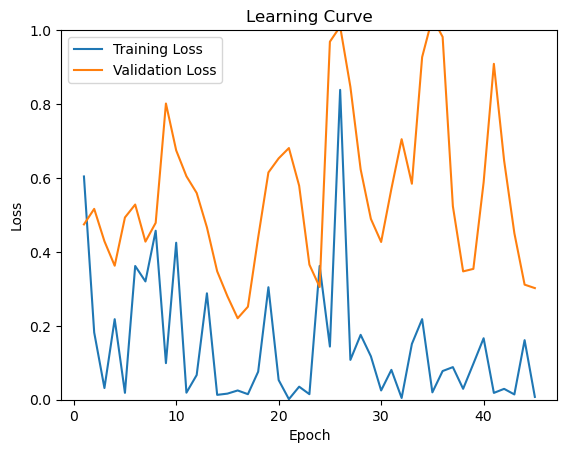

Accuracy: 0.8888888955116272. Recall: 0.75. Precision: 1.0
Fold 2
Best epoc: 28. Best val loss: 0.09005411714315414


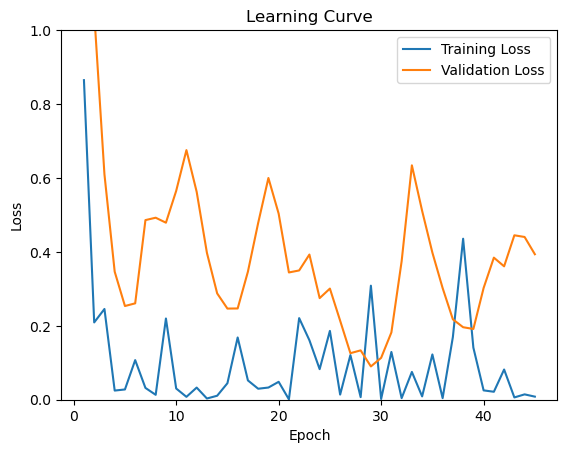

Accuracy: 0.7777777910232544. Recall: 0.75. Precision: 0.75
Fold 3
Best epoc: 4. Best val loss: 0.01752268336713314


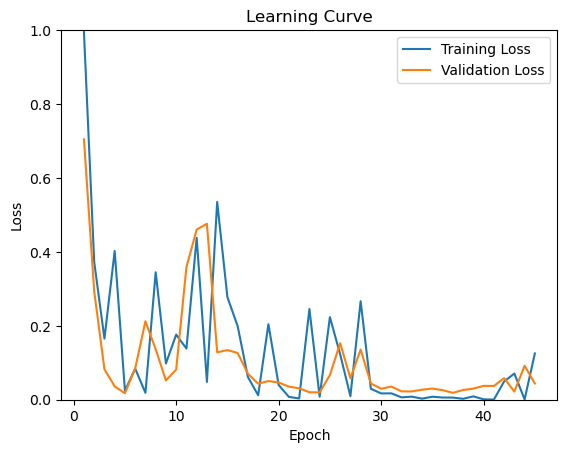

Accuracy: 1.0. Recall: 1.0. Precision: 1.0
Fold 4
Best epoc: 24. Best val loss: 0.5104089975357056


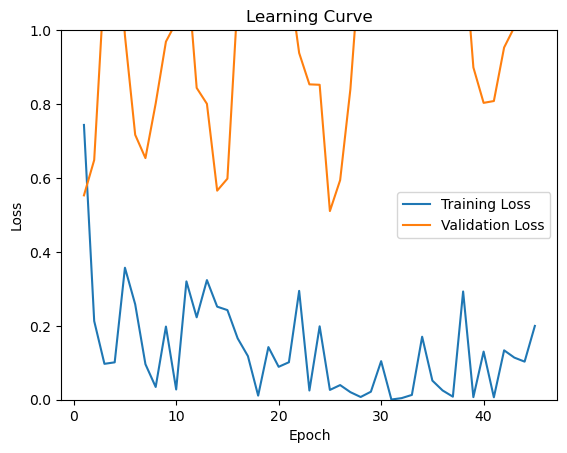

Accuracy: 0.8888888955116272. Recall: 0.75. Precision: 1.0
Fold 5
Best epoc: 14. Best val loss: 0.07421156764030457


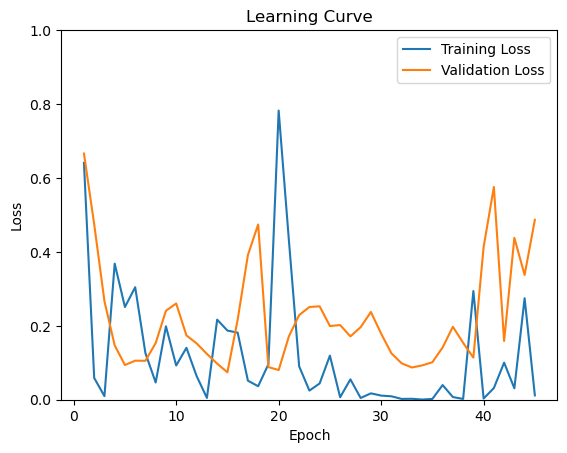

Accuracy: 0.875. Recall: 0.75. Precision: 1.0
Fold 1
Best epoc: 18. Best val loss: 0.09146629273891449


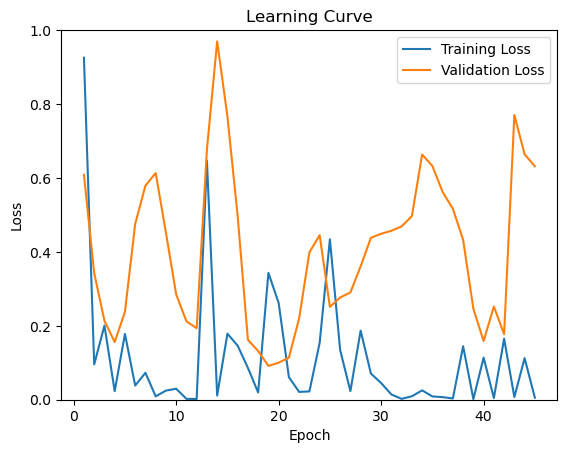

Accuracy: 0.8888888955116272. Recall: 0.75. Precision: 1.0
Fold 2
Best epoc: 28. Best val loss: 0.6392773389816284


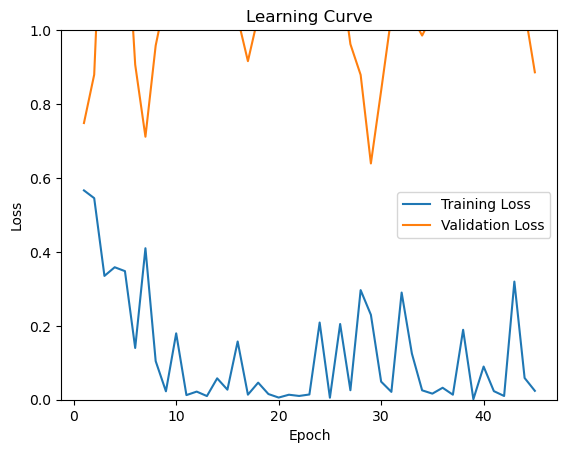

Accuracy: 0.8888888955116272. Recall: 0.75. Precision: 1.0
Fold 3
Best epoc: 27. Best val loss: 0.4083608388900757


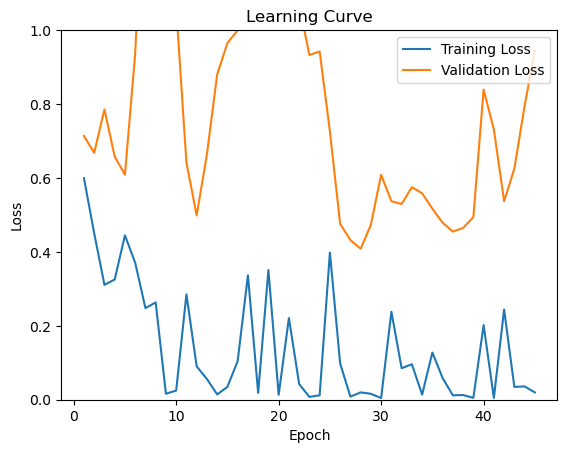

Accuracy: 0.7777777910232544. Recall: 1.0. Precision: 0.6666666865348816
Fold 4
Best epoc: 35. Best val loss: 0.023491811007261276


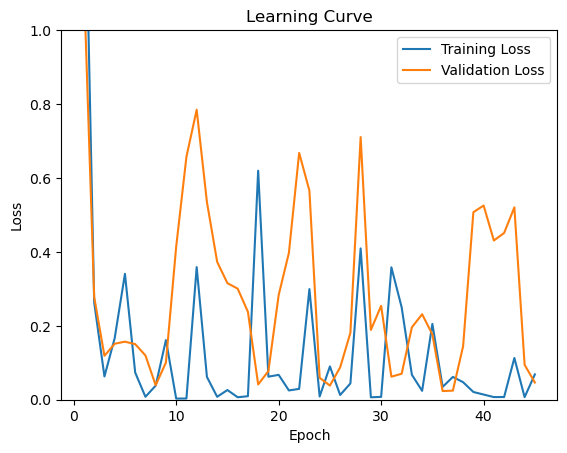

Accuracy: 0.7777777910232544. Recall: 0.5. Precision: 1.0
Fold 5
Best epoc: 36. Best val loss: 0.03145754337310791


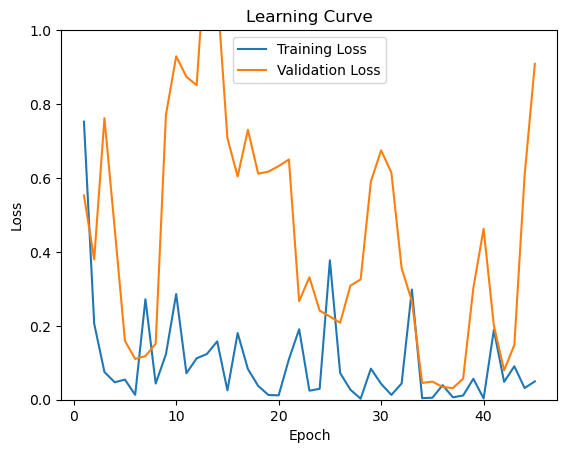

Accuracy: 0.5. Recall: 0.75. Precision: 0.5
Fold 1
Best epoc: 36. Best val loss: 0.009050372987985611


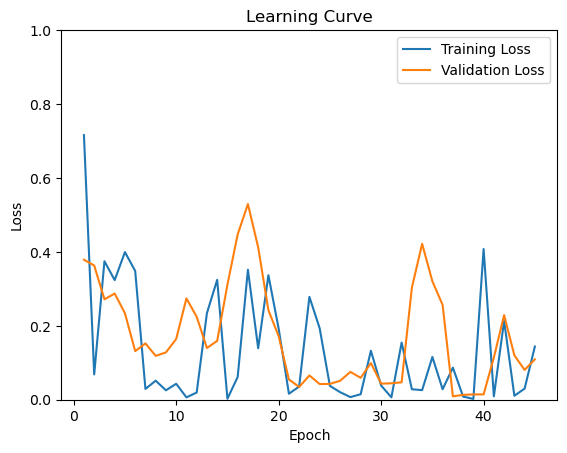

Accuracy: 0.8888888955116272. Recall: 0.75. Precision: 1.0
Fold 2
Best epoc: 9. Best val loss: 0.1501885950565338


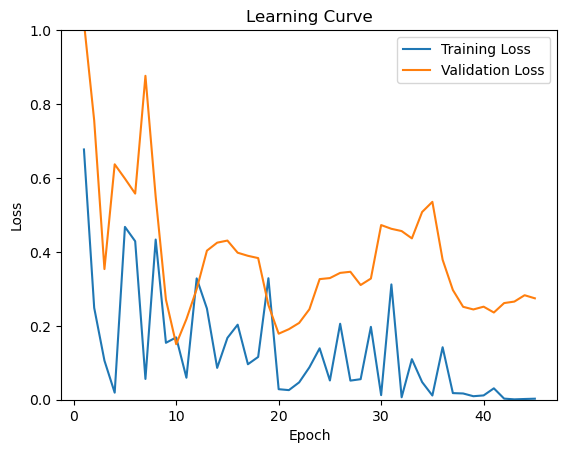

Accuracy: 0.8888888955116272. Recall: 1.0. Precision: 0.800000011920929
Fold 3
Best epoc: 21. Best val loss: 0.034416332840919495


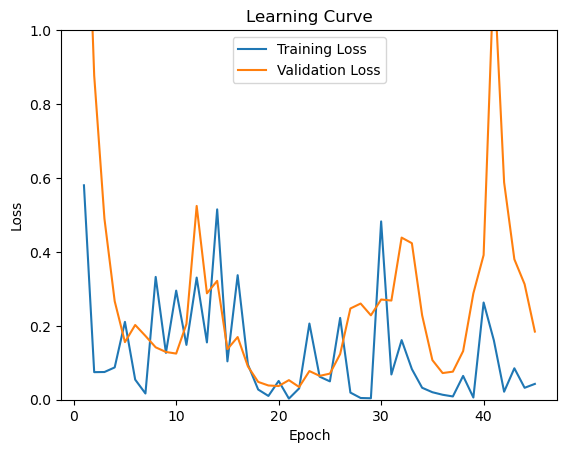

Accuracy: 0.8888888955116272. Recall: 0.75. Precision: 1.0
Fold 4
Best epoc: 17. Best val loss: 0.6031222343444824


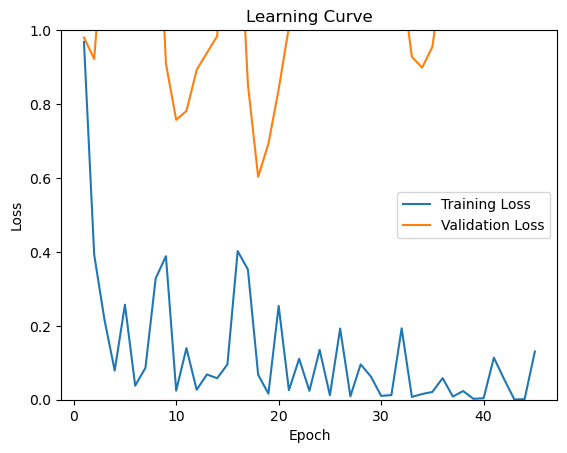

Accuracy: 0.7777777910232544. Recall: 0.75. Precision: 0.75
Fold 5
Best epoc: 40. Best val loss: 0.1774435043334961


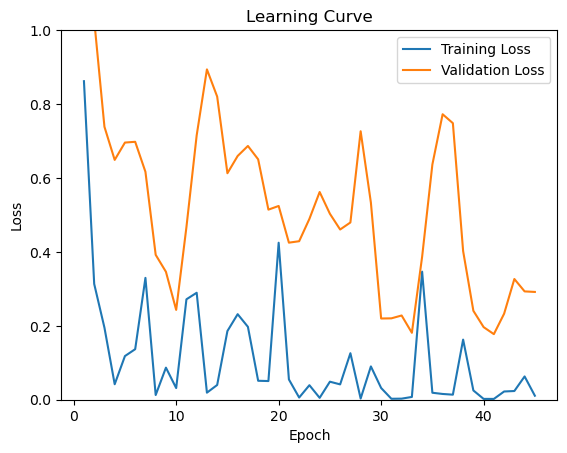

Accuracy: 0.875. Recall: 1.0. Precision: 0.800000011920929
Fold 1
Best epoc: 2. Best val loss: 0.1510491669178009


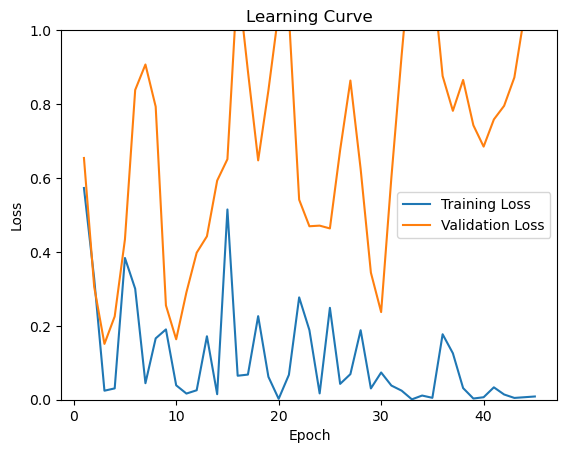

Accuracy: 0.7777777910232544. Recall: 0.5. Precision: 1.0
Fold 2
Best epoc: 30. Best val loss: 0.07073892652988434


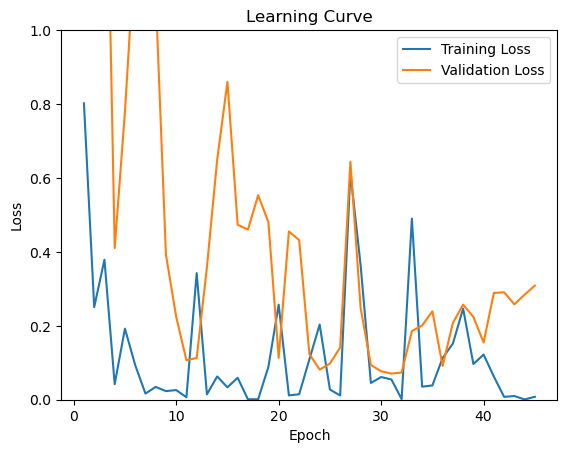

Accuracy: 0.8888888955116272. Recall: 1.0. Precision: 0.800000011920929
Fold 3
Best epoc: 35. Best val loss: 0.01928400807082653


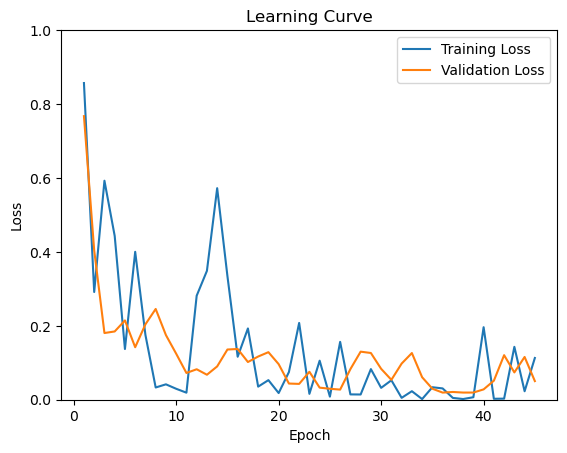

Accuracy: 0.7777777910232544. Recall: 0.75. Precision: 0.75
Fold 4
Best epoc: 8. Best val loss: 0.307792603969574


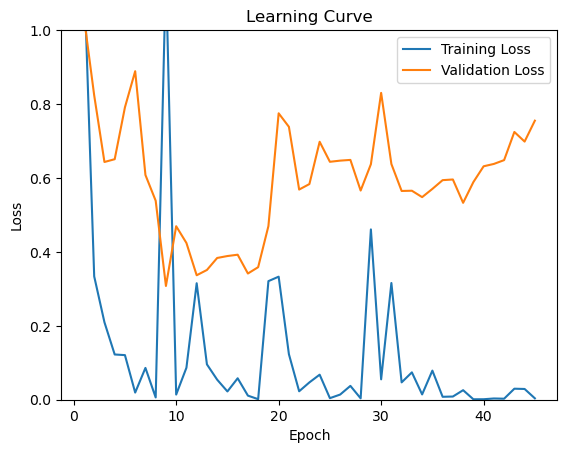

Accuracy: 1.0. Recall: 1.0. Precision: 1.0
Fold 5
Best epoc: 29. Best val loss: 0.004926785361021757


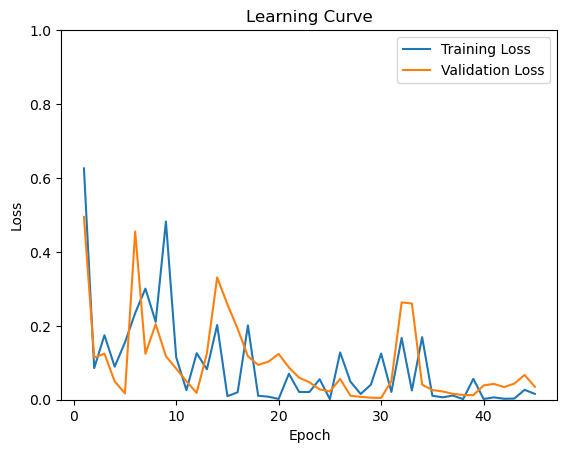

Accuracy: 0.875. Recall: 0.75. Precision: 1.0
Fold 1
Best epoc: 32. Best val loss: 0.04259062558412552


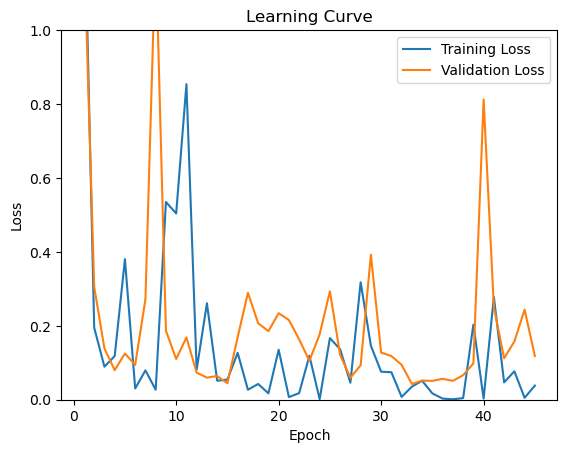

Accuracy: 0.8888888955116272. Recall: 1.0. Precision: 0.800000011920929
Fold 2
Best epoc: 27. Best val loss: 0.0013145480770617723


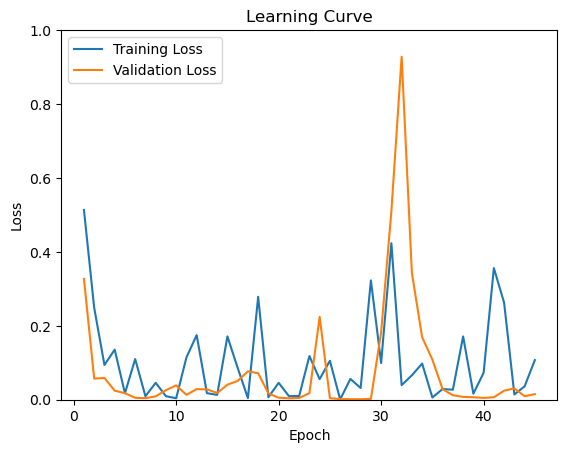

Accuracy: 0.7777777910232544. Recall: 0.5. Precision: 1.0
Fold 3
Best epoc: 43. Best val loss: 0.1595306396484375


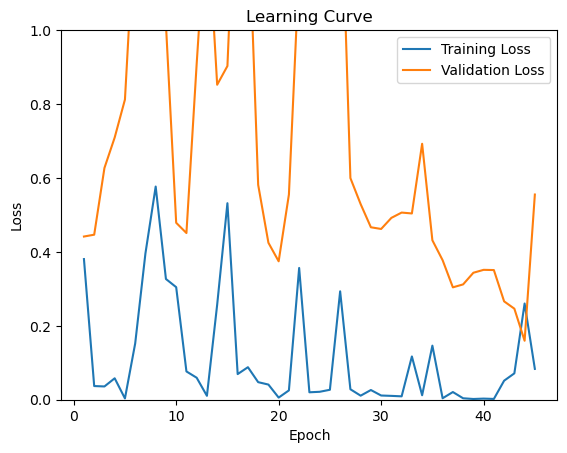

Accuracy: 0.8888888955116272. Recall: 0.75. Precision: 1.0
Fold 4
Best epoc: 32. Best val loss: 0.913995623588562


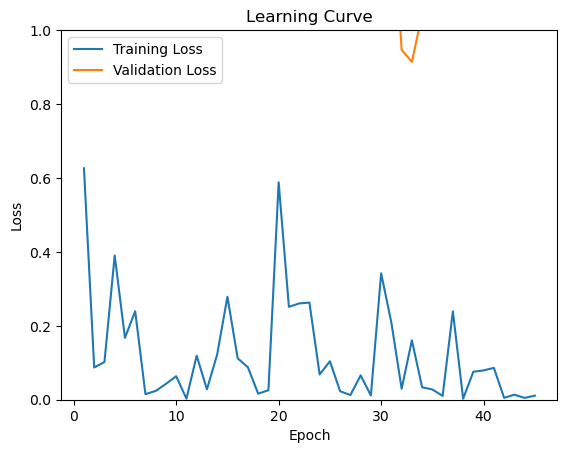

Accuracy: 0.7777777910232544. Recall: 1.0. Precision: 0.6666666865348816
Fold 5
Best epoc: 16. Best val loss: 0.5626400709152222


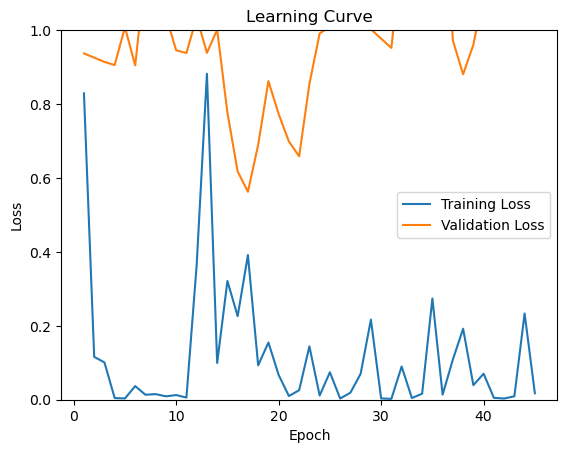

Accuracy: 1.0. Recall: 1.0. Precision: 1.0
ACCS: [0.8861111164093017, 0.7666666746139527, 0.8638888955116272, 0.8638888955116272, 0.8666666746139526]
RECS: [0.8, 0.75, 0.85, 0.8, 0.85]
PRECS: [0.95, 0.8333334, 0.87, 0.91, 0.8933333]
F1S: [0.8685714176722935, 0.7894736643973485, 0.8598837598553852, 0.8514620217337352, 0.8711280800101749]
STD-ACC: [0.07049209348016061, 0.1422916524099047, 0.04339027300941767, 0.08258926569525993, 0.08314793697230627]
STD-REC: [0.1, 0.15811388, 0.12247449, 0.18708286, 0.2]
STD-PREC: [0.1, 0.2108185, 0.1077033, 0.11135528, 0.13727507]
ACC: 0.8494444513320923
0.042214911006335384
0.030121682394442104
RECALL: 0.8100000619888306
PRECISION: 0.891333281993866
F1: 0.8481037887337874
STD-ACC: 0.08438224431340983
STD-REC: 0.15353424847126007
STD-PREC: 0.13343043625354767


In [5]:
accs = []
recs = []
precs = []
f1 = []
std_accs = []
std_recs = []
std_precs = []
seeds = random.sample(range(1,10001), 100)

seeds_tr = [random.sample(range(1,10001), 5) for _ in range(100)]
for i in range(5):
    acc, rec, prec, std_acc, std_rec, std_prec = prueba_k_fold_resnet_no_pre_impr_fin(df_mosaic, 5, 45, optim.Adam, 5, 8.324546221005873e-05, False, 'G', seeds[0], seeds_tr[0])
    accs.append(acc)
    recs.append(rec)
    precs.append(prec)
    std_accs.append(std_acc)
    std_recs.append(std_rec)
    std_precs.append(std_prec)
    f1.append(2*(rec*prec)/(rec+prec))
    seeds.pop(0)
    seeds_tr.pop(0)

print(f"ACCS: {accs}")
print(f"RECS: {recs}")
print(f"PRECS: {precs}")
print(f"F1S: {f1}")

print(f"STD-ACC: {std_accs}")
print(f"STD-REC: {std_recs}")
print(f"STD-PREC: {std_precs}")

print(f"ACC: {np.mean(accs)}")
print(np.std(accs))
print(np.std(f1))
print(f"RECALL: {np.mean(recs)}")
print(f"PRECISION: {np.mean(precs)}")
print(f"F1: {np.mean(f1)}")
print(f"STD-ACC: {np.mean(std_accs)}")
print(f"STD-REC: {np.mean(std_recs)}")
print(f"STD-PREC: {np.mean(std_precs)}")

Fold 1
Best epoc: 4. Best val loss: 0.17476919293403625


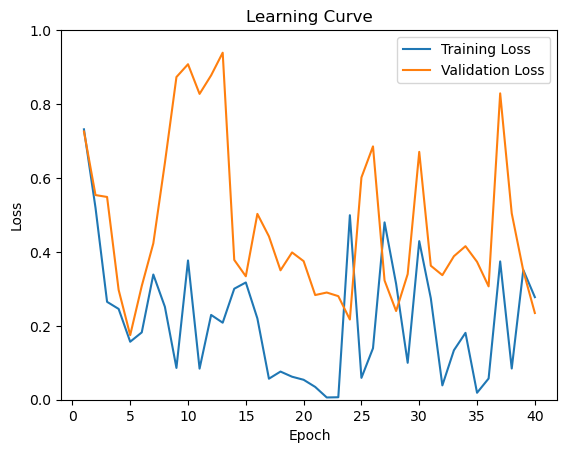

Accuracy: 0.8888888955116272. Recall: 0.75. Precision: 1.0
Fold 2
Best epoc: 2. Best val loss: 0.46143344044685364


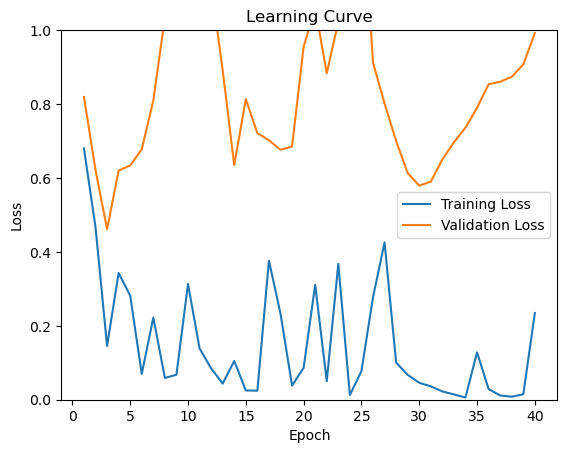

Accuracy: 1.0. Recall: 1.0. Precision: 1.0
Fold 3
Best epoc: 28. Best val loss: 0.257426917552948


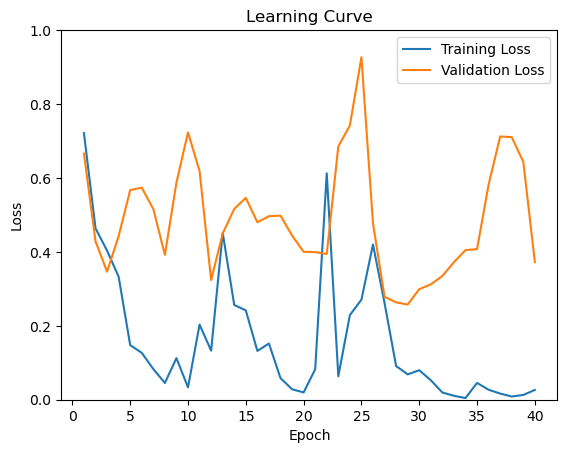

Accuracy: 0.8888888955116272. Recall: 0.75. Precision: 1.0
Fold 4
Best epoc: 39. Best val loss: 0.02021166682243347


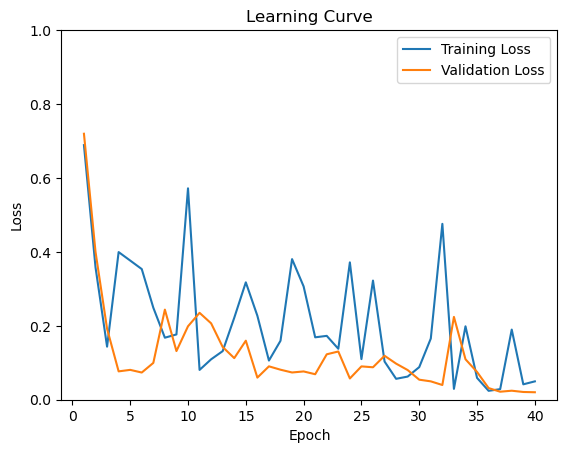

Accuracy: 0.7777777910232544. Recall: 1.0. Precision: 0.6666666865348816
Fold 5
Best epoc: 14. Best val loss: 0.00967460498213768


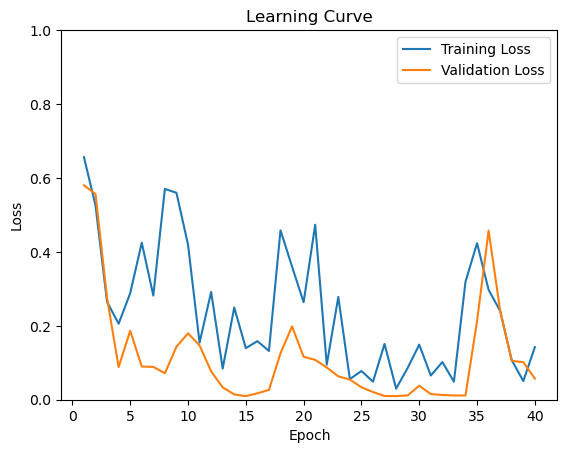

Accuracy: 0.875. Recall: 0.75. Precision: 1.0
Fold 1
Best epoc: 25. Best val loss: 0.3174076974391937


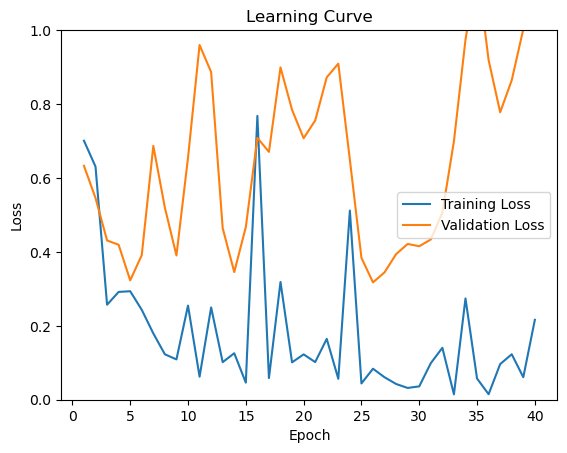

Accuracy: 1.0. Recall: 1.0. Precision: 1.0
Fold 2
Best epoc: 14. Best val loss: 0.010918881744146347


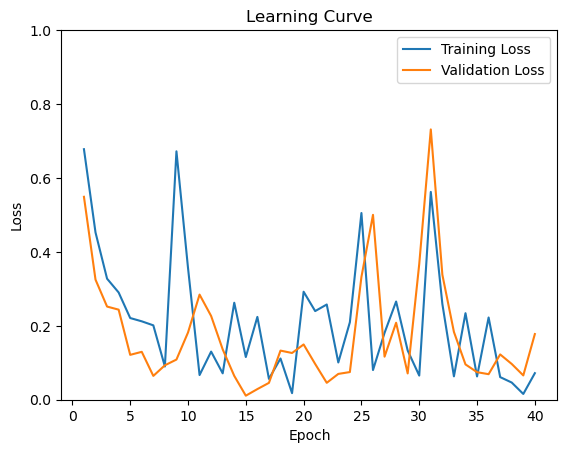

Accuracy: 0.8888888955116272. Recall: 0.75. Precision: 1.0
Fold 3
Best epoc: 9. Best val loss: 0.10625873506069183


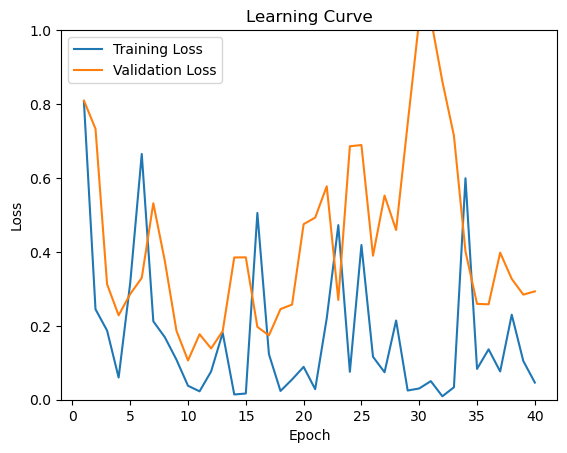

Accuracy: 0.7777777910232544. Recall: 0.5. Precision: 1.0
Fold 4
Best epoc: 35. Best val loss: 0.05131121352314949


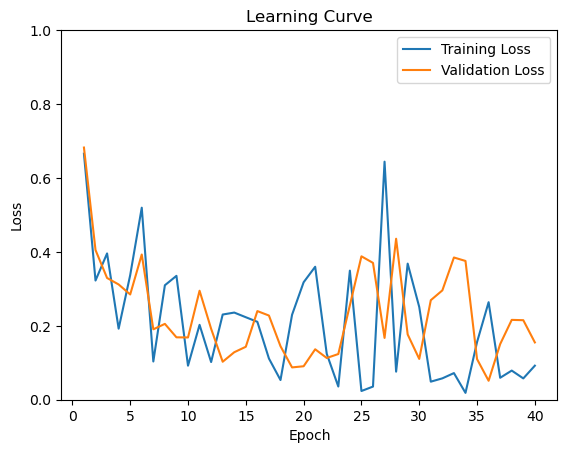

Accuracy: 0.8888888955116272. Recall: 1.0. Precision: 0.800000011920929
Fold 5
Best epoc: 31. Best val loss: 0.14982403814792633


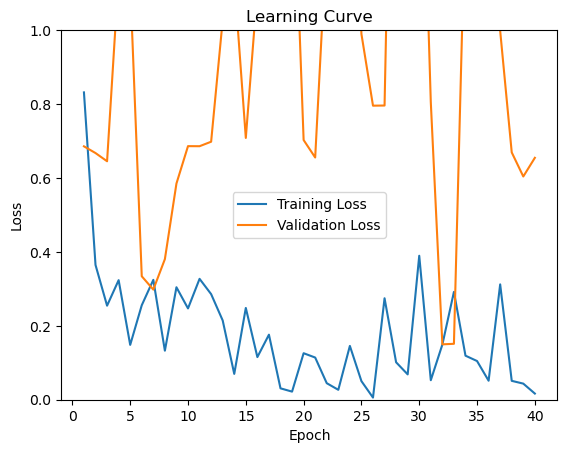

Accuracy: 0.625. Recall: 1.0. Precision: 0.5714285969734192
Fold 1
Best epoc: 3. Best val loss: 0.2808416783809662


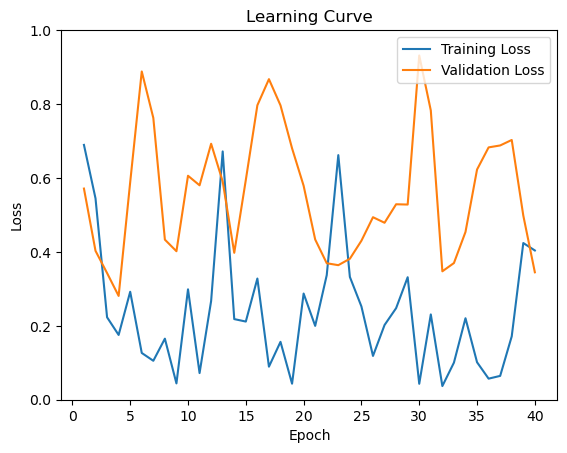

Accuracy: 1.0. Recall: 1.0. Precision: 1.0
Fold 2
Best epoc: 22. Best val loss: 0.028132721781730652


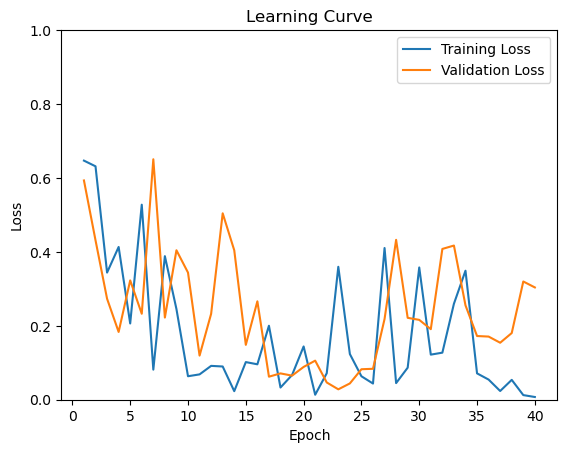

Accuracy: 1.0. Recall: 1.0. Precision: 1.0
Fold 3
Best epoc: 23. Best val loss: 0.004739532712846994


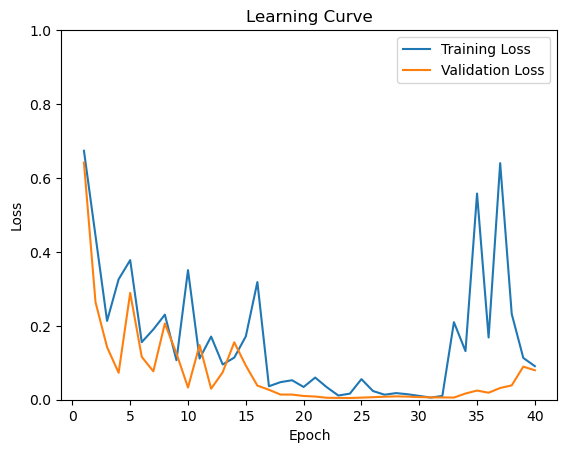

Accuracy: 0.7777777910232544. Recall: 0.5. Precision: 1.0
Fold 4
Best epoc: 8. Best val loss: 0.394075483083725


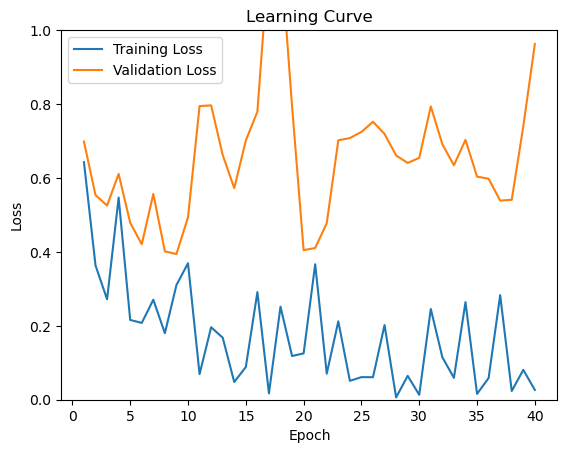

Accuracy: 0.6666666865348816. Recall: 0.5. Precision: 0.6666666865348816
Fold 5
Best epoc: 14. Best val loss: 0.27829718589782715


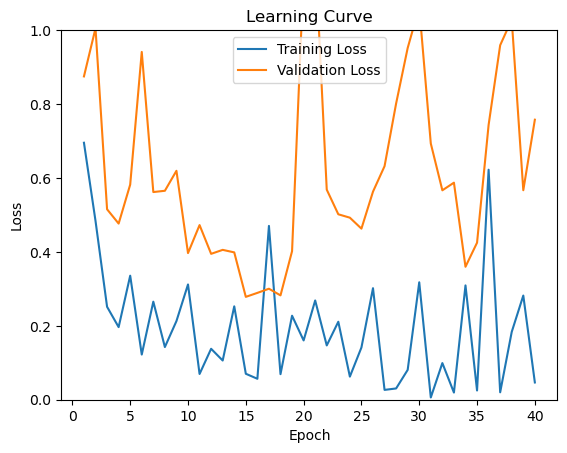

Accuracy: 0.875. Recall: 1.0. Precision: 0.800000011920929
Fold 1
Best epoc: 32. Best val loss: 0.08253858983516693


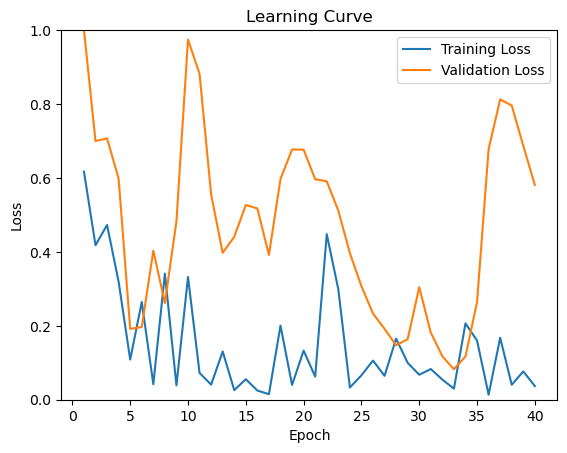

Accuracy: 0.7777777910232544. Recall: 0.5. Precision: 1.0
Fold 2
Best epoc: 8. Best val loss: 0.3361521363258362


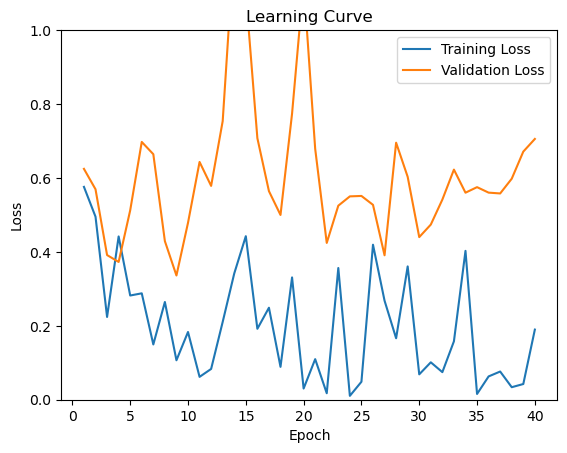

Accuracy: 0.7777777910232544. Recall: 1.0. Precision: 0.6666666865348816
Fold 3
Best epoc: 21. Best val loss: 0.01800842396914959


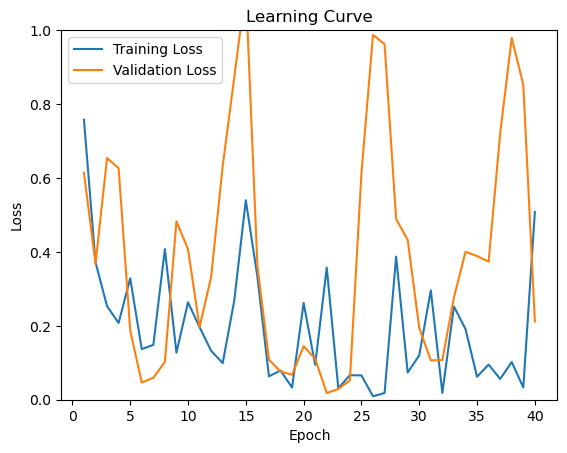

Accuracy: 0.8888888955116272. Recall: 0.75. Precision: 1.0
Fold 4
Best epoc: 13. Best val loss: 0.0058695473708212376


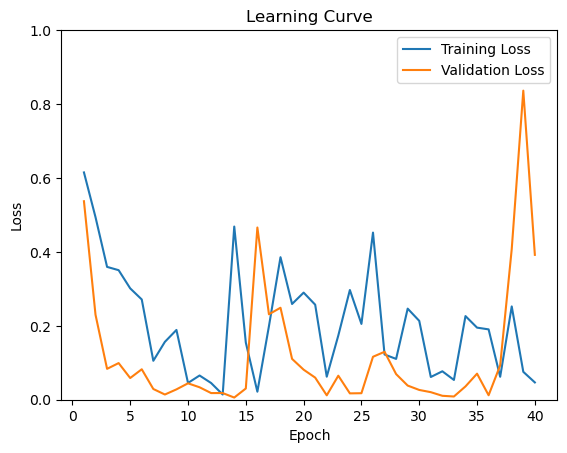

Accuracy: 0.8888888955116272. Recall: 0.75. Precision: 1.0
Fold 5
Best epoc: 23. Best val loss: 0.4659974277019501


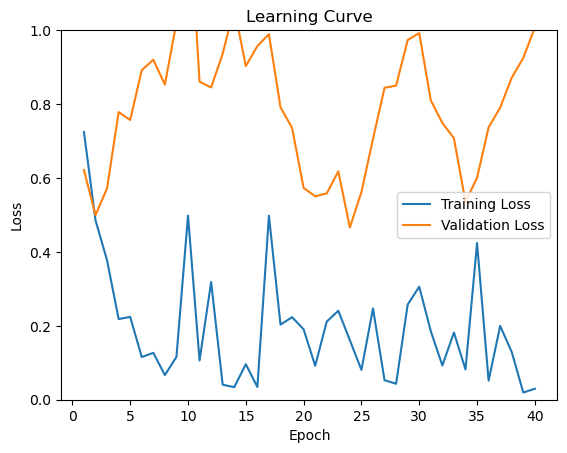

Accuracy: 1.0. Recall: 1.0. Precision: 1.0
Fold 1
Best epoc: 8. Best val loss: 0.5165842771530151


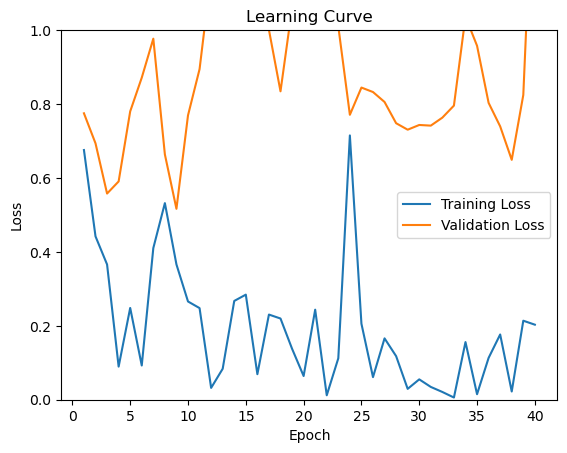

Accuracy: 0.6666666865348816. Recall: 0.75. Precision: 0.6000000238418579
Fold 2
Best epoc: 36. Best val loss: 0.11260298639535904


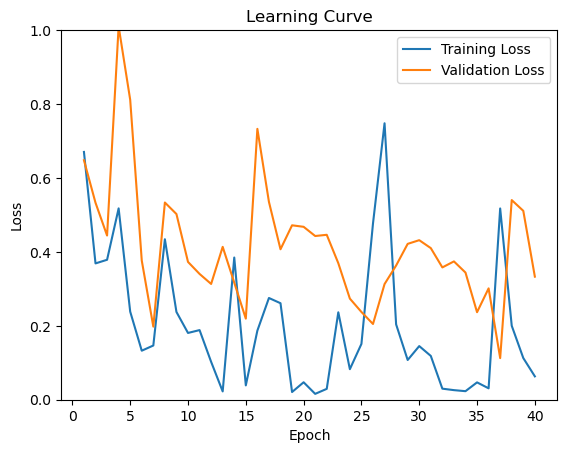

Accuracy: 1.0. Recall: 1.0. Precision: 1.0
Fold 3
Best epoc: 13. Best val loss: 0.0635976791381836


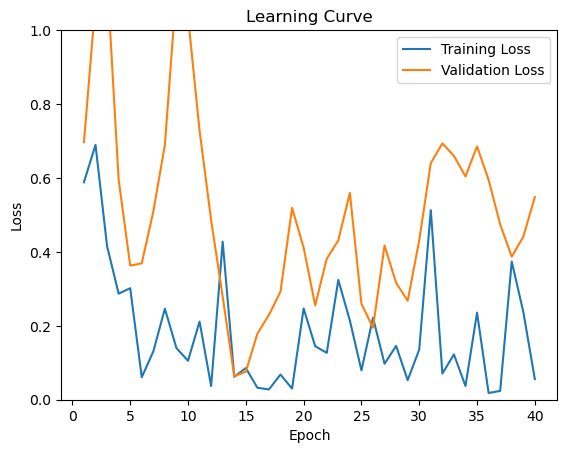

Accuracy: 0.8888888955116272. Recall: 0.75. Precision: 1.0
Fold 4
Best epoc: 32. Best val loss: 0.02587144821882248


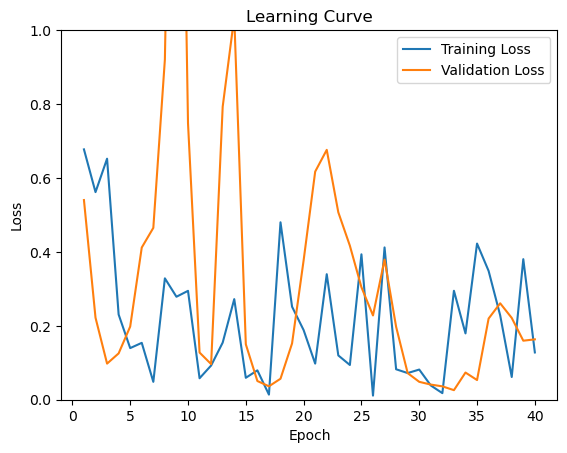

Accuracy: 0.8888888955116272. Recall: 0.75. Precision: 1.0
Fold 5
Best epoc: 35. Best val loss: 0.09401427209377289


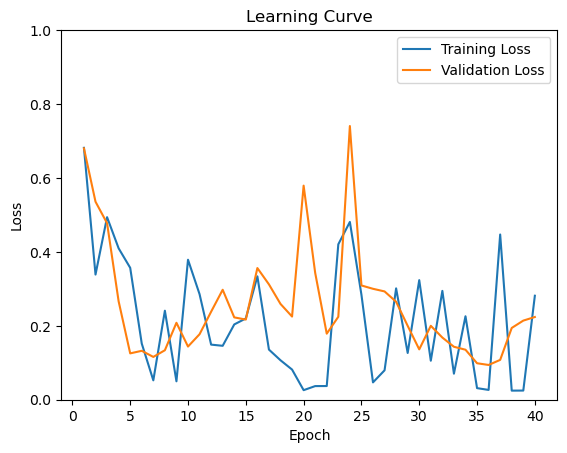

Accuracy: 0.875. Recall: 1.0. Precision: 0.800000011920929
ACCS: [0.8861111164093017, 0.8361111164093018, 0.8638888955116272, 0.8666666746139526, 0.8638888955116272]
RECS: [0.85, 0.85, 0.8, 0.8, 0.85]
PRECS: [0.9333334, 0.8742857, 0.8933333, 0.9333334, 0.88]
F1S: [0.8897196698994665, 0.861971811121642, 0.8440944588097892, 0.8615385260807686, 0.8647399046270569]
STD-ACC: [0.07049209348016063, 0.12680791333408922, 0.12921891827663284, 0.08314793697230627, 0.10844011169457858]
STD-REC: [0.12247449, 0.2, 0.24494897, 0.18708286, 0.12247449]
STD-PREC: [0.13333333, 0.17009, 0.13727506, 0.13333333, 0.15999998]
ACC: 0.863333339691162
0.015947444678541332
0.014612320332561591
RECALL: 0.8300000429153442
PRECISION: 0.9028571844100952
F1: 0.8644128741077447
STD-ACC: 0.10362139475155352
STD-REC: 0.1753961741924286
STD-PREC: 0.14680632948875427


In [6]:
accs = []
recs = []
precs = []
f1 = []
std_accs = []
std_recs = []
std_precs = []
seeds = random.sample(range(1,10001), 100)

seeds_tr = [random.sample(range(1,10001), 5) for _ in range(100)]
for i in range(5):
    acc, rec, prec, std_acc, std_rec, std_prec = prueba_k_fold_resnet_no_pre_impr_fin(df_mosaic, 5, 40, optim.Adam, 5, 9.734422735457594e-05, True, None, seeds[0], seeds_tr[0])
    accs.append(acc)
    recs.append(rec)
    precs.append(prec)
    std_accs.append(std_acc)
    std_recs.append(std_rec)
    std_precs.append(std_prec)
    f1.append(2*(rec*prec)/(rec+prec))
    seeds.pop(0)
    seeds_tr.pop(0)

print(f"ACCS: {accs}")
print(f"RECS: {recs}")
print(f"PRECS: {precs}")
print(f"F1S: {f1}")

print(f"STD-ACC: {std_accs}")
print(f"STD-REC: {std_recs}")
print(f"STD-PREC: {std_precs}")

print(f"ACC: {np.mean(accs)}")
print(np.std(accs))
print(np.std(f1))
print(f"RECALL: {np.mean(recs)}")
print(f"PRECISION: {np.mean(precs)}")
print(f"F1: {np.mean(f1)}")
print(f"STD-ACC: {np.mean(std_accs)}")
print(f"STD-REC: {np.mean(std_recs)}")
print(f"STD-PREC: {np.mean(std_precs)}")

### SI TL NO OC

In [7]:

def accuracy(outputs, labels):
    preds = outputs > 0.5  # Si la salida es mayor que 0.5, consideramos que es positiva
    correct = (preds == labels.byte())  # Compara las predicciones con las etiquetas reales
    acc = correct.float().sum() / labels.size(0)  # Calcula la precisión
    return acc.item()

def recall(outputs, labels):
    preds = outputs > 0.5

    preds = preds.cpu()
    labels = labels.cpu()
    TP = sum((preds == 1) & (labels == 1))
    FN = sum((preds == 0) & (labels == 1))

    recall_score = TP / (TP + FN) if (TP + FN) > 0 else 0
    return recall_score

def precision(outputs, labels):
    preds = outputs > 0.5

    preds = preds.cpu()
    labels = labels.cpu()

    TP = sum((preds == 1) & (labels == 1))
    FP = sum((preds == 1) & (labels == 0))

    precision_score = TP / (TP + FP) if (TP + FP) > 0 else 0
    return precision_score



def prueba_k_fold_resnet_pre_impr_fin(dataset, num_folds_outer, num_epochs_freeze, num_epochs_all, op, batch_size, lr, data_aug, ini, random_seed, seeds_tr_split):
    # Transformaciones para preprocesar las imágenes
    if data_aug:
        transform_t = v2.Compose([
            v2.Resize((224, 224)),
            # v2.RandomResizedCrop(224),
            v2.RandomHorizontalFlip(),
            v2.RandomVerticalFlip(),
            # v2.ElasticTransform(alpha=250.0),
            # v2.RandomRotation(45),
            # transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.2),
            v2.ToImage(),
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

        transform_v = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(),
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])
    else:
        transform_t = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(),
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

        transform_v = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(),
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

    # Modelo personalizado basado en ResNet
    class CustomResNet(nn.Module):
        def __init__(self, num_classes_binary=1):
            super(CustomResNet, self).__init__()
            resnet = models.resnet18(weights='IMAGENET1K_V1')
            # Extraer las capas de la red ResNet, excluyendo la capa de clasificación
            self.features = nn.Sequential(*list(resnet.children())[:-1])

            # Congelar capas preentrenadas
            for param in self.features.parameters():
                param.requires_grad = False

            # Personalizar la capa de salida para tus necesidades
            self.fc_binary = nn.Linear(512, num_classes_binary)

            if (ini== "G"):
                # Inicialización de Glorot para las capas fully connected
                self.apply(self.init_weights_glorot)
            elif(ini == "H"):
                self.apply(self.init_weights_he)
            elif (ini== "N"):
                self.apply(self.init_weights_normal)
            elif(ini == "U"):
                self.apply(self.init_weights_uniform)
            elif (ini== "O"):
                self.apply(self.init_weights_orthogonal)
            elif(ini == "Z"):
                self.apply(self.init_weights_zeros)
            elif(ini == "ON"):
                self.apply(self.init_weights_ones)

        def init_weights_glorot(self, m):
            if isinstance(m, nn.Linear):
                init.xavier_uniform_(m.weight)
                if m.bias is not None:
                    init.constant_(m.bias, 0)

        def init_weights_he(self, m):
            if isinstance(m, nn.Linear):
                init.kaiming_uniform_(m.weight, mode='fan_in', nonlinearity='relu')
                if m.bias is not None:
                    init.constant_(m.bias, 0)
        def init_weights_normal(self, m):
            if isinstance(m, nn.Linear):
                init.normal_(m.weight, mean=0, std=0.01)  # Puedes ajustar la media y la desviación estándar según tus necesidades
                if m.bias is not None:
                    init.constant_(m.bias, 0)

        def init_weights_uniform(self, m):
            if isinstance(m, nn.Linear):
                init.uniform_(m.weight, a=-0.1, b=0.1)  # Puedes ajustar los límites inferior y superior según tus necesidades
                if m.bias is not None:
                    init.constant_(m.bias, 0)

        def init_weights_orthogonal(self, m):
            if isinstance(m, nn.Linear):
                init.orthogonal_(m.weight)  # Puedes ajustar el parámetro 'gain' según tus necesidades
                if m.bias is not None:
                    init.constant_(m.bias, 0)

        def init_weights_zeros(self, m):
            if isinstance(m, nn.Linear):
                init.zeros_(m.weight)
                if m.bias is not None:
                    init.zeros_(m.bias)

        def init_weights_ones(self, m):
            if isinstance(m, nn.Linear):
                init.ones_(m.weight)
                if m.bias is not None:
                    init.ones_(m.bias)

        def forward(self, x):
            x = self.features(x)
            x = x.view(x.size(0), -1)


            # Salida para la variable binaria
            out_binary = self.fc_binary(x)

            return out_binary

    # Definir una clase para el conjunto de datos personalizado
    ##adaptar esto para meter unas rutsa y obtener dataos y etiquetas
    class CustomDataset(Dataset):
        def __init__(self, dataframe, transform=None):
            self.data = dataframe
            self.transform = transform

        def __len__(self):
            return len(self.data)

        def __getitem__(self, idx):
            img_path = self.data.iloc[idx, 0]  # Ruta de la imagen en la primera columna
            image = Image.open(img_path).convert('RGB')
            # Etiquetas: una variable binaria
            label_binary = torch.tensor(self.data.iloc[idx, 1], dtype=torch.float32)

            if self.transform:
                image = self.transform(image)

            return image, label_binary

    #####5 fold CV
    from sklearn.model_selection import StratifiedKFold

    # Definir el número de folds
    criterion_binary = nn.BCEWithLogitsLoss()
    kf_outer = StratifiedKFold(n_splits=num_folds_outer, shuffle=True, random_state=random_seed)
    ##No será necesario el inner porque la partición será fija en 80%/20%
    # kf_inner = StratifiedKFold(n_splits=num_folds_inner, shuffle=True, random_state=14)
    # Listas para almacenar las pérdidas de entrenamiento y validación de cada fold
    accs = []
    recs = []
    precs = []
    

    
    # Aqui se itera sobre los folds outer, es decir, uno de los folds se usará para test, ya que el modelo no lo verá durante el entrenamiento.

    ##Por otro lado, la parte de train, se verá otra vez sometida a un kfold, 
    
    for fold, (train_index, test_index) in enumerate(kf_outer.split(np.zeros(len(dataset)),dataset['Etiqueta'])):
        print(f"Fold {fold + 1}")

        # Dividir el conjunto de datos en entrenamiento y validación para este fold
        train_data_fold = dataset.iloc[train_index]
        test_data_fold = dataset.iloc[test_index]

        ##Aqui ya tengo train y test por lo que, antes del bucle para las épocas, se hará la partición con sklearn train test split para validación y train
        ##como se hace dentro del bucle para el outer CV, se hará una vez por fold, que es justo lo que queremos para promediar su rendimiento en un conjunto de test
        ##el cual no se ha usado en ningún momento para entrenar
        
        train_data_inner, val_data_inner = train_test_split(train_data_fold, test_size=0.2, random_state=seeds_tr_split[fold-1], stratify=train_data_fold['Etiqueta'])
        
        # Crear instancias del conjunto de datos personalizado para este fold
        train_dataset_fold = CustomDataset(dataframe=train_data_inner, transform=transform_t)
        val_dataset_fold = CustomDataset(dataframe=val_data_inner, transform=transform_v)

        test_dataset = CustomDataset(dataframe=test_data_fold, transform=transform_v)
        # Crear DataLoader para cargar los datos en lotes
        train_loader_fold_in = DataLoader(dataset=train_dataset_fold, batch_size=batch_size, shuffle=True)
        val_loader_fold_in = DataLoader(dataset=val_dataset_fold, batch_size=len(val_data_inner), shuffle=False)

        ##Aqui el batch size será de la longitud del test_dataset
        ##como se usa con model eval daría un poco igual el batch size, como en validacion
        test_dataloader = DataLoader(dataset=test_dataset, batch_size=len(test_data_fold), shuffle=False)
       
        # Re-inicializar el modelo para cada fold
        model = CustomResNet(num_classes_binary=1).to(device)
        optimizer = op(model.parameters(), lr = lr)
        optimizer2 = op(model.fc_binary.parameters(), lr = lr)
        # Entrenamiento y validación para este fold
        
        val_loss_best = -1
        best_epoc = -1
        best_model = None

        train_losses_fold = []
        val_losses_fold = []
        
        for epoch in range(num_epochs_freeze):
            # Entrenamiento del modelo
            # Fase de entrenamiento
            model.train()
            loss_total_acumulada = 0.0
            
            for images, bin_label in train_loader_fold_in:
                # for i in images:
                #     print(i.shape)
                # images_grid = utils.make_grid(images, nrow=8)  # Hacer una cuadrícula de imágenes
                # plt.figure(figsize=(10, 10))
                # plt.imshow(np.transpose(images_grid, (1, 2, 0)))  # Transponer las dimensiones para mostrar correctamente
                # plt.axis('off')
                # plt.show()
                # break  # Salir después de mostrar el primer lote
                # Reiniciar gradientes
                # Reiniciar gradientes
                images, bin_label = images.to(device), bin_label.to(device)
                optimizer2.zero_grad()
                # Forward pass
                bin_out = model(images)
                # Calcular pérdida para las variables continuas
                # Calcular pérdida para la variable binaria
                lossT_bin = criterion_binary(bin_out.squeeze(1), bin_label)
                # Pérdida total
                loss_total = lossT_bin
                loss_total_acumulada += loss_total
                # Backward pass y optimización
                loss_total.backward()
                optimizer2.step()
                
            # Validación del modelo
            model.eval()
            val_loss = 0.0
            
            with torch.no_grad():
                for images, bin_label in val_loader_fold_in:
                    # Reiniciar gradientes
                    images,  bin_label = images.to(device),  bin_label.to(device)
                    ##print(len(images)) aqui se hace con 32 imagenes
                    # Forward pass en el conjunto de validación
                    bin_out = model(images)
                    # Calcular pérdida para la variable binaria
                    lossV_bin = criterion_binary(bin_out.squeeze(1), bin_label)
                    # Sumar las pérdidas del conjunto de validación
                    val_loss += lossV_bin.item()
                    

            avg_loss_total_acumulada = loss_total_acumulada / len(train_loader_fold_in)
            train_losses_fold.append(avg_loss_total_acumulada)
            
            avg_val_loss = val_loss / len(val_loader_fold_in)
            val_losses_fold.append(avg_val_loss)

            if(val_loss_best == -1):
                val_loss_best = avg_val_loss
                best_model = copy.deepcopy(model)
                best_epoc = epoch
            else:
                if (avg_val_loss < val_loss_best):
                    val_loss_best = avg_val_loss
                    best_model = copy.deepcopy(model)
                    best_epoc = epoch
            # print(f'Epoch [{epoch+1}/{num_epochs}], Training Loss: {avg_loss_total_acumulada.item()}, Validation Loss: {avg_val_loss}')

            ##Se descongelan todas
        for param in model.features.parameters():
            param.requires_grad = True
        for epoch in range(num_epochs_freeze, num_epochs_freeze + num_epochs_all):
            # Entrenamiento del modelo
            # Fase de entrenamiento
            model.train()
            loss_total_acumulada = 0.0
            
            for images, bin_label in train_loader_fold_in:
                # Reiniciar gradientes
                images, bin_label = images.to(device), bin_label.to(device)
                optimizer.zero_grad()
                # Forward pass
                bin_out = model(images)
                # Calcular pérdida para las variables continuas
                # Calcular pérdida para la variable binaria
                lossT_bin = criterion_binary(bin_out.squeeze(1), bin_label)
                # Pérdida total
                loss_total = lossT_bin
                loss_total_acumulada += loss_total
                # Backward pass y optimización
                loss_total.backward()
                optimizer.step()
                
            # Validación del modelo
            model.eval()
            val_loss = 0.0
            
            with torch.no_grad():
                for images, bin_label in val_loader_fold_in:
                    images,  bin_label = images.to(device),  bin_label.to(device)
                    ##print(len(images)) aqui se hace con 32 imagenes
                    # Forward pass en el conjunto de validación
                    bin_out = model(images)
                    # Calcular pérdida para la variable binaria
                    lossV_bin = criterion_binary(bin_out.squeeze(1), bin_label)
                    # Sumar las pérdidas del conjunto de validación
                    val_loss += lossV_bin.item()
                    ##La cosa sería comparar cada loss con la anterior e ir quedándote con la más baja, guardando el modelo o algo por el estilo
                    ##también se podría hacer por accuracy + recall, o hacer una ponderación de los tres
                    ###ALGO COMO
                    ################### modelo_mejor = modelo si se cumplen las características, posteriormente se hará predicción en test.
                    
                    
            avg_loss_total_acumulada = loss_total_acumulada / len(train_loader_fold_in)
            train_losses_fold.append(avg_loss_total_acumulada)
            
            avg_val_loss = val_loss / len(val_loader_fold_in)
            val_losses_fold.append(avg_val_loss)
            if(val_loss_best == -1):
                val_loss_best = avg_val_loss
                best_model = copy.deepcopy(model)
                best_epoc = epoch
            else:
                if (avg_val_loss < val_loss_best):
                    val_loss_best = avg_val_loss
                    best_model = copy.deepcopy(model)
                    best_epoc = epoch
            
        
        ####Aqui es justo antes del cambio de fold, ya tenemos nuestro mejor modelo en base al loss y además tenemos su valor, lo sacamos por pantalla
        print(f"Best epoc: {best_epoc}. Best val loss: {val_loss_best}")

        train_losses_fold = [i.cpu().detach().numpy() for i in train_losses_fold]
        learning_curve(train_losses_fold, val_losses_fold)

        ##Ahora llegaría el turno de hacer la predicción en test, tanto precision, como recall como accuracy
        acc = 0
        rec = 0
        prec = 0
        best_model.eval()

        with torch.no_grad():
            for images, bin_label in test_dataloader:
                   
                    images, bin_label = images.to(device), bin_label.to(device)
                    
                    bin_out = best_model(images)
                    bin_pred = torch.sigmoid(bin_out.squeeze())
    
                    acc += accuracy(bin_pred, bin_label)
                    rec += recall(bin_pred, bin_label)
                    prec += precision(bin_pred, bin_label)
                    
                    ##Se calculan las diferentes métricas
            avg_acc = acc / len(test_dataloader)
            avg_rec = rec / len(test_dataloader)
            avg_prec = prec / len(test_dataloader)

        print(f"Accuracy: {avg_acc}. Recall: {avg_rec}. Precision: {avg_prec}")
        accs.append(avg_acc)
        recs.append(avg_rec)
        precs.append(avg_prec)

        

    return np.mean(accs), np.mean(recs), np.mean(precs), np.std(accs), np.std(recs), np.std(precs)

Fold 1
Best epoc: 42. Best val loss: 0.22891218960285187


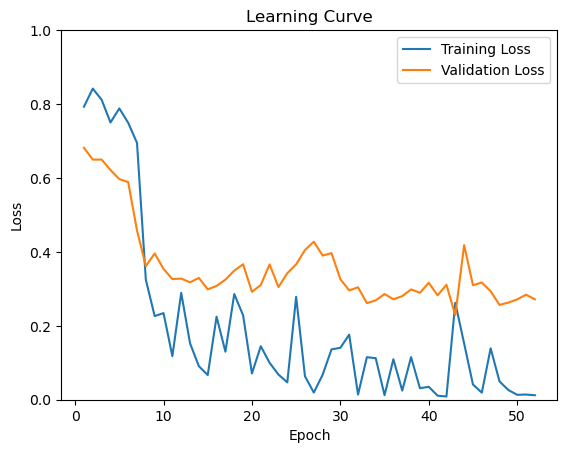

Accuracy: 0.7777777910232544. Recall: 0.5. Precision: 1.0
Fold 2
Best epoc: 42. Best val loss: 0.30954164266586304


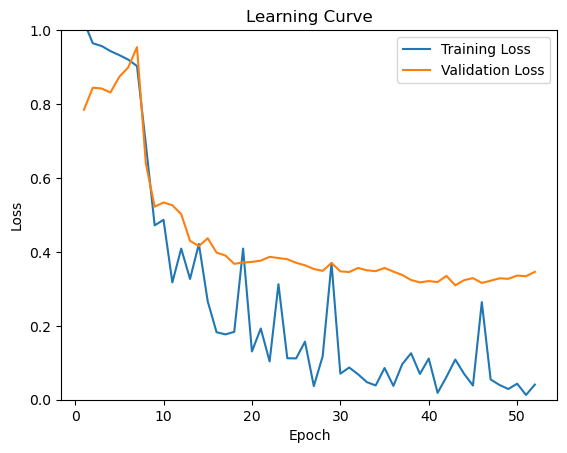

Accuracy: 0.7777777910232544. Recall: 0.75. Precision: 0.75
Fold 3
Best epoc: 51. Best val loss: 0.5010876059532166


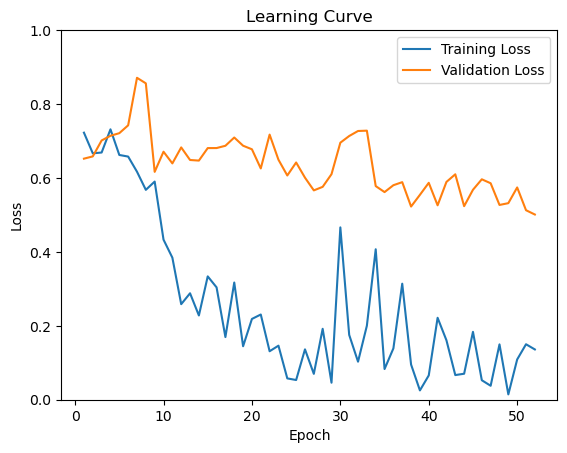

Accuracy: 0.7777777910232544. Recall: 1.0. Precision: 0.6666666865348816
Fold 4
Best epoc: 42. Best val loss: 0.05631806328892708


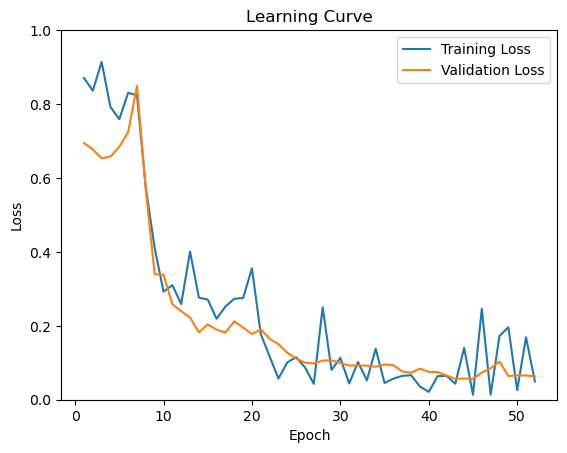

Accuracy: 0.8888888955116272. Recall: 1.0. Precision: 0.800000011920929
Fold 5
Best epoc: 45. Best val loss: 0.43573081493377686


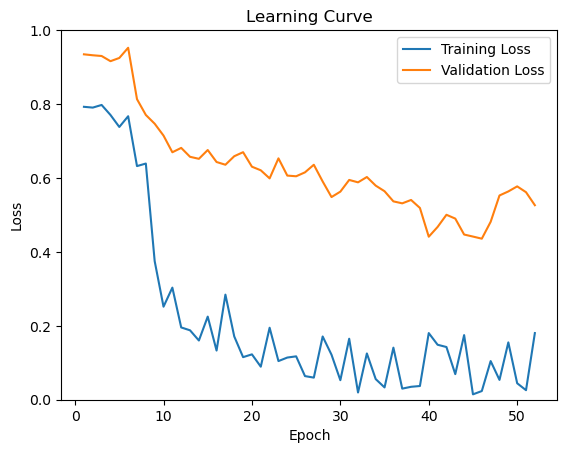

Accuracy: 1.0. Recall: 1.0. Precision: 1.0
Fold 1
Best epoc: 50. Best val loss: 0.06594792753458023


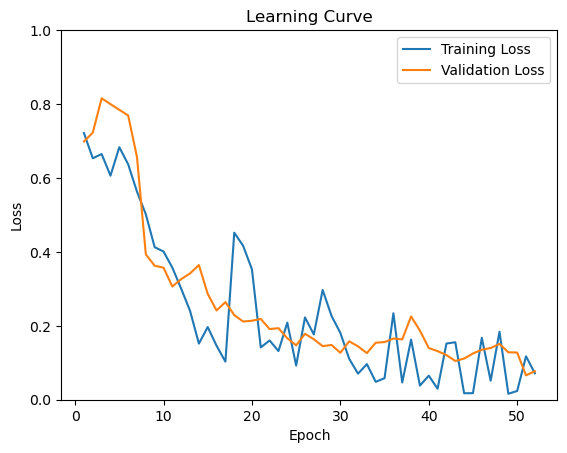

Accuracy: 0.8888888955116272. Recall: 0.75. Precision: 1.0
Fold 2
Best epoc: 51. Best val loss: 0.3391684293746948


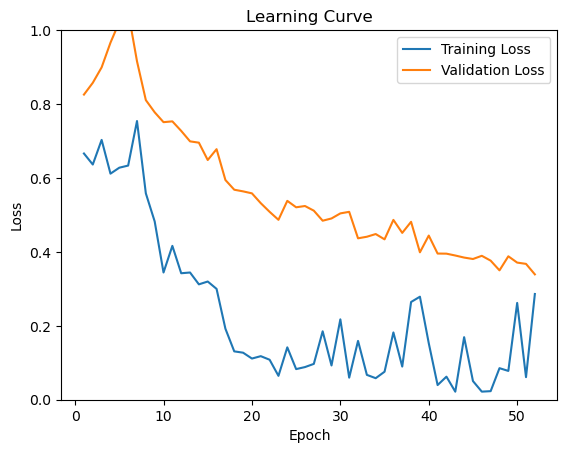

Accuracy: 0.8888888955116272. Recall: 1.0. Precision: 0.800000011920929
Fold 3
Best epoc: 50. Best val loss: 0.14850807189941406


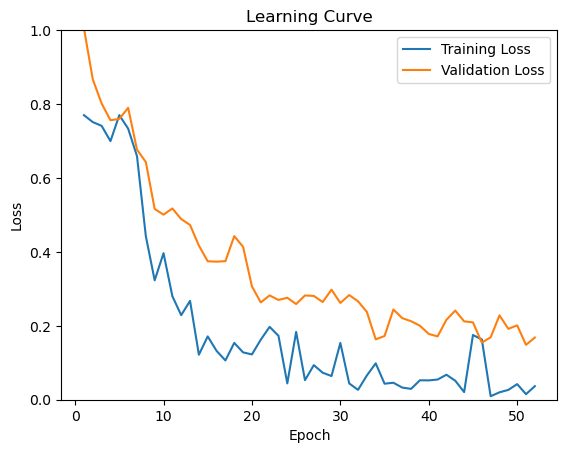

Accuracy: 0.7777777910232544. Recall: 0.75. Precision: 0.75
Fold 4
Best epoc: 38. Best val loss: 0.13533300161361694


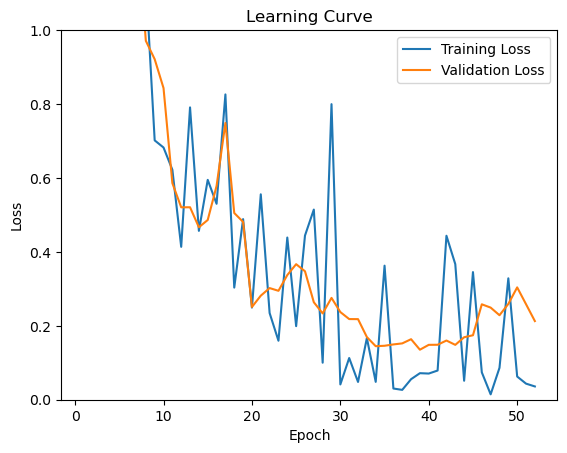

Accuracy: 0.8888888955116272. Recall: 0.75. Precision: 1.0
Fold 5
Best epoc: 14. Best val loss: 0.3852088451385498


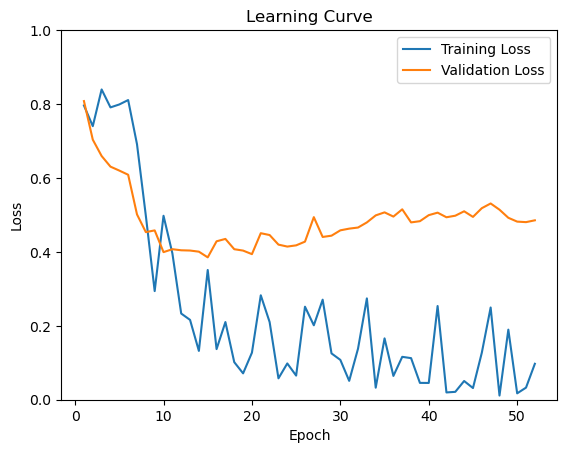

Accuracy: 0.625. Recall: 0.25. Precision: 1.0
Fold 1
Best epoc: 51. Best val loss: 0.08764857798814774


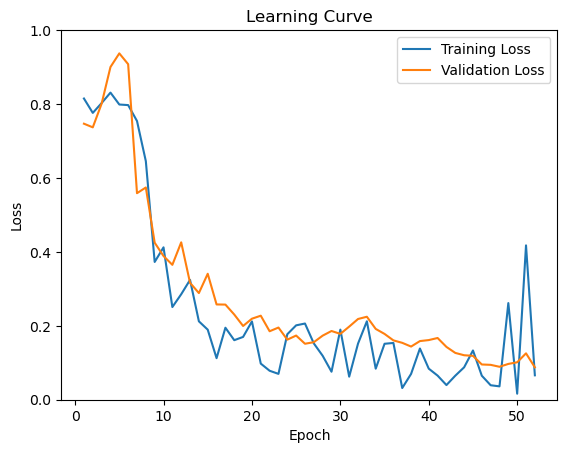

Accuracy: 1.0. Recall: 1.0. Precision: 1.0
Fold 2
Best epoc: 45. Best val loss: 0.1525944322347641


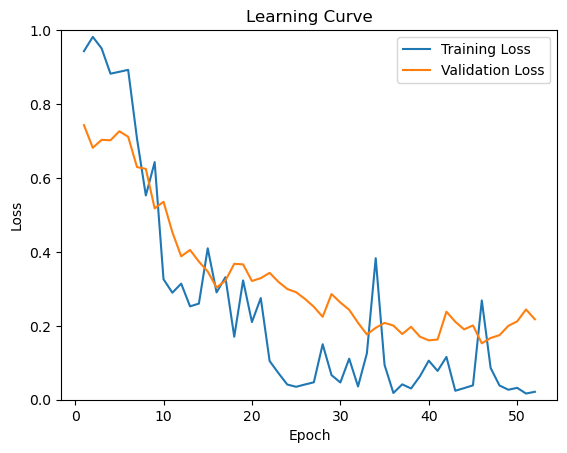

Accuracy: 0.8888888955116272. Recall: 0.75. Precision: 1.0
Fold 3
Best epoc: 39. Best val loss: 0.2469404637813568


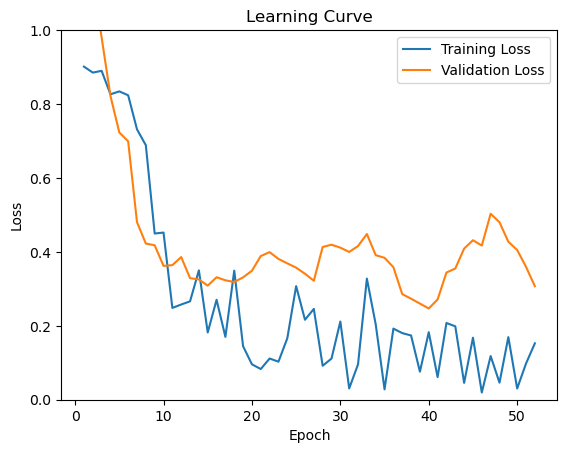

Accuracy: 0.8888888955116272. Recall: 1.0. Precision: 0.800000011920929
Fold 4
Best epoc: 11. Best val loss: 0.6924900412559509


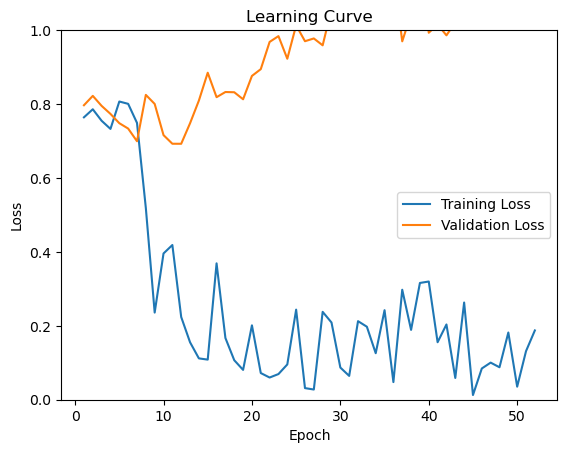

Accuracy: 0.7777777910232544. Recall: 0.5. Precision: 1.0
Fold 5
Best epoc: 45. Best val loss: 0.09344117343425751


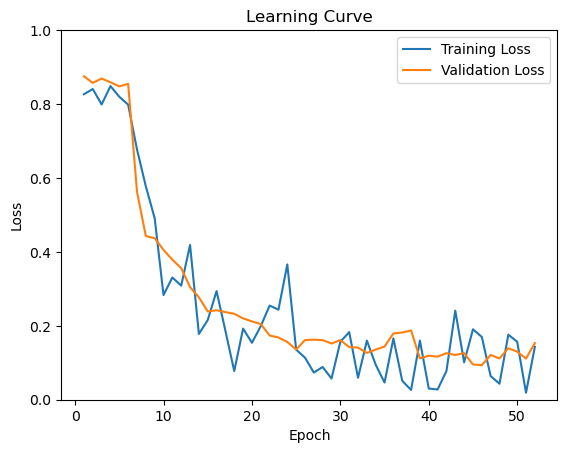

Accuracy: 0.75. Recall: 0.75. Precision: 0.75
Fold 1
Best epoc: 41. Best val loss: 0.05007905885577202


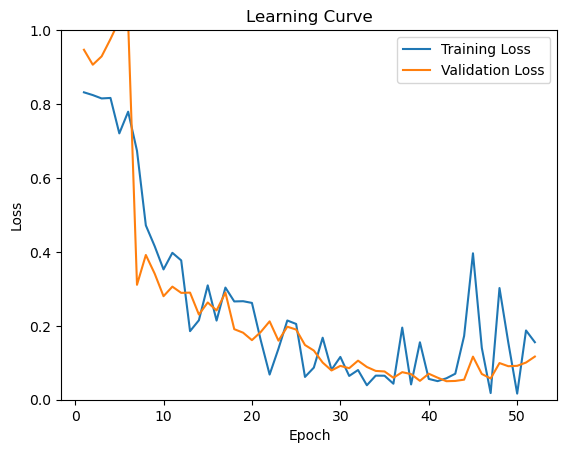

Accuracy: 0.8888888955116272. Recall: 1.0. Precision: 0.800000011920929
Fold 2
Best epoc: 47. Best val loss: 0.43798694014549255


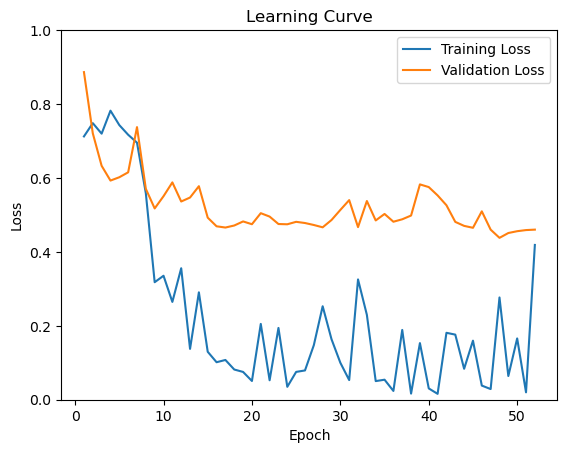

Accuracy: 0.7777777910232544. Recall: 0.75. Precision: 0.75
Fold 3
Best epoc: 50. Best val loss: 0.05612922087311745


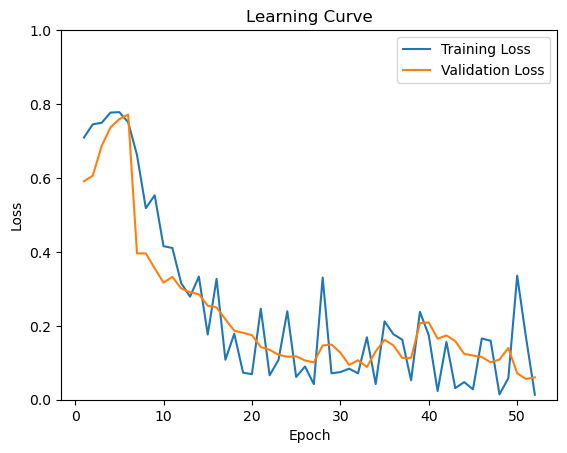

Accuracy: 0.7777777910232544. Recall: 0.75. Precision: 0.75
Fold 4
Best epoc: 45. Best val loss: 0.1765258014202118


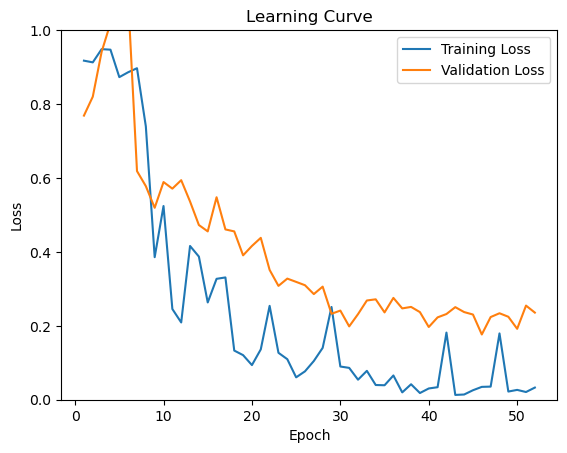

Accuracy: 0.8888888955116272. Recall: 0.75. Precision: 1.0
Fold 5
Best epoc: 48. Best val loss: 0.1514042615890503


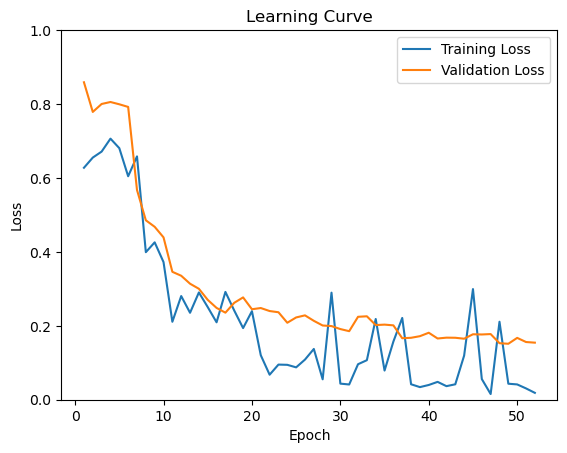

Accuracy: 0.875. Recall: 1.0. Precision: 0.800000011920929
Fold 1
Best epoc: 14. Best val loss: 0.42793571949005127


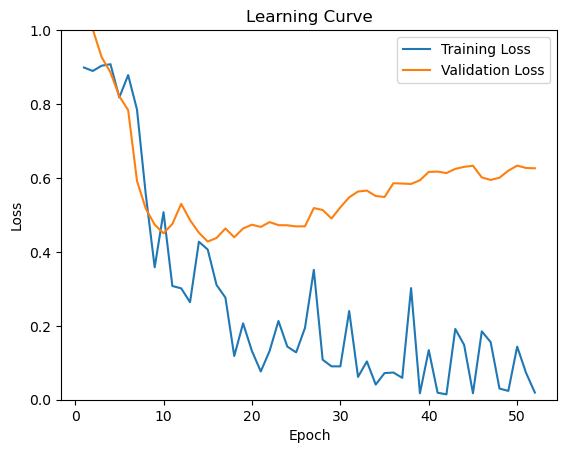

Accuracy: 0.6666666865348816. Recall: 1.0. Precision: 0.5714285969734192
Fold 2
Best epoc: 50. Best val loss: 0.06864132732152939


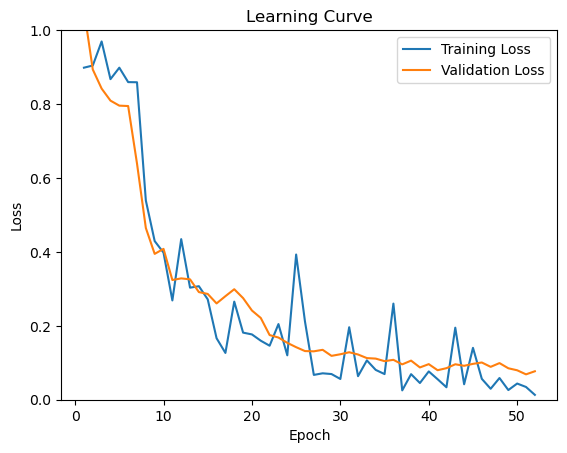

Accuracy: 0.6666666865348816. Recall: 0.5. Precision: 0.6666666865348816
Fold 3
Best epoc: 35. Best val loss: 0.335238516330719


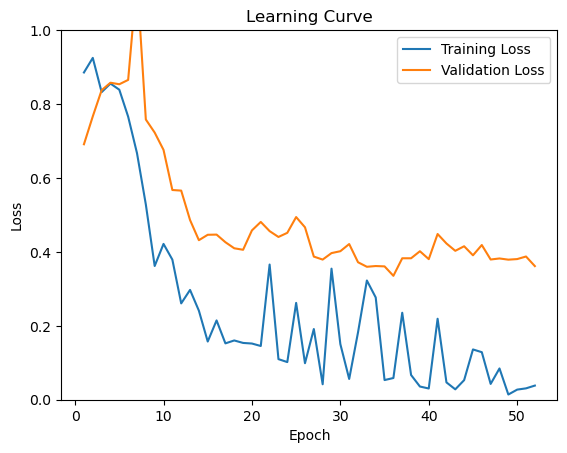

Accuracy: 1.0. Recall: 1.0. Precision: 1.0
Fold 4
Best epoc: 47. Best val loss: 0.09326710551977158


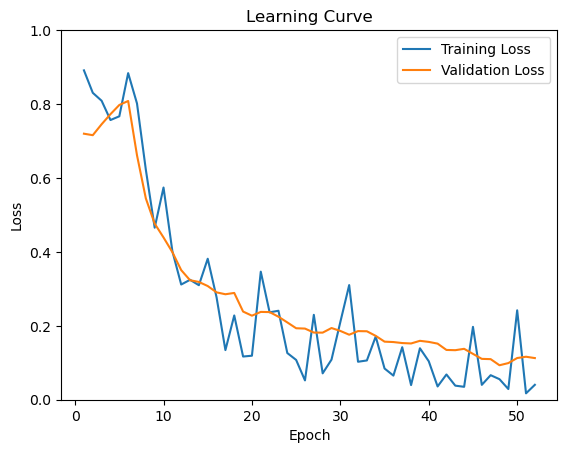

Accuracy: 0.8888888955116272. Recall: 0.75. Precision: 1.0
Fold 5
Best epoc: 43. Best val loss: 0.1018650010228157


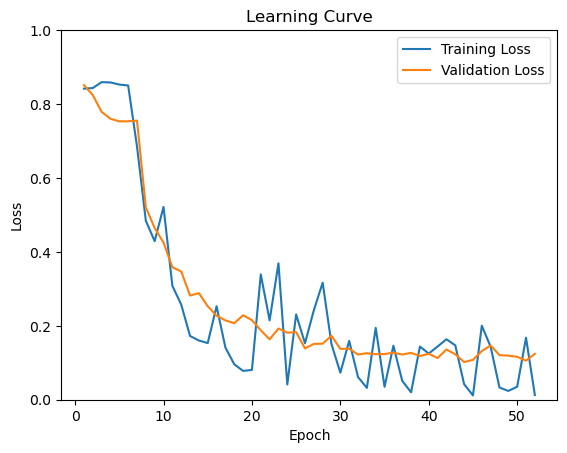

Accuracy: 0.875. Recall: 0.75. Precision: 1.0
ACCS: [0.8444444537162781, 0.8138888955116272, 0.8611111164093017, 0.8416666746139526, 0.819444453716278]
RECS: [0.85, 0.7, 0.8, 0.85, 0.8]
PRECS: [0.84333336, 0.91, 0.91, 0.82, 0.84761906]
F1S: [0.8466535395653977, 0.7913043710047766, 0.8514620217337352, 0.8347305327669917, 0.823121458799253]
STD-ACC: [0.08888888359069824, 0.10378634468461889, 0.0895806400048626, 0.052411002217552065, 0.13205403954656564]
STD-REC: [0.2, 0.24494897, 0.18708287, 0.12247449, 0.18708286]
STD-PREC: [0.13482498, 0.11135528, 0.11135528, 0.092736185, 0.18904221]
ACC: 0.8361111187934875
0.01730267889423569
0.021463989609238416
RECALL: 0.7999999523162842
PRECISION: 0.8661905527114868
F1: 0.8294543847740309
STD-ACC: 0.0933441820088595
STD-REC: 0.18831785023212433
STD-PREC: 0.12786278128623962


In [8]:
accs = []
recs = []
precs = []
f1 = []
std_accs = []
std_recs = []
std_precs = []
seeds = random.sample(range(1,10001), 100)

seeds_tr = [random.sample(range(1,10001), 5) for _ in range(100)]
for i in range(5):
    acc, rec, prec, std_acc, std_rec, std_prec = prueba_k_fold_resnet_pre_impr_fin(df_mosaic, 5, 6, 46, optim.RMSprop, 5, 7.469421266996221e-06, True, 'O', seeds[0], seeds_tr[0])
    accs.append(acc)
    recs.append(rec)
    precs.append(prec)
    std_accs.append(std_acc)
    std_recs.append(std_rec)
    std_precs.append(std_prec)
    f1.append(2*(rec*prec)/(rec+prec))
    seeds.pop(0)
    seeds_tr.pop(0)

print(f"ACCS: {accs}")
print(f"RECS: {recs}")
print(f"PRECS: {precs}")
print(f"F1S: {f1}")

print(f"STD-ACC: {std_accs}")
print(f"STD-REC: {std_recs}")
print(f"STD-PREC: {std_precs}")

print(f"ACC: {np.mean(accs)}")
print(np.std(accs))
print(np.std(f1))
print(f"RECALL: {np.mean(recs)}")
print(f"PRECISION: {np.mean(precs)}")
print(f"F1: {np.mean(f1)}")
print(f"STD-ACC: {np.mean(std_accs)}")
print(f"STD-REC: {np.mean(std_recs)}")
print(f"STD-PREC: {np.mean(std_precs)}")

Fold 1
Best epoc: 52. Best val loss: 0.20434322953224182


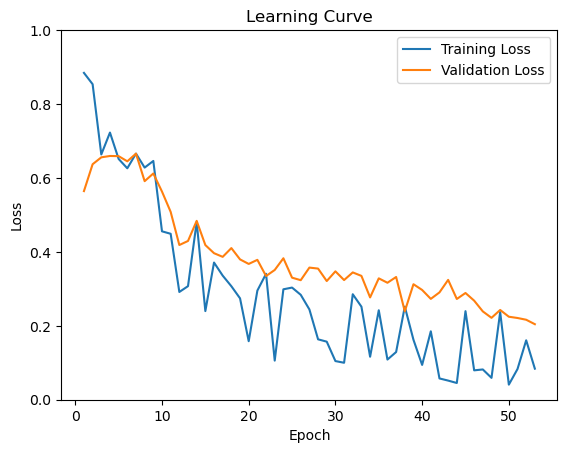

Accuracy: 0.8888888955116272. Recall: 1.0. Precision: 0.800000011920929
Fold 2
Best epoc: 43. Best val loss: 0.2173219919204712


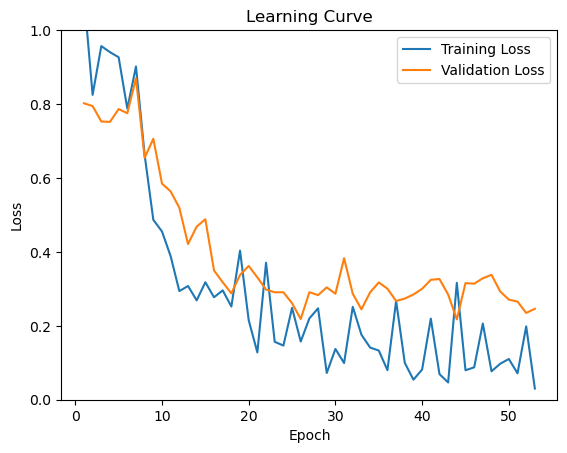

Accuracy: 0.8888888955116272. Recall: 1.0. Precision: 0.800000011920929
Fold 3
Best epoc: 38. Best val loss: 0.2357204258441925


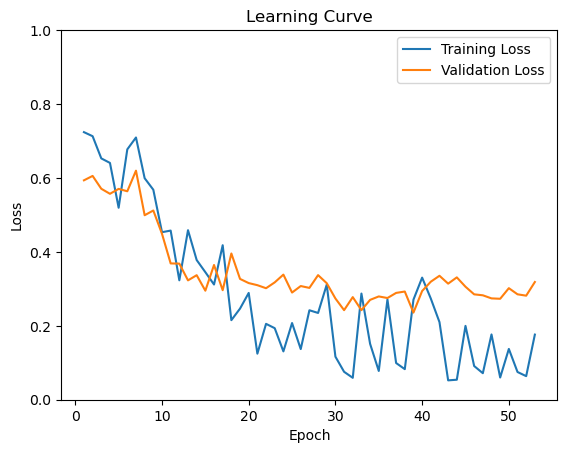

Accuracy: 0.8888888955116272. Recall: 0.75. Precision: 1.0
Fold 4
Best epoc: 52. Best val loss: 0.49369576573371887


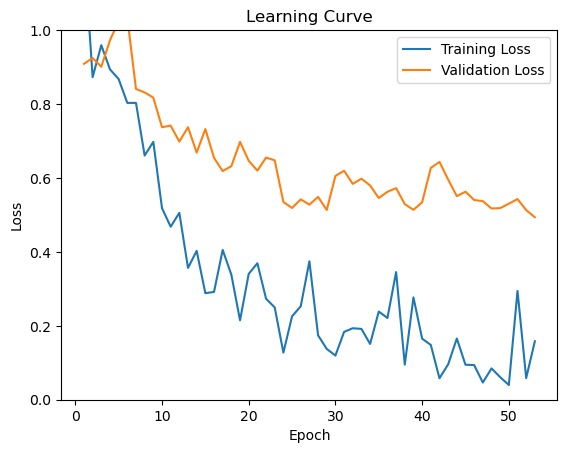

Accuracy: 0.7777777910232544. Recall: 0.5. Precision: 1.0
Fold 5
Best epoc: 52. Best val loss: 0.11131097376346588


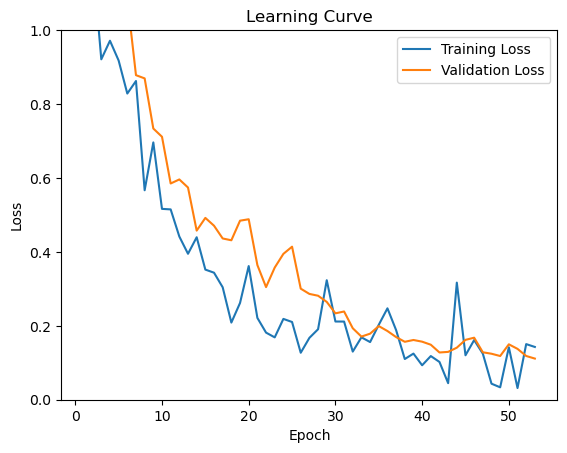

Accuracy: 0.875. Recall: 0.75. Precision: 1.0
Fold 1
Best epoc: 48. Best val loss: 0.3936997354030609


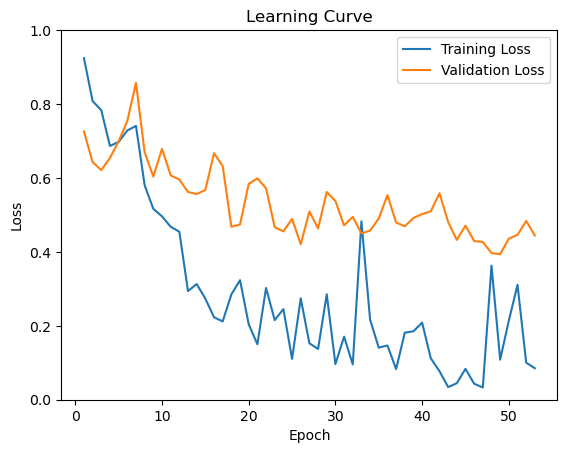

Accuracy: 0.7777777910232544. Recall: 0.75. Precision: 0.75
Fold 2
Best epoc: 42. Best val loss: 0.19169791042804718


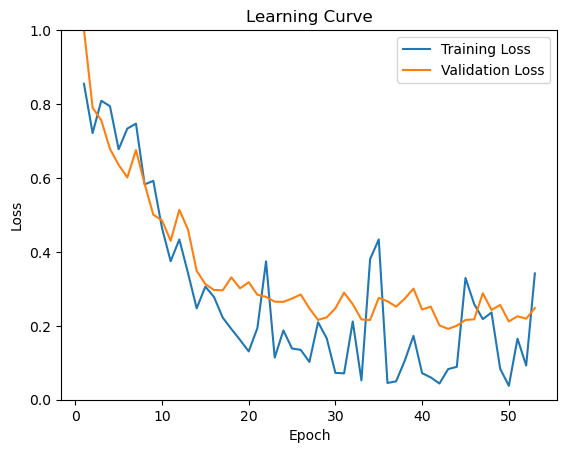

Accuracy: 0.6666666865348816. Recall: 0.5. Precision: 0.6666666865348816
Fold 3
Best epoc: 6. Best val loss: 0.6608473062515259


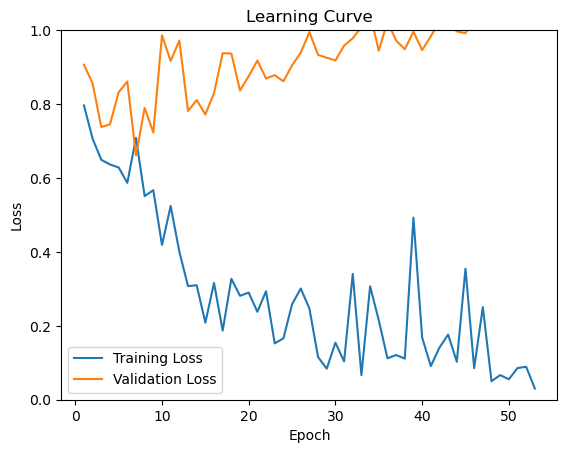

Accuracy: 0.4444444477558136. Recall: 0.0. Precision: 0.0
Fold 4
Best epoc: 20. Best val loss: 0.3287737965583801


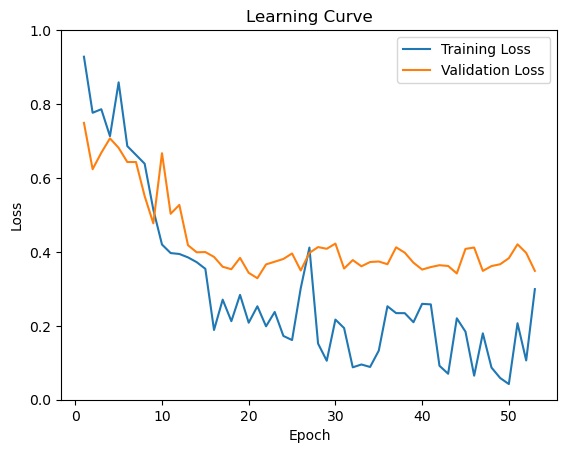

Accuracy: 0.7777777910232544. Recall: 0.5. Precision: 1.0
Fold 5
Best epoc: 34. Best val loss: 0.37187719345092773


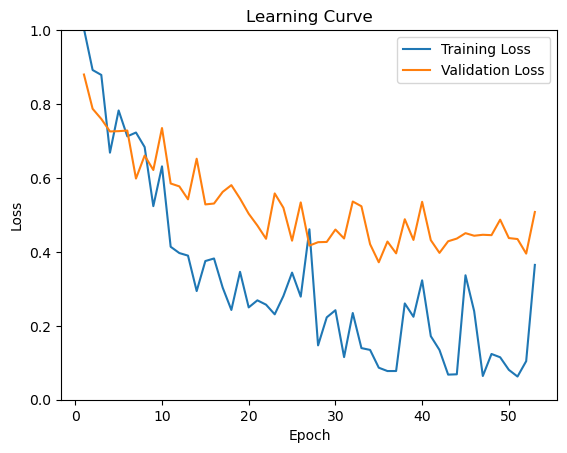

Accuracy: 1.0. Recall: 1.0. Precision: 1.0
Fold 1
Best epoc: 44. Best val loss: 0.351178377866745


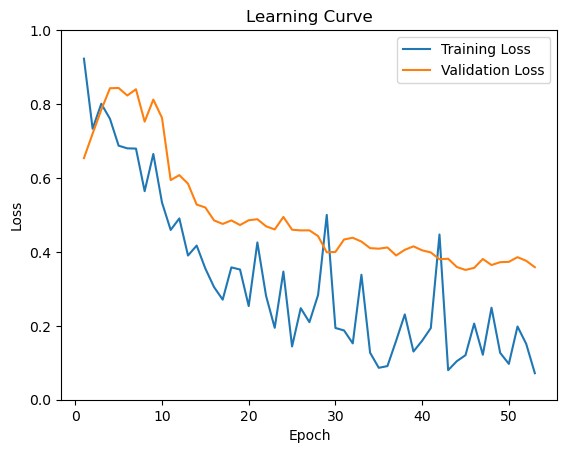

Accuracy: 1.0. Recall: 1.0. Precision: 1.0
Fold 2
Best epoc: 52. Best val loss: 0.13129326701164246


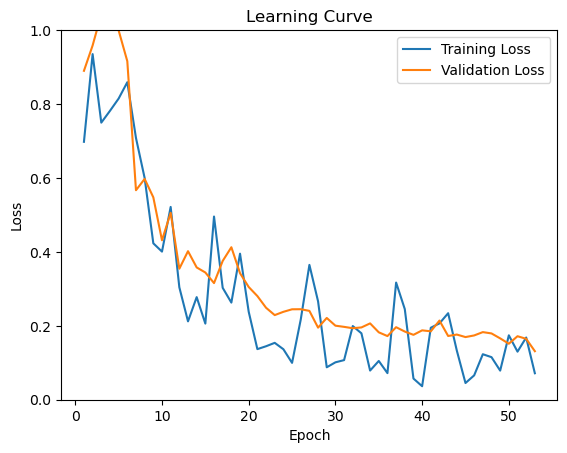

Accuracy: 0.6666666865348816. Recall: 0.5. Precision: 0.6666666865348816
Fold 3
Best epoc: 51. Best val loss: 0.18522919714450836


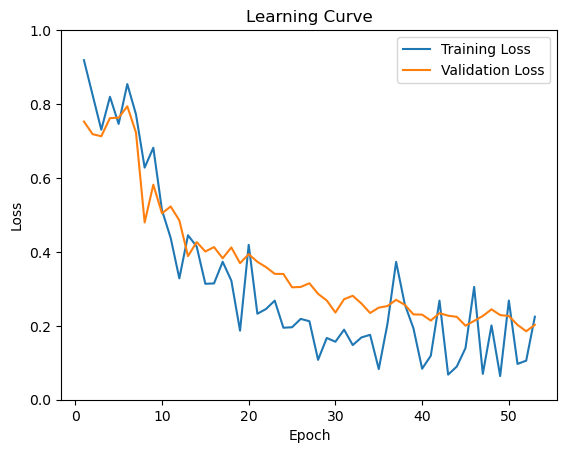

Accuracy: 0.7777777910232544. Recall: 0.5. Precision: 1.0
Fold 4
Best epoc: 49. Best val loss: 0.2726086974143982


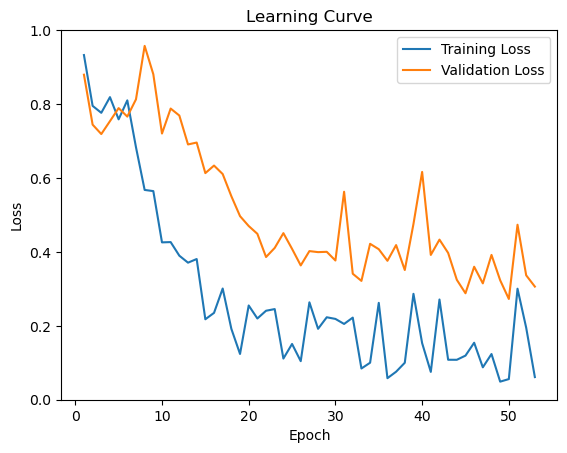

Accuracy: 0.8888888955116272. Recall: 0.75. Precision: 1.0
Fold 5
Best epoc: 50. Best val loss: 0.03399484604597092


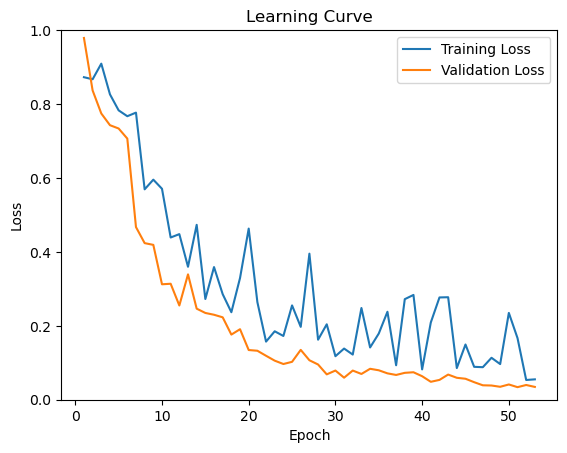

Accuracy: 1.0. Recall: 1.0. Precision: 1.0
Fold 1
Best epoc: 20. Best val loss: 0.2197416126728058


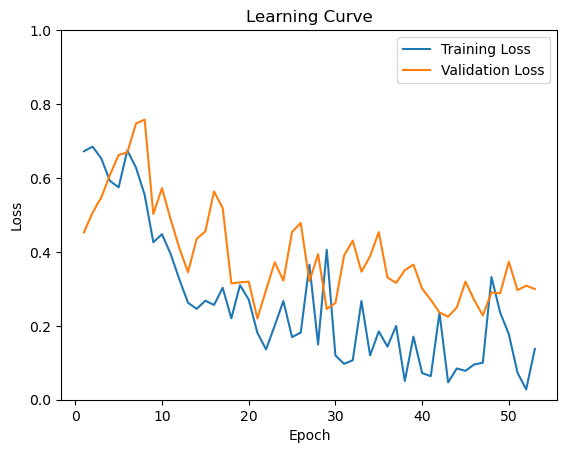

Accuracy: 0.6666666865348816. Recall: 0.5. Precision: 0.6666666865348816
Fold 2
Best epoc: 51. Best val loss: 0.4484170079231262


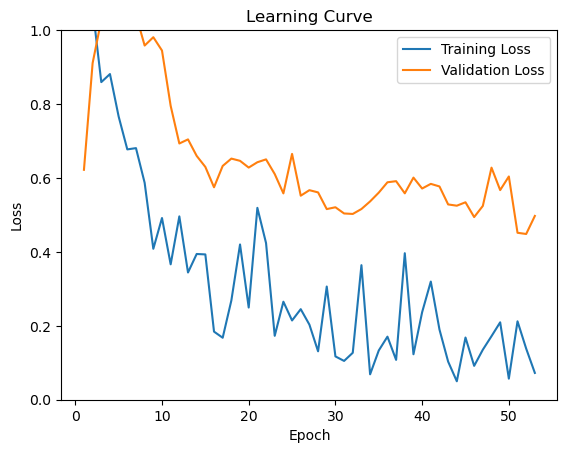

Accuracy: 0.7777777910232544. Recall: 0.5. Precision: 1.0
Fold 3
Best epoc: 30. Best val loss: 0.4306567311286926


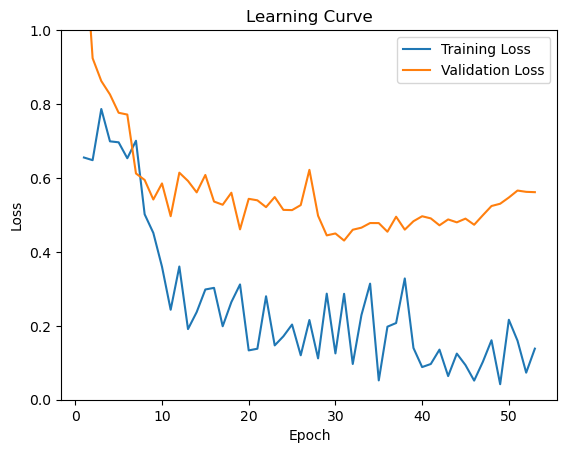

Accuracy: 0.8888888955116272. Recall: 0.75. Precision: 1.0
Fold 4
Best epoc: 47. Best val loss: 0.2844703197479248


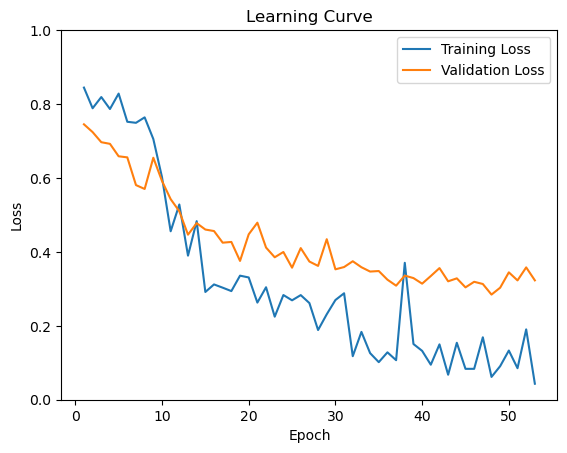

Accuracy: 0.8888888955116272. Recall: 0.75. Precision: 1.0
Fold 5
Best epoc: 15. Best val loss: 0.7458293437957764


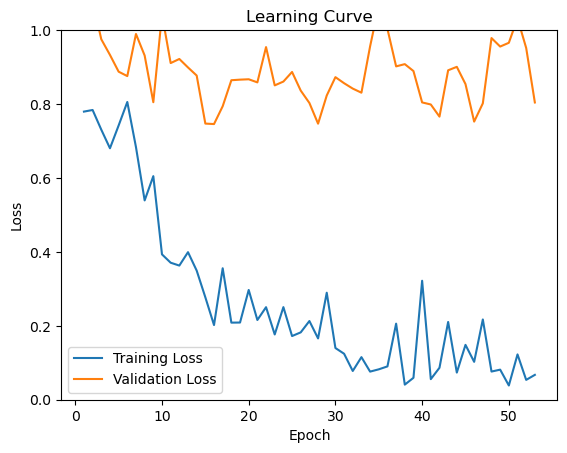

Accuracy: 0.75. Recall: 0.75. Precision: 0.75
Fold 1
Best epoc: 28. Best val loss: 0.2824537754058838


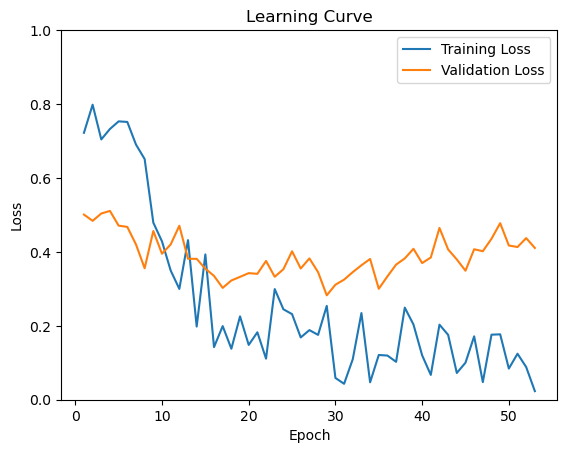

Accuracy: 0.8888888955116272. Recall: 0.75. Precision: 1.0
Fold 2
Best epoc: 0. Best val loss: 0.524370014667511


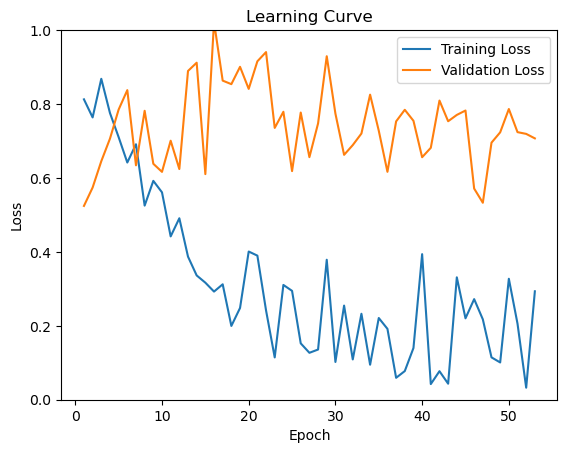

Accuracy: 0.6666666865348816. Recall: 0.5. Precision: 0.6666666865348816
Fold 3
Best epoc: 46. Best val loss: 0.1582476794719696


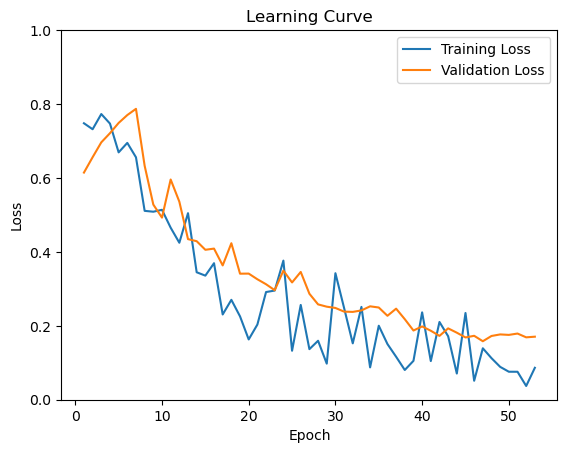

Accuracy: 0.8888888955116272. Recall: 0.75. Precision: 1.0
Fold 4
Best epoc: 52. Best val loss: 0.23976559937000275


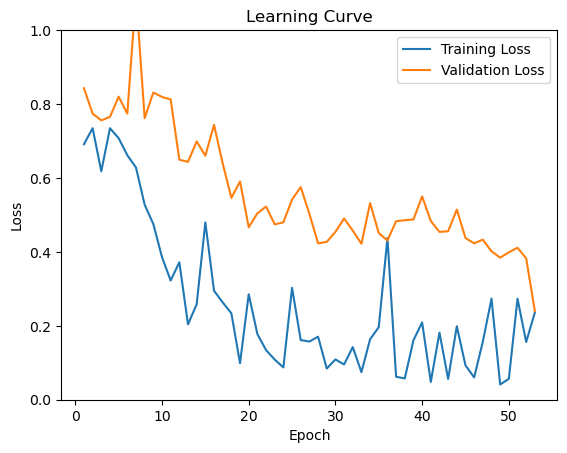

Accuracy: 0.8888888955116272. Recall: 0.75. Precision: 1.0
Fold 5
Best epoc: 49. Best val loss: 0.34734195470809937


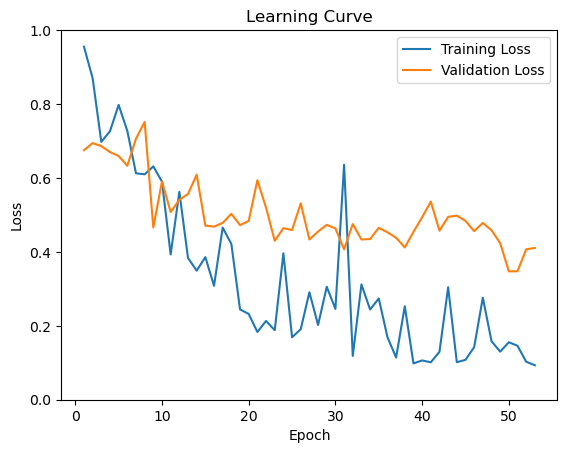

Accuracy: 1.0. Recall: 1.0. Precision: 1.0
ACCS: [0.8638888955116272, 0.7333333432674408, 0.8666666746139526, 0.794444453716278, 0.8666666746139526]
RECS: [0.8, 0.55, 0.75, 0.65, 0.75]
PRECS: [0.91999996, 0.68333334, 0.9333334, 0.8833334, 0.9333334]
F1S: [0.855813940916273, 0.6094594503163073, 0.8316831935586761, 0.7489130444923285, 0.8316831935586761]
STD-ACC: [0.04339027300941767, 0.18053418554688405, 0.1295767010509663, 0.08534606033015789, 0.10886620430143165]
STD-REC: [0.18708286, 0.33166248, 0.2236068, 0.12247449, 0.15811388]
STD-PREC: [0.09797959, 0.36666667, 0.13333333, 0.14529663, 0.13333333]
ACC: 0.8250000083446503
0.05351819710361221
0.09059774982502063
RECALL: 0.699999988079071
PRECISION: 0.8706666827201843
F1: 0.7755105645684522
STD-ACC: 0.10954268484777152
STD-REC: 0.20458810031414032
STD-PREC: 0.17532190680503845


In [9]:
accs = []
recs = []
precs = []
f1 = []
std_accs = []
std_recs = []
std_precs = []
seeds = random.sample(range(1,10001), 100)

seeds_tr = [random.sample(range(1,10001), 5) for _ in range(100)]
for i in range(5):
    acc, rec, prec, std_acc, std_rec, std_prec = prueba_k_fold_resnet_pre_impr_fin(df_mosaic, 5, 6, 47, optim.SGD, 5, 0.0010020371119832776, True, 'G', seeds[0], seeds_tr[0])
    accs.append(acc)
    recs.append(rec)
    precs.append(prec)
    std_accs.append(std_acc)
    std_recs.append(std_rec)
    std_precs.append(std_prec)
    f1.append(2*(rec*prec)/(rec+prec))
    seeds.pop(0)
    seeds_tr.pop(0)

print(f"ACCS: {accs}")
print(f"RECS: {recs}")
print(f"PRECS: {precs}")
print(f"F1S: {f1}")

print(f"STD-ACC: {std_accs}")
print(f"STD-REC: {std_recs}")
print(f"STD-PREC: {std_precs}")

print(f"ACC: {np.mean(accs)}")
print(np.std(accs))
print(np.std(f1))
print(f"RECALL: {np.mean(recs)}")
print(f"PRECISION: {np.mean(precs)}")
print(f"F1: {np.mean(f1)}")
print(f"STD-ACC: {np.mean(std_accs)}")
print(f"STD-REC: {np.mean(std_recs)}")
print(f"STD-PREC: {np.mean(std_precs)}")